# GA–TSP: Memetic Genetic Algorithm and Logging-Based Explanations (corrected)

**Thesis:** *Logging-based Explanations of Genetic Algorithm Search for the Symmetric Traveling Salesman Problem* — P. Esipenko, BSc Business Analytics, UvA.

This is the corrected, execution-ready notebook. Main changes vs. the previous version:

1. **Per-instance grid search** is resumable (skips instances whose CSV already exists) and **parallelized** over the 27 parameter combinations.
2. **Experiments A/B pin `tournament_size = 5`** explicitly (controlled operator-comparison baseline, independent of the tuned configurations).
3. **2-opt closing-edge fix:** the full 2-opt now also considers moves that remove the closing edge `(tour[n-1], tour[0])`; only the degenerate pair `(i=0, j=n-1)` is skipped. Neighbour-list 2-opt (k=15) is kept for large instances and is documented as an *approximate* 2-opt (no strict local-optimality claim).
4. **`SearchLog` tags synthetic entries** (injected by `ensure_best`) and all explanation methods exclude them.
5. **Corrected contrastive analysis:** edge-level contrastive evidence is computed *within the near-optimal pool* (removes the generation-stage confound), reports the share of tours containing each edge, and warns when the "without" group is too small. The legacy all-generations variant is kept only for comparison. The method is observational — *not* a counterfactual explanation.
6. **New diverse-tours figure:** global best + alternatives with grey = shared / red = differing edges, per-panel length, gap and number of differing edges, mean pairwise Jaccard distance.
7. **New (light) partial-solution analysis:** stable subpaths of the best tour whose edges appear in ≥ 80% of near-optimal tours.
8. **Outputs** are written to `thesis_outputs/tables/`, `thesis_outputs/figures/`, `thesis_outputs/logs/` (mirrored to Drive when on Colab).
9. Stale/duplicate cells removed; heavy computation separated from plotting; `QUICK_TEST` switch added for a fast pipeline check.

## How to run
1. Run **Section 0** first; on Colab it mounts Drive.
2. Set switches in **cell 0.2**: `RUN_HEAVY=True` for the full thesis run; optionally set `QUICK_TEST=True` once to verify the pipeline (~2–5 min), then set it back to `False` and **Runtime → Run all**.
3. Approximate full-run wall-clock on Colab Pro (A100/high-RAM CPU): grid search ≈ 10–30 min (parallel); Experiments A/B ≈ 15–25 min; single-seed runs ≈ 2.5–3 h (pr1002 dominates, ≈ 90 min); robustness ≈ 1–2 h (parallel over seeds); explanations ≈ 15–30 min. **Total ≈ 4–6 h.** Interrupted runs can be resumed: completed grid instances, single-seed runs and robustness instances are loaded from saved files instead of recomputed.


## 0. Setup

In [ ]:
# 0.1 Environment and Drive
import os, sys, platform, multiprocessing, time as _time, json as _json, datetime

try:
    import google.colab
    ON_COLAB = True
    from google.colab import drive
    drive.mount('/content/drive', force_remount=False)
    BASE_DIR = '/content/drive/MyDrive/GA_TSP_thesis_outputs'
except ImportError:
    ON_COLAB = False
    BASE_DIR = './GA_TSP_thesis_outputs'

SUBDIRS = ['config','grid_search','single_seed','robustness',
           'experiment_A','experiment_B','explanations','logs','figures','tables']
for s in SUBDIRS:
    os.makedirs(f'{BASE_DIR}/{s}', exist_ok=True)
os.makedirs('thesis_outputs', exist_ok=True)

N_CORES = multiprocessing.cpu_count()
print(f"Colab         : {ON_COLAB}")
print(f"CPUs          : {N_CORES}")
print(f"Python        : {sys.version.split()[0]}")
print(f"Output dir    : {BASE_DIR}")

try:
    from numba import njit
    NUMBA_AVAILABLE = True
    print("Numba         : available")
except ImportError:
    NUMBA_AVAILABLE = False
    print("Numba         : not available (pure Python 2-opt)")


Mounted at /content/drive
Colab         : True
CPUs          : 2
Python        : 3.12.13
Output dir    : /content/drive/MyDrive/GA_TSP_thesis_outputs
Numba         : available


In [ ]:
# 0.2 Run switches
# RUN_HEAVY  = True  -> compute kroA200, rd400, rat575, pr1002 (Colab Pro recommended)
# RUN_HEAVY  = False -> load saved Drive/local results for those instances
# QUICK_TEST = True  -> shrink every budget to verify the whole pipeline end-to-end
#                       in a few minutes. Results are NOT thesis-valid. Set back to
#                       False (and delete thesis_outputs/) before the real run.
# FORCE_RERUN = True -> ignore saved results and recompute everything.
RUN_HEAVY   = True
QUICK_TEST  = False
FORCE_RERUN = False

SEED  = 42
SEEDS = list(range(10, 20))          # robustness: 10 seeds
if QUICK_TEST:
    SEEDS = [10, 11]

print(f"RUN_HEAVY   = {RUN_HEAVY}")
print(f"QUICK_TEST  = {QUICK_TEST}")
print(f"FORCE_RERUN = {FORCE_RERUN}")
print(f"SEED        = {SEED}")
print(f"SEEDS       = {SEEDS}")


RUN_HEAVY   = True
QUICK_TEST  = False
FORCE_RERUN = False
SEED        = 42
SEEDS       = [10, 11, 12, 13, 14, 15, 16, 17, 18, 19]


In [ ]:
# 0.3 I/O utilities
# Local outputs:   thesis_outputs/{tables,figures,logs}/
# Drive mirror:    BASE_DIR/{subdir}/   (when available)
import matplotlib
if not ON_COLAB:
    matplotlib.use('Agg')            # keep inline rendering on Colab
import matplotlib.pyplot as plt

LOCAL_DIRS = {'tables': 'thesis_outputs/tables',
              'figures': 'thesis_outputs/figures',
              'logs':    'thesis_outputs/logs'}
for d in LOCAL_DIRS.values():
    os.makedirs(d, exist_ok=True)

def _drive_path(filename, subdir):
    return f'{BASE_DIR}/{subdir}/{filename}'

def _local_path(filename, kind):
    return f"{LOCAL_DIRS[kind]}/{filename}"

def save_fig(filename, dpi=150, subdir='figures'):
    path_local = _local_path(filename, 'figures')
    plt.savefig(path_local, dpi=dpi, bbox_inches='tight')
    try:
        plt.savefig(_drive_path(filename, subdir), dpi=dpi, bbox_inches='tight')
    except Exception:
        pass
    print(f"Figure saved: {path_local}")

def save_json(obj, filename, subdir='logs'):
    path = _local_path(filename, 'logs')
    with open(path, 'w') as f:
        _json.dump(obj, f, indent=2)
    try:
        with open(_drive_path(filename, subdir), 'w') as f:
            _json.dump(obj, f, indent=2)
    except Exception:
        pass

def save_csv(df, filename, subdir='tables'):
    path = _local_path(filename, 'tables')
    df.to_csv(path, index=False)
    try:
        df.to_csv(_drive_path(filename, subdir), index=False)
    except Exception:
        pass
    print(f"CSV saved: {path}")

def load_json(filename, subdir='logs'):
    for path in [_drive_path(filename, subdir), _local_path(filename, 'logs')]:
        if os.path.exists(path):
            with open(path) as f:
                return _json.load(f)
    return None

def load_csv(filename, subdir='tables'):
    import pandas as _pd
    for path in [_drive_path(filename, subdir), _local_path(filename, 'tables')]:
        if os.path.exists(path):
            return _pd.read_csv(path)
    return None

print("I/O utilities ready. Local outputs ->", ", ".join(LOCAL_DIRS.values()))


I/O utilities ready. Local outputs -> thesis_outputs/tables, thesis_outputs/figures, thesis_outputs/logs


## 1. Imports and Configuration

In [ ]:
import numpy as np
import pandas as pd
import math, time, random, itertools
from collections import defaultdict
import time as _time
import matplotlib.cm as cm
import matplotlib.pyplot as plt

In [ ]:
# CONFIG_BASE holds the fixed hyperparameters (not tuned by grid search).
# population_size, mutation_prob and tournament_size are set per-instance
# by the grid search in Section 6.

CONFIG_BASE = {
    'n_generations'         : 2000,
    'crossover_prob'        : 0.90,
    'elite_size'            : 5,      # Elitism mechanism: Potvin (1996); value set a priori
    'near_optimal_threshold': 0.05,   # cutoff for the near-optimal tour pool
                                      # (renamed from 'diversity_threshold' — Daan, p.14)
    'log_every'             : 5,
}

# Patience values scaled to instance size (empirical; principle: Talbi, 2009).
PATIENCE_SCALE = {
    'berlin52': 100,
    'eil76'   : 150,
    'rat99'   : 200,
    'kroA100' : 200,
    'kroA200' : 400,
    'rd400'   : 500,
    'rat575'  : 550,
    'pr1002'  : 600,
}

if QUICK_TEST:
    CONFIG_BASE['n_generations'] = 8
    PATIENCE_SCALE = {k: 5 for k in PATIENCE_SCALE}

# CONFIGS is populated by the per-instance grid search in Section 6.
CONFIGS = {}

# Fallback CONFIG (used only if Section 6 has not been run).
CONFIG = {
    **CONFIG_BASE,
    'population_size': 200,
    'mutation_prob'  : 0.02,
    'tournament_size': 3,
    'patience'       : PATIENCE_SCALE['berlin52'],
}
if QUICK_TEST:
    CONFIG['population_size'] = 20

print("CONFIG_BASE and PATIENCE_SCALE ready.")
print("CONFIGS will be populated in Section 6 (per-instance grid search).")


CONFIG_BASE and PATIENCE_SCALE ready.
CONFIGS will be populated in Section 6 (per-instance grid search).


## 2. Instance Data

All coordinates are TSPLIB95 instances (Reinelt, 1991). Tour lengths follow the TSPLIB `EUC_2D` convention: pairwise Euclidean distances rounded to the nearest integer.

In [ ]:
BEST_KNOWN = {
    "berlin52": 7542,
    "eil76"   : 538,
    "rat99"   : 1211,   # Rattled grid (Pulleyblank) — Reinelt (1991)
    "kroA100" : 21282,
    "kroA200" : 29368,
    "rd400"   : 15281,  # Random instance — Reinelt (1991)
    "rat575"  : 6773,   # Rattled grid (Pulleyblank) — Reinelt (1991)
    "pr1002"  : 259045, # Padberg & Rinaldi (1987)
}
# All six thesis instances are pre-registered here.
# rat99 and rd400 coordinates are defined in Sections 5.7 and 9.

# berlin52 coordinates — source: TSPLIB95 berlin52.tsp
BERLIN52_COORDS = [
    (565,575),(25,185),(345,750),(945,685),(845,655),(880,660),
    (25,230),(525,1000),(580,1175),(650,1130),(1605,620),(1220,580),
    (1465,200),(1530,5),(845,680),(725,370),(145,665),(415,635),
    (510,875),(560,365),(300,465),(520,585),(480,415),(835,625),
    (975,580),(1215,245),(1320,315),(1250,400),(660,180),(410,250),
    (420,555),(575,665),(1150,1160),(700,580),(685,595),(685,610),
    (770,610),(795,645),(720,635),(760,650),(475,960),(95,260),
    (875,920),(700,500),(555,815),(830,485),(1170,65),(830,610),
    (605,625),(595,360),(1340,725),(1740,245)
]

# kroA100 coordinates — source: TSPLIB95 kroA100.tsp (Reinelt, 1991)
KROA100_COORDS = [
    (1380,939),(2848,96),(3510,1671),(457,334),(3888,666),(984,965),
    (2721,1482),(1286,525),(2716,1432),(738,1325),(1251,1832),(2118,2578),
    (1966,2176),(1463,1388),(3844,1418),(3918,2179),(243,1333),(1819,1862),
    (3110,2586),(2793,1683),(3273,1490),(3677,2045),(2941,2421),(3674,1566),
    (3956,1363),(925,1838),(1300,1833),(2746,1272),(2302,950),(2484,2573),
    (2649,1432),(3876,2198),(1390,1548),(2826,2516),(3041,2369),(3177,756),
    (2432,2563),(1285,1522),(1012,2447),(2590,2697),(3267,2379),(3581,1009),
    (2153,1478),(2388,1103),(957,1498),(2590,2941),(2624,1280),(3628,1162),
    (2026,2360),(2987,1390),(3327,2162),(1000,1783),(1573,2056),(1262,1978),
    (1728,1913),(2439,2571),(2197,1976),(2288,1842),(1982,1698),(2468,1863),
    (2791,1918),(1024,2405),(2587,1783),(1817,2022),(1413,1767),(986,2022),
    (2009,2390),(822,2110),(2774,1820),(2479,2303),(2704,1696),(2437,1986),
    (2300,1952),(2556,2210),(3253,1696),(2362,2178),(2401,2138),(2521,2045),
    (2477,2172),(2628,2079),(2374,2144),(2499,1980),(2625,2025),(2449,2106),
    (2573,1964),(2600,2087),(2501,2049),(2544,1945),(2454,2060),(2484,1932),
    (2589,2044),(2563,1950),(2581,2003),(2473,2034),(2529,1987),(2489,2013),
    (2545,1976),(2482,1976),(2533,2036),(2503,1709),
]


# rat575 coordinates — source: TSPLIB95 rat575.tsp (Pulleyblank rattled grid)
RAT575_COORDS = [
    (6,18),(11,0),(24,6),(36,13),(41,19),(51,5),
    (64,9),(71,15),(86,1),(95,1),(104,18),(119,14),
    (120,17),(132,8),(148,13),(158,20),(163,5),(178,11),
    (185,20),(196,19),(207,19),(217,9),(229,11),(5,32),
    (12,23),(28,27),(31,26),(45,34),(55,37),(67,23),
    (75,34),(85,35),(99,28),(108,21),(113,27),(122,40),
    (131,39),(141,40),(151,28),(166,27),(177,23),(182,22),
    (191,25),(203,32),(211,28),(224,24),(1,55),(18,42),
    (26,50),(38,49),(42,60),(57,42),(69,41),(79,55),
    (85,52),(95,48),(102,43),(114,42),(121,45),(135,55),
    (146,51),(159,47),(161,49),(171,48),(181,52),(194,52),
    (208,50),(214,52),(223,46),(1,71),(14,73),(25,61),
    (35,63),(42,65),(54,79),(65,69),(73,69),(81,70),
    (98,66),(105,60),(115,77),(125,65),(135,71),(143,77),
    (151,77),(162,65),(175,64),(187,74),(197,67),(202,68),
    (215,78),(225,62),(8,83),(16,89),(20,99),(34,85),
    (47,86),(56,86),(67,92),(78,84),(84,95),(99,93),
    (101,97),(115,92),(127,97),(132,87),(149,95),(156,100),
    (164,95),(171,81),(189,100),(198,89),(208,81),(216,92),
    (229,86),(1,100),(12,102),(22,113),(37,103),(48,104),
    (56,113),(68,119),(72,100),(81,110),(98,107),(103,103),
    (112,120),(130,120),(136,104),(142,120),(157,106),(164,112),
    (174,119),(184,101),(198,115),(202,115),(212,118),(229,101),
    (6,127),(12,140),(22,121),(31,132),(41,132),(53,124),
    (62,136),(80,126),(84,123),(98,126),(108,130),(115,134),
    (128,125),(136,133),(145,134),(152,131),(167,127),(171,135),
    (184,139),(199,124),(202,127),(217,128),(225,121),(8,148),
    (16,148),(27,149),(37,155),(42,150),(54,144),(65,145),
    (75,142),(82,144),(91,151),(101,143),(115,142),(127,157),
    (139,157),(147,159),(155,159),(163,142),(177,154),(183,149),
    (199,157),(201,145),(218,144),(228,158),(3,166),(18,178),
    (29,172),(33,171),(43,173),(52,168),(68,175),(73,164),
    (82,173),(93,165),(101,173),(117,172),(124,177),(139,175),
    (145,177),(151,177),(166,165),(178,169),(181,161),(199,166),
    (208,173),(219,172),(223,171),(8,190),(15,183),(24,194),
    (34,196),(42,185),(51,198),(65,199),(72,195),(83,191),
    (96,183),(107,195),(117,191),(123,194),(132,184),(148,188),
    (158,199),(165,184),(174,193),(184,186),(190,195),(209,194),
    (219,180),(226,192),(1,210),(17,207),(22,201),(34,213),
    (44,213),(56,202),(62,209),(74,213),(89,209),(95,212),
    (108,205),(119,218),(124,203),(133,208),(141,207),(157,211),
    (167,213),(176,210),(182,201),(196,218),(205,219),(219,218),
    (228,208),(6,222),(11,234),(21,222),(38,239),(48,227),
    (50,231),(63,232),(73,240),(87,234),(96,237),(102,228),
    (118,224),(128,229),(137,221),(147,227),(151,224),(169,233),
    (177,225),(185,220),(193,238),(207,229),(214,230),(224,234),
    (6,240),(14,257),(23,253),(36,247),(49,254),(51,242),
    (64,251),(71,258),(81,260),(92,242),(102,254),(118,253),
    (123,244),(133,241),(148,254),(155,240),(161,250),(173,257),
    (181,254),(192,256),(205,251),(218,254),(229,241),(2,277),
    (15,275),(22,267),(32,274),(44,269),(57,278),(64,261),
    (71,273),(81,278),(96,272),(102,272),(115,271),(120,280),
    (135,278),(149,261),(158,263),(163,270),(175,273),(185,265),
    (200,276),(204,273),(215,263),(227,265),(4,300),(13,293),
    (22,287),(38,297),(41,296),(54,286),(68,296),(71,281),
    (86,288),(96,285),(101,296),(119,292),(122,292),(140,293),
    (147,300),(158,290),(163,286),(174,294),(187,298),(199,290),
    (203,280),(216,281),(226,288),(9,310),(17,308),(24,308),
    (31,305),(41,305),(52,313),(65,315),(72,311),(87,313),
    (93,303),(104,307),(112,305),(122,307),(135,317),(147,313),
    (157,314),(163,306),(177,316),(188,306),(195,302),(208,301),
    (215,313),(221,308),(1,338),(18,331),(27,324),(37,338),
    (46,332),(54,327),(62,337),(71,328),(81,338),(98,325),
    (108,322),(112,327),(124,329),(138,338),(145,322),(151,337),
    (162,324),(179,320),(182,340),(196,335),(209,340),(212,324),
    (229,333),(9,352),(17,341),(24,344),(37,340),(46,357),
    (57,348),(68,351),(77,352),(85,349),(96,349),(109,358),
    (112,343),(122,345),(131,350),(143,357),(151,356),(163,354),
    (176,344),(185,340),(199,341),(203,343),(213,340),(225,357),
    (7,376),(17,371),(22,376),(34,362),(41,364),(56,374),
    (62,365),(74,362),(82,379),(96,379),(106,370),(119,370),
    (127,376),(136,372),(143,368),(156,375),(168,365),(178,370),
    (189,366),(191,368),(204,376),(213,369),(229,367),(4,396),
    (17,392),(29,394),(39,380),(45,391),(56,398),(66,390),
    (75,394),(88,400),(96,392),(102,393),(119,382),(126,393),
    (135,391),(143,397),(156,397),(167,396),(171,389),(186,387),
    (193,397),(208,399),(212,399),(226,385),(9,419),(18,409),
    (25,407),(39,407),(41,406),(59,414),(61,401),(78,406),
    (89,418),(94,418),(108,401),(117,404),(128,403),(136,412),
    (147,410),(158,404),(167,405),(175,419),(189,403),(193,419),
    (202,418),(215,407),(224,416),(2,421),(11,430),(29,421),
    (33,439),(46,432),(54,438),(67,426),(79,423),(84,433),
    (96,435),(104,427),(114,432),(125,435),(135,422),(142,431),
    (150,430),(166,430),(178,437),(181,439),(191,436),(204,438),
    (211,425),(227,439),(1,451),(16,459),(27,449),(33,451),
    (43,445),(57,443),(67,458),(77,441),(84,454),(92,440),
    (102,460),(116,451),(126,444),(134,449),(147,447),(154,446),
    (167,444),(177,449),(189,451),(198,446),(203,455),(213,449),
    (221,450),(7,475),(19,480),(23,477),(33,480),(43,474),
    (54,474),(68,472),(74,464),(85,466),(94,475),(108,470),
    (113,461),(129,470),(136,473),(143,461),(153,478),(160,470),
    (172,479),(181,469),(198,460),(206,464),(217,478),(228,473),
    (9,498),(16,494),(24,496),(33,490),(46,481),(51,499),
    (69,491),(71,484),(85,485),(93,481),(106,485),(117,482),
    (121,482),(136,497),(143,489),(156,480),(165,492),(176,488),
    (183,499),(192,493),(201,494),(212,491),(226,482),
]
assert len(RAT575_COORDS) == 575

# pr1002 coordinates — source: TSPLIB95 pr1002.tsp (Padberg & Rinaldi)
PR1002_COORDS = [
    (1150,4000),(1050,2750),(1150,2250),(1250,2050),
    (1350,2350),(1050,1550),(3350,1700),(3450,1450),
    (3550,1600),(3950,1700),(4050,2000),(4050,2150),
    (4250,1650),(4150,1500),(4450,1450),(4400,1700),
    (4600,1850),(4900,1550),(5100,1550),(5350,1450),
    (4950,1700),(4850,1900),(4900,2050),(5000,2150),
    (5100,2050),(5400,2050),(5750,2000),(5900,2050),
    (5600,2250),(5400,2300),(5250,2250),(5000,2350),
    (5000,2550),(5050,2800),(5250,2750),(5450,2750),
    (5400,2950),(5200,3150),(5050,3100),(4950,3300),
    (5100,3600),(5200,3650),(5350,3750),(5450,3750),
    (5600,3750),(5600,4250),(5450,4250),(5350,4150),
    (5050,3800),(4950,3500),(4700,3500),(4400,3700),
    (4450,3500),(4100,3500),(4150,3300),(4100,3150),
    (4300,3300),(4500,3150),(4500,2950),(4700,3000),
    (4700,2800),(4700,2500),(4600,2350),(4550,2500),
    (4550,2800),(4300,2800),(4100,2950),(3700,2800),
    (3550,2800),(3400,2700),(3400,3200),(3700,3100),
    (3550,3300),(3350,4250),(3350,4650),(3250,5200),
    (4000,5050),(4100,4750),(3950,4650),(3950,4250),
    (4200,4150),(4200,4550),(4500,4400),(4700,4350),
    (4700,4750),(4500,4800),(4500,4950),(4350,4750),
    (4350,4900),(4247,5150),(4354,5256),(4247,5256),
    (4100,5250),(4100,5350),(4000,5550),(4199,5554),
    (4305,5554),(4304,5447),(4500,5450),(4500,6050),
    (4650,6000),(4800,6100),(5050,6050),(5150,6150),
    (5300,6050),(5400,6050),(5150,5500),(5250,5350),
    (5300,5150),(5650,5350),(5800,5350),(5650,5500),
    (5800,5500),(5750,5700),(5750,5850),(5700,6000),
    (5700,6150),(5550,6000),(5550,6150),(6000,6600),
    (6000,7000),(5550,6650),(5400,6550),(5300,6450),
    (5150,6550),(5150,7000),(5050,6550),(4800,6500),
    (4650,6400),(4500,6550),(4250,6700),(4250,6350),
    (4250,5950),(4100,5850),(3950,5950),(3800,5950),
    (3950,6350),(3800,6350),(3250,7000),(3300,7450),
    (3300,7550),(3900,7850),(4250,7800),(4400,7750),
    (4250,7300),(4450,7450),(4650,7450),(4550,7650),
    (4550,7900),(4650,8150),(4400,8250),(4250,8250),
    (4550,8750),(4550,8950),(4250,9250),(4300,9450),
    (4500,9750),(4300,9950),(4300,10150),(4100,10150),
    (3900,10150),(4200,9850),(4050,9700),(4200,9450),
    (4050,9200),(3900,9250),(3750,9500),(3450,9450),
    (3300,9350),(3300,10650),(3450,10450),(3750,10500),
    (3600,11100),(3750,11200),(3750,11400),(3600,11600),
    (3900,11550),(3900,11400),(3900,11150),(4100,11150),
    (4300,11150),(4600,11100),(4600,10850),(4550,10550),
    (4500,10250),(5600,9750),(5600,10250),(5950,10250),
    (6100,10250),(6250,10200),(6400,10300),(6200,10300),
    (6150,10400),(5950,10550),(5650,10550),(5600,10850),
    (5950,10850),(6050,11050),(6150,11050),(6200,11150),
    (5950,11150),(5600,11100),(5950,11650),(6050,11550),
    (6450,11550),(6350,11350),(6550,11350),(6500,11150),
    (6650,11050),(6950,11250),(6950,10650),(7000,10500),
    (7200,10500),(7200,10200),(7100,10250),(7050,10400),
    (6900,10450),(6700,10300),(6850,10200),(7000,10050),
    (6800,9950),(7000,9800),(7100,9750),(7300,9650),
    (7300,9350),(7300,9150),(7300,9000),(7000,9000),
    (6900,9000),(6950,9250),(6700,9150),(6800,9350),
    (6700,9650),(6700,9800),(6600,9800),(6500,10050),
    (6400,10050),(6200,9950),(6100,10050),(6100,9800),
    (5950,9750),(6000,9600),(6150,9200),(6250,8950),
    (6250,8850),(6350,8850),(6150,8600),(6150,8500),
    (6000,8450),(6000,8600),(5550,8950),(5550,8750),
    (5650,8150),(5550,7900),(5550,7650),(5650,7450),
    (5900,7350),(5950,7650),(6000,7850),(6400,8350),
    (6450,8600),(6500,8700),(6500,9000),(6600,9000),
    (6699,8856),(6699,8750),(6805,8749),(6750,8600),
    (6750,8500),(6600,8000),(6900,8350),(7200,8000),
    (7350,7650),(7000,7350),(7100,6750),(7100,6600),
    (6800,6000),(6603,6057),(6498,6057),(6604,5950),
    (6700,5800),(6600,5700),(6550,5500),(6800,5500),
    (7100,5500),(7100,5100),(7350,4900),(7350,4750),
    (7350,4150),(7350,4050),(7350,3900),(7350,3800),
    (6950,3900),(6850,3800),(6850,4050),(6950,4150),
    (6650,4900),(6700,5050),(6700,5300),(6600,5200),
    (6250,5500),(6106,5606),(5999,5607),(5998,5500),
    (6250,5000),(6100,4800),(6000,4450),(6100,4400),
    (6100,4150),(6000,3950),(6000,3800),(5850,3750),
    (5750,3450),(5850,3050),(6000,3200),(6000,3300),
    (6100,3650),(6148,3556),(6148,3450),(6254,3557),
    (6450,3750),(6450,3650),(6450,3450),(6254,3206),
    (6148,3206),(6148,3099),(6450,2950),(6450,2800),
    (6300,2800),(6150,2800),(6000,2800),(6150,2300),
    (6300,2300),(6450,2300),(8100,1700),(8200,1450),
    (8300,1600),(8700,1700),(8800,2000),(8800,2150),
    (9000,1650),(8900,1500),(9200,1450),(9150,1700),
    (9350,1850),(9650,1550),(9850,1550),(10100,1450),
    (9700,1700),(9600,1900),(9650,2050),(9750,2150),
    (9850,2050),(10150,2050),(10500,2000),(10650,2050),
    (10350,2250),(10150,2300),(10000,2250),(9750,2350),
    (9750,2550),(9800,2800),(10000,2750),(10200,2750),
    (10150,2950),(9950,3150),(9800,3100),(9700,3300),
    (9850,3600),(9950,3650),(10100,3750),(10200,3750),
    (10350,3750),(10350,4250),(10200,4250),(10100,4150),
    (9800,3800),(9700,3500),(9450,3500),(9150,3700),
    (9200,3500),(8850,3500),(8900,3300),(8850,3150),
    (9050,3300),(9250,3150),(9250,2950),(9450,3000),
    (9450,2800),(9450,2500),(9350,2350),(9300,2500),
    (9300,2800),(9050,2800),(8850,2950),(8450,2800),
    (8300,2800),(8150,2700),(8150,3200),(8450,3100),
    (8300,3300),(8100,4250),(8100,4650),(8000,5200),
    (8750,5050),(8850,4750),(8700,4650),(8700,4250),
    (8950,4150),(8950,4550),(9250,4400),(9450,4350),
    (9450,4750),(9250,4800),(9250,4950),(9100,4750),
    (9100,4900),(8997,5150),(9104,5256),(8997,5256),
    (8850,5250),(8850,5350),(8750,5550),(8949,5554),
    (9055,5554),(9054,5447),(9250,5450),(9250,6050),
    (9400,6000),(9550,6100),(9800,6050),(9900,6150),
    (10050,6050),(10150,6050),(9900,5500),(10000,5350),
    (10050,5150),(10400,5350),(10550,5350),(10400,5500),
    (10550,5500),(10500,5700),(10500,5850),(10450,6000),
    (10450,6150),(10300,6000),(10300,6150),(10750,6600),
    (10750,7000),(10300,6650),(10150,6550),(10050,6450),
    (9900,6550),(9900,7000),(9800,6550),(9550,6500),
    (9400,6400),(9250,6550),(9000,6700),(9000,6350),
    (9000,5950),(8850,5850),(8700,5950),(8550,5950),
    (8700,6350),(8550,6350),(8000,7000),(8050,7450),
    (8050,7550),(8650,7850),(9000,7800),(9150,7750),
    (9000,7300),(9200,7450),(9400,7450),(9300,7650),
    (9300,7900),(9400,8150),(9150,8250),(9000,8250),
    (9300,8750),(9300,8950),(9000,9250),(9050,9450),
    (9250,9750),(9050,9950),(9050,10150),(8850,10150),
    (8650,10150),(8950,9850),(8800,9700),(8950,9450),
    (8800,9200),(8650,9250),(8500,9500),(8200,9450),
    (8050,9350),(8050,10650),(8200,10450),(8500,10500),
    (8350,11100),(8500,11200),(8500,11400),(8350,11600),
    (8650,11550),(8650,11400),(8650,11150),(8850,11150),
    (9050,11150),(9350,11100),(9350,10850),(9300,10550),
    (9250,10250),(10350,9750),(10350,10250),(10700,10250),
    (10850,10250),(11000,10200),(11150,10300),(10950,10300),
    (10900,10400),(10700,10550),(10400,10550),(10350,10850),
    (10700,10850),(10800,11050),(10900,11050),(10950,11150),
    (10700,11150),(10350,11100),(10700,11650),(10800,11550),
    (11200,11550),(11100,11350),(11300,11350),(11250,11150),
    (11400,11050),(11700,11250),(11700,10650),(11750,10500),
    (11950,10500),(11950,10200),(11850,10250),(11800,10400),
    (11650,10450),(11450,10300),(11600,10200),(11750,10050),
    (11550,9950),(11750,9800),(11850,9750),(12050,9650),
    (12050,9350),(12050,9150),(12050,9000),(11750,9000),
    (11650,9000),(11700,9250),(11450,9150),(11550,9350),
    (11450,9650),(11450,9800),(11350,9800),(11250,10050),
    (11150,10050),(10950,9950),(10850,10050),(10850,9800),
    (10700,9750),(10750,9600),(10900,9200),(11000,8950),
    (11000,8850),(11100,8850),(10900,8600),(10900,8500),
    (10750,8450),(10750,8600),(10300,8950),(10300,8750),
    (10400,8150),(10300,7900),(10300,7650),(10400,7450),
    (10650,7350),(10700,7650),(10750,7850),(11150,8350),
    (11200,8600),(11250,8700),(11250,9000),(11350,9000),
    (11449,8856),(11449,8750),(11555,8749),(11500,8600),
    (11500,8500),(11350,8000),(11650,8350),(11950,8000),
    (12100,7650),(11750,7350),(11850,6750),(11850,6600),
    (11550,6000),(11353,6057),(11248,6057),(11354,5950),
    (11450,5800),(11350,5700),(11300,5500),(11550,5500),
    (11850,5500),(11850,5100),(12100,4900),(12100,4750),
    (12100,4150),(12100,4050),(12100,3900),(12100,3800),
    (11700,3900),(11600,3800),(11600,4050),(11700,4150),
    (11400,4900),(11450,5050),(11450,5300),(11350,5200),
    (11000,5500),(10856,5606),(10749,5607),(10748,5500),
    (11000,5000),(10850,4800),(10750,4450),(10850,4400),
    (10850,4150),(10750,3950),(10750,3800),(10600,3750),
    (10500,3450),(10600,3050),(10750,3200),(10750,3300),
    (10850,3650),(10898,3556),(10898,3450),(11004,3557),
    (11200,3750),(11200,3650),(11200,3450),(11004,3206),
    (10898,3206),(10898,3099),(11200,2950),(11200,2800),
    (11050,2800),(10900,2800),(10750,2800),(10900,2300),
    (11050,2300),(11200,2300),(12850,1700),(12950,1450),
    (13050,1600),(13450,1700),(13550,2000),(13550,2150),
    (13750,1650),(13650,1500),(13950,1450),(13900,1700),
    (14100,1850),(14400,1550),(14600,1550),(14850,1450),
    (14450,1700),(14350,1900),(14400,2050),(14500,2150),
    (14600,2050),(14900,2050),(15250,2000),(15400,2050),
    (15100,2250),(14900,2300),(14750,2250),(14500,2350),
    (14500,2550),(14550,2800),(14750,2750),(14950,2750),
    (14900,2950),(14700,3150),(14550,3100),(14450,3300),
    (14600,3600),(14700,3650),(14850,3750),(14950,3750),
    (15100,3750),(15100,4250),(14950,4250),(14850,4150),
    (14550,3800),(14450,3500),(14200,3500),(13900,3700),
    (13950,3500),(13600,3500),(13650,3300),(13600,3150),
    (13800,3300),(14000,3150),(14000,2950),(14200,3000),
    (14200,2800),(14200,2500),(14100,2350),(14050,2500),
    (14050,2800),(13800,2800),(13600,2950),(13200,2800),
    (13050,2800),(12900,2700),(12900,3200),(13200,3100),
    (13050,3300),(12850,4250),(12850,4650),(12750,5200),
    (13500,5050),(13600,4750),(13450,4650),(13450,4250),
    (13700,4150),(13700,4550),(14000,4400),(14200,4350),
    (14200,4750),(14000,4800),(14000,4950),(13850,4750),
    (13850,4900),(13747,5150),(13854,5256),(13747,5256),
    (13600,5250),(13600,5350),(13500,5550),(13699,5554),
    (13805,5554),(13804,5447),(14000,5450),(14000,6050),
    (14150,6000),(14300,6100),(14550,6050),(14650,6150),
    (14800,6050),(14900,6050),(14650,5500),(14750,5350),
    (14800,5150),(15150,5350),(15300,5350),(15150,5500),
    (15300,5500),(15250,5700),(15250,5850),(15200,6000),
    (15200,6150),(15050,6000),(15050,6150),(15500,6600),
    (15500,7000),(15050,6650),(14900,6550),(14800,6450),
    (14650,6550),(14650,7000),(14550,6550),(14300,6500),
    (14150,6400),(14000,6550),(13750,6700),(13750,6350),
    (13750,5950),(13600,5850),(13450,5950),(13300,5950),
    (13450,6350),(13300,6350),(12750,7000),(12800,7450),
    (12800,7550),(13400,7850),(13750,7800),(13900,7750),
    (13750,7300),(13950,7450),(14150,7450),(14050,7650),
    (14050,7900),(14150,8150),(13900,8250),(13750,8250),
    (14050,8750),(14050,8950),(13750,9250),(13800,9450),
    (14000,9750),(13800,9950),(13800,10150),(13600,10150),
    (13400,10150),(13700,9850),(13550,9700),(13700,9450),
    (13550,9200),(13400,9250),(13250,9500),(12950,9450),
    (12800,9350),(12800,10650),(12950,10450),(13250,10500),
    (13100,11100),(13250,11200),(13250,11400),(13100,11600),
    (13400,11550),(13400,11400),(13400,11150),(13600,11150),
    (13800,11150),(14100,11100),(14100,10850),(14050,10550),
    (14000,10250),(15100,9750),(15100,10250),(15450,10250),
    (15600,10250),(15750,10200),(15900,10300),(15700,10300),
    (15650,10400),(15450,10550),(15150,10550),(15100,10850),
    (15450,10850),(15550,11050),(15650,11050),(15700,11150),
    (15450,11150),(15100,11100),(15450,11650),(15550,11550),
    (15950,11550),(15850,11350),(16050,11350),(16000,11150),
    (16150,11050),(16450,11250),(16450,10650),(16500,10500),
    (16700,10500),(16700,10200),(16600,10250),(16550,10400),
    (16400,10450),(16200,10300),(16350,10200),(16500,10050),
    (16300,9950),(16500,9800),(16600,9750),(16800,9650),
    (16800,9350),(16800,9150),(16800,9000),(16500,9000),
    (16400,9000),(16450,9250),(16200,9150),(16300,9350),
    (16200,9650),(16200,9800),(16100,9800),(16000,10050),
    (15900,10050),(15700,9950),(15600,10050),(15600,9800),
    (15450,9750),(15500,9600),(15650,9200),(15750,8950),
    (15750,8850),(15850,8850),(15650,8600),(15650,8500),
    (15500,8450),(15500,8600),(15050,8950),(15050,8750),
    (15150,8150),(15050,7900),(15050,7650),(15150,7450),
    (15400,7350),(15450,7650),(15500,7850),(15900,8350),
    (15950,8600),(16000,8700),(16000,9000),(16100,9000),
    (16199,8856),(16199,8750),(16305,8749),(16250,8600),
    (16250,8500),(16100,8000),(16400,8350),(16700,8000),
    (16850,7650),(16500,7350),(16600,6750),(16600,6600),
    (16300,6000),(16103,6057),(15998,6057),(16104,5950),
    (16200,5800),(16100,5700),(16050,5500),(16300,5500),
    (16600,5500),(16600,5100),(16850,4900),(16850,4750),
    (16850,4150),(16850,4050),(16850,3900),(16850,3800),
    (16450,3900),(16350,3800),(16350,4050),(16450,4150),
    (16150,4900),(16200,5050),(16200,5300),(16100,5200),
    (15750,5500),(15606,5606),(15499,5607),(15498,5500),
    (15750,5000),(15600,4800),(15500,4450),(15600,4400),
    (15600,4150),(15500,3950),(15500,3800),(15350,3750),
    (15250,3450),(15350,3050),(15500,3200),(15500,3300),
    (15600,3650),(15648,3556),(15648,3450),(15754,3557),
    (15950,3750),(15950,3650),(15950,3450),(15754,3206),
    (15648,3206),(15648,3099),(15950,2950),(15950,2800),
    (15800,2800),(15650,2800),(15500,2800),(15650,2300),
    (15800,2300),(15950,2300),(6450,4950),(11200,4950),
    (15950,4950),(5050,5750),(5050,8450),(5050,11650),
    (9800,5750),(9800,8450),(9800,11650),(14550,5750),
    (14550,8450),(14550,11650),
]
assert len(PR1002_COORDS) == 1002
assert len(PR1002_COORDS) == 1002
print("Coordinates loaded: berlin52, kroA100, rat575, pr1002")


Coordinates loaded: berlin52, kroA100, rat575, pr1002


In [ ]:
# EIL76 coordinates -- TSPLIB95 eil76.tsp (Christofides/Eilon)
EIL76_COORDS = [
    (22,22),(36,26),(21,45),(45,35),(55,20),(33,34),(50,50),(55,45),
    (26,59),(40,66),(55,65),(35,51),(62,35),(62,57),(62,24),(21,36),
    (33,44),(9,56),(62,48),(66,14),(44,13),(26,13),(11,28),(7,43),
    (17,64),(41,46),(55,34),(35,16),(52,26),(43,26),(31,76),(22,53),
    (26,29),(50,40),(55,50),(54,10),(60,15),(47,66),(30,60),(30,50),
    (12,17),(15,14),(16,19),(21,48),(50,30),(51,42),(50,15),(48,21),
    (12,38),(15,56),(29,39),(54,38),(55,57),(67,41),(10,70),(6,25),
    (65,27),(40,60),(70,64),(64,4),(36,6),(30,20),(20,30),(15,5),
    (50,70),(57,72),(45,42),(38,33),(50,4),(66,8),(59,5),(35,60),
    (27,24),(40,20),(40,37),(40,40),
]
assert len(EIL76_COORDS) == 76

# RAT99 coordinates -- TSPLIB95 rat99.tsp
RAT99_COORDS = [
    (6,4),(15,15),(24,18),(33,12),(48,12),(57,14),(67,10),(77,10),(86,15),
    (6,21),(17,26),(23,25),(32,35),(43,23),(55,35),(65,36),(78,39),(87,35),
    (3,53),(12,44),(28,53),(33,49),(47,46),(55,52),(64,50),(71,57),(87,57),
    (4,72),(15,78),(22,70),(34,71),(42,79),(54,77),(66,79),(78,67),(87,73),
    (7,81),(17,95),(26,98),(32,97),(43,88),(57,89),(64,85),(78,83),(83,98),
    (5,109),(13,111),(25,102),(38,119),(46,107),(58,110),(67,110),(74,113),(88,110),
    (2,124),(17,134),(23,129),(36,131),(42,137),(53,123),(63,135),(72,134),(87,129),
    (2,146),(16,147),(25,153),(38,155),(42,158),(57,154),(66,151),(73,151),(86,149),
    (5,177),(13,162),(25,169),(35,177),(46,172),(54,166),(65,174),(73,161),(86,162),
    (2,195),(14,196),(28,189),(38,187),(46,195),(57,194),(63,188),(77,193),(85,194),
    (8,211),(12,217),(22,210),(34,216),(47,203),(58,213),(66,206),(78,210),(85,204),
]
assert len(RAT99_COORDS) == 99

# KROA200 coordinates -- TSPLIB95 kroA200.tsp
KROA200_COORDS = [
    (1357,1905),(2650,802),(1774,107),(1307,964),(3806,746),(2687,1353),
    (43,1957),(3092,1668),(185,1542),(834,629),(40,462),(1183,1391),
    (2048,1628),(1097,643),(1838,1732),(234,1118),(3314,1881),(737,1285),
    (779,777),(2312,1949),(2576,189),(3078,1541),(2781,478),(705,1812),
    (3409,1917),(323,1714),(1660,1556),(3729,1188),(693,1383),(2361,640),
    (2433,1538),(554,1825),(913,317),(3586,1909),(2636,727),(1000,457),
    (482,1337),(3704,1082),(3635,1174),(1362,1526),(2049,417),(2552,1909),
    (3939,640),(219,898),(812,351),(901,1552),(2513,1572),(242,584),
    (826,1226),(3278,799),(86,1065),(14,454),(1327,1893),(2773,1286),
    (2469,1838),(3835,963),(1031,428),(3853,1712),(1868,197),(1544,863),
    (457,1607),(3174,1064),(192,1004),(2318,1925),(2232,1374),(396,828),
    (2365,1649),(2499,658),(1410,307),(2990,214),(3646,1018),(3394,1028),
    (1779,90),(1058,372),(2933,1459),(3099,173),(2178,978),(138,1610),
    (2082,1753),(2302,1127),(805,272),(22,1617),(3213,1085),(99,536),
    (1533,1780),(3564,676),(29,6),(3808,1375),(2221,291),(3499,1885),
    (3124,408),(781,671),(1027,1041),(3249,378),(3297,491),(213,220),
    (721,186),(3736,1542),(868,731),(960,303),(1380,939),(2848,96),
    (3510,1671),(457,334),(3888,666),(984,965),(2721,1482),(1286,525),
    (2716,1432),(738,1325),(1251,1832),(2728,1698),(3815,169),(3683,1533),
    (1247,1945),(123,862),(1234,1946),(252,1240),(611,673),(2576,1676),
    (928,1700),(53,857),(1807,1711),(274,1420),(2574,946),(178,24),
    (2678,1825),(1795,962),(3384,1498),(3520,1079),(1256,61),(1424,1728),
    (3913,192),(3085,1528),(2573,1969),(463,1670),(3875,598),(298,1513),
    (3479,821),(2542,236),(3955,1743),(1323,280),(3447,1830),(2936,337),
    (1621,1830),(3373,1646),(1393,1368),(3874,1318),(938,955),(3022,474),
    (2482,1183),(3854,923),(376,825),(2519,135),(2945,1622),(953,268),
    (2628,1479),(2097,981),(890,1846),(2139,1806),(2421,1007),(2290,1810),
    (1115,1052),(2588,302),(327,265),(241,341),(1917,687),(2991,792),
    (2573,599),(19,674),(3911,1673),(872,1559),(2863,558),(929,1766),
    (839,620),(3893,102),(2178,1619),(3822,899),(378,1048),(1178,100),
    (2599,901),(3416,143),(2961,1605),(611,1384),(3113,885),(2597,1830),
    (2586,1286),(161,906),(1429,134),(742,1025),(1625,1651),(1187,706),
    (1787,1009),(22,987),(3640,43),(3756,882),(776,392),(1724,1642),
    (198,1810),(3950,1558),
]
assert len(KROA200_COORDS) == 200
print("Coordinate arrays: berlin52 eil76 rat99 kroA100 kroA200 rat575 pr1002 -- OK")


Coordinate arrays: berlin52 eil76 rat99 kroA100 kroA200 rat575 pr1002 -- OK


In [ ]:
# ── Section 9: rd400 — 400-city random instance ──────────────────────────────
# Source: TSPLIB95 rd400.tsp (Reinelt, 1991)
# Best-known optimal tour: 15,281
# Coordinates are floating-point (scientific notation in original file).
# build_from_coords uses round(sqrt(...)) per TSPLIB EUC_2D standard.

RD400_COORDS = [
    (435.841, 587.522),    (602.539, 801.704),    (861.563, 954.019),    (444.217, 553.301),
    (796.042, 796.519),    (88.9064, 838.954),    (233.569, 850.798),    (476.864, 203.976),
    (406.271, 601.839),    (954.573, 785.053),    (593.326, 968.644),    (946.1, 432.995),
    (83.0742, 601.487),    (861.254, 754.12),    (247.619, 698.637),    (963.227, 965.824),
    (125.872, 536.987),    (563.237, 20.7366),    (55.259, 619.092),    (691.414, 576.653),
    (237.167, 707.298),    (583.448, 609.201),    (404.171, 942.218),    (15.771, 614.642),
    (20.0806, 62.8968),    (196.656, 613.862),    (913.249, 428.902),    (828.34, 584.111),
    (49.6047, 40.6059),    (271.361, 736.904),    (979.153, 716.97),    (489.418, 957.946),
    (817.106, 281.12),    (332.771, 466.52),    (278.353, 945.623),    (168.54, 974.806),
    (806.139, 537.748),    (445.404, 306.86),    (306.696, 552.626),    (555.492, 359.315),
    (156.444, 178.995),    (140.141, 704.084),    (963.235, 442.629),    (460.829, 255.503),
    (385.534, 487.846),    (931.464, 198.146),    (279.893, 896.021),    (331.283, 923.481),
    (33.5356, 889.86),    (511.528, 60.4103),    (232.874, 327.742),    (870.562, 747.862),
    (126.307, 27.0835),    (25.7158, 384.711),    (550.99, 317.71),    (421.545, 669.856),
    (699.395, 641.832),    (30.6059, 881.315),    (486.626, 987.924),    (547.886, 870.165),
    (764.19, 227.841),    (489.34, 885.471),    (908.764, 483.318),    (195.225, 821.483),
    (171.854, 111.942),    (599.164, 587.5),    (132.524, 507.626),    (327.208, 868.8),
    (267.929, 788.352),    (792.919, 136.517),    (156.993, 187.479),    (186.101, 903.489),
    (745.996, 818.744),    (672.67, 141.516),    (795.061, 496.701),    (298.827, 796.84),
    (91.6001, 378.018),    (917.898, 105.225),    (370.272, 274.581),    (789.206, 738.168),
    (800.35, 158.589),    (748.357, 537.031),    (486.979, 88.5907),    (148.737, 95.1072),
    (231.984, 10.131),    (972.905, 220.419),    (40.56, 259.589),    (192.47, 292.712),
    (24.0393, 509.808),    (316.686, 311.822),    (494.944, 163.27),    (525.118, 681.256),
    (835.669, 882.708),    (775.205, 181.054),    (109.477, 27.3525),    (653.011, 671.869),
    (628.285, 197.058),    (1.94865, 712.335),    (730.64, 446.995),    (580.371, 933.465),
    (377.453, 863.505),    (258.125, 251.372),    (659.297, 693.415),    (700.979, 439.308),
    (801.207, 327.664),    (755.117, 581.702),    (168.354, 774.785),    (607.71, 673.196),
    (569.788, 359.946),    (505.772, 795.094),    (692.786, 475.055),    (615.258, 416.034),
    (433.068, 854.106),    (226.997, 149.199),    (326.41, 615.676),    (756.359, 997.073),
    (175.187, 551.629),    (207.262, 753.08),    (127.313, 986.134),    (245.176, 595.849),
    (368.488, 322.474),    (618.453, 808.454),    (284.623, 905.817),    (347.487, 932.543),
    (942.046, 733.577),    (923.029, 410.17),    (153.759, 230.999),    (476.331, 253.181),
    (232.085, 588.069),    (439.629, 819.344),    (959.404, 382.332),    (659.332, 989.174),
    (475.22, 422.92),    (734.709, 76.166),    (844.594, 856.238),    (10.2508, 829.527),
    (359.094, 688.825),    (901.1, 207.153),    (607.208, 778.844),    (682.389, 84.7105),
    (840.931, 757.357),    (449.959, 883.516),    (725.65, 402.263),    (882.698, 149.994),
    (429.87, 229.253),    (980.879, 821.977),    (578.122, 545.104),    (541.69, 818.375),
    (509.211, 164.053),    (875.589, 251.226),    (101.219, 820.45),    (485.894, 5.4797),
    (134.0, 228.874),    (167.243, 943.593),    (156.372, 445.891),    (267.979, 69.0196),
    (476.475, 711.843),    (456.946, 809.262),    (217.245, 20.1127),    (165.471, 811.813),
    (381.612, 457.549),    (310.765, 220.815),    (2.19756, 25.8493),    (135.318, 579.262),
    (257.714, 332.927),    (678.108, 546.502),    (176.011, 611.721),    (560.389, 331.015),
    (416.783, 521.535),    (852.354, 420.312),    (850.689, 321.301),    (745.771, 57.0821),
    (104.725, 588.78),    (64.3447, 87.0233),    (417.205, 194.188),    (884.474, 559.131),
    (868.707, 180.065),    (262.003, 425.604),    (669.764, 662.314),    (420.178, 34.4287),
    (424.972, 239.973),    (615.069, 4.82106),    (967.473, 235.618),    (180.64, 963.276),
    (153.897, 253.897),    (138.308, 544.775),    (23.8826, 240.295),    (701.018, 43.4543),
    (951.537, 792.325),    (190.116, 9.77048),    (347.579, 997.518),    (331.085, 8.82753),
    (547.387, 204.852),    (776.794, 291.288),    (756.586, 917.899),    (172.306, 772.747),
    (85.7052, 33.6732),    (904.883, 126.216),    (87.5416, 389.28),    (21.9732, 102.51),
    (417.302, 581.199),    (205.641, 477.219),    (486.743, 625.481),    (372.177, 77.9249),
    (117.937, 480.467),    (295.533, 923.189),    (879.339, 967.331),    (889.914, 107.701),
    (636.977, 852.552),    (382.491, 96.1738),    (134.598, 416.191),    (759.957, 814.02),
    (44.5069, 940.863),    (244.594, 473.987),    (642.573, 589.53),    (228.193, 537.552),
    (645.769, 36.6176),    (881.955, 436.361),    (680.574, 156.194),    (811.997, 466.21),
    (963.481, 584.969),    (312.678, 611.344),    (853.959, 621.638),    (518.363, 989.629),
    (272.482, 202.425),    (762.214, 751.456),    (648.783, 603.79),    (783.667, 742.083),
    (399.475, 192.268),    (32.4988, 938.751),    (814.209, 436.493),    (291.053, 292.049),
    (607.013, 13.6116),    (92.7453, 433.967),    (769.072, 182.917),    (175.856, 408.861),
    (344.656, 388.185),    (227.183, 343.604),    (491.148, 328.614),    (25.5217, 669.796),
    (789.06, 180.381),    (980.725, 735.09),    (58.1823, 207.452),    (195.262, 304.483),
    (543.707, 996.057),    (557.17, 378.511),    (256.513, 606.643),    (805.435, 372.793),
    (462.037, 417.062),    (818.209, 629.891),    (415.46, 823.742),    (203.288, 280.22),
    (325.896, 907.59),    (512.472, 906.526),    (826.909, 802.719),    (374.105, 494.356),
    (599.164, 619.972),    (327.353, 384.372),    (360.033, 175.038),    (809.911, 758.316),
    (260.672, 213.383),    (934.248, 685.015),    (176.023, 365.196),    (606.972, 355.066),
    (667.645, 810.279),    (852.864, 824.65),    (746.32, 56.0444),    (93.5555, 531.101),
    (818.774, 606.902),    (746.616, 491.772),    (231.083, 960.553),    (683.546, 930.491),
    (431.006, 685.786),    (709.83, 561.077),    (452.184, 663.382),    (384.806, 812.568),
    (886.343, 4.94442),    (52.5835, 271.001),    (152.733, 951.553),    (808.889, 763.527),
    (775.352, 780.347),    (178.085, 519.553),    (988.743, 256.46),    (114.258, 377.412),
    (236.126, 494.214),    (314.339, 438.079),    (273.595, 173.028),    (49.9968, 742.733),
    (6.42906, 353.95),    (540.007, 528.659),    (786.058, 432.582),    (995.164, 77.7478),
    (509.984, 834.341),    (890.36, 307.257),    (304.468, 535.688),    (473.917, 22.3053),
    (868.559, 484.797),    (91.7265, 661.356),    (616.789, 748.507),    (414.131, 748.199),
    (236.206, 683.44),    (974.766, 171.802),    (732.088, 320.501),    (334.192, 594.83),
    (561.254, 14.0532),    (33.0116, 545.758),    (451.636, 797.971),    (197.287, 1.98716),
    (236.339, 400.124),    (747.866, 360.265),    (430.779, 816.476),    (21.823, 256.845),
    (344.638, 230.393),    (754.786, 929.344),    (257.178, 178.95),    (233.293, 789.181),
    (109.638, 555.178),    (818.496, 388.539),    (438.962, 136.901),    (344.937, 837.515),
    (920.634, 460.336),    (950.473, 33.9817),    (123.803, 911.149),    (826.839, 234.883),
    (967.716, 166.523),    (763.859, 558.636),    (477.087, 834.773),    (189.042, 621.271),
    (500.418, 885.256),    (807.777, 879.354),    (6.13562, 122.624),    (680.526, 979.535),
    (752.455, 173.084),    (740.572, 359.87),    (494.045, 199.61),    (225.447, 556.169),
    (782.186, 687.569),    (559.929, 171.432),    (463.399, 711.7),    (99.6077, 192.347),
    (257.615, 814.539),    (42.8894, 926.489),    (172.907, 173.232),    (483.206, 814.332),
    (537.144, 893.849),    (2.99018, 973.272),    (286.889, 436.077),    (34.4571, 282.052),
    (382.173, 228.74),    (407.053, 857.824),    (957.659, 25.5349),    (534.254, 449.898),
    (891.084, 771.611),    (609.907, 714.945),    (800.506, 368.529),    (6.5945, 196.999),
    (122.621, 436.923),    (517.93, 649.464),    (235.387, 41.3129),    (603.56, 723.736),
    (910.373, 948.618),    (498.328, 926.571),    (548.665, 952.849),    (779.11, 99.0186),
    (582.097, 75.6071),    (214.744, 82.1886),    (560.439, 622.937),    (693.672, 555.594),
    (90.496, 16.7955),    (760.5, 411.841),    (626.521, 526.724),    (995.853, 234.577),
    (918.947, 876.684),    (989.579, 47.3211),    (377.688, 314.408),    (961.419, 413.034),
    (825.413, 709.361),    (827.455, 580.479),    (35.7801, 990.366),    (620.154, 281.819),
    (109.524, 120.779),    (738.931, 820.767),    (274.222, 258.428),    (82.5408, 643.565),
    (592.712, 764.167),    (724.782, 471.166),    (778.131, 902.453),    (885.712, 666.382),
    (26.8873, 163.883),    (741.314, 972.935),    (165.76, 712.313),    (256.231, 126.549),
    (927.385, 899.534),    (524.925, 53.7248),    (72.1925, 423.799),    (367.23, 863.354),
    (349.224, 799.328),    (127.116, 42.9147),    (587.637, 139.566),    (22.8315, 355.085)

]

assert len(RD400_COORDS) == 400

# Register best-known value
BEST_KNOWN["rd400"] = 15281


In [ ]:
# 2.3 Distance matrix builder and tour plotter
def build_from_coords(coords, name='custom'):
    """EUC_2D distance matrix. Reinelt (1991)."""
    n = len(coords)
    dist = np.zeros((n, n), dtype=np.int32)
    for i in range(n):
        for j in range(i + 1, n):
            d = round(math.sqrt((coords[i][0]-coords[j][0])**2 +
                                (coords[i][1]-coords[j][1])**2))
            dist[i][j] = dist[j][i] = d
    return {'name': name, 'n': n, 'coords': list(coords), 'dist': dist}


In [ ]:
def plot_tour(coords, tour, title="TSP Tour", highlight_edges=None, ax=None,
              show_labels=False):
    """
    Plot a TSP tour.
    highlight_edges : list of (i,j) tuples drawn in red.
    show_labels     : if True, annotate each city with its index number.
    """
    if ax is None:
        fig, ax = plt.subplots(figsize=(8, 6))
    xs = [coords[c][0] for c in tour] + [coords[tour[0]][0]]
    ys = [coords[c][1] for c in tour] + [coords[tour[0]][1]]
    ax.plot(xs, ys, 'b-', linewidth=1, alpha=0.6)
    ax.scatter([c[0] for c in coords], [c[1] for c in coords], s=40, zorder=5, color='navy')
    if show_labels:
        for idx, (x, y) in enumerate(coords):
            ax.annotate(str(idx), (x, y),
                        textcoords="offset points", xytext=(4, 4),
                        fontsize=6, color='dimgray', zorder=7)
    if highlight_edges:
        for (i, j) in highlight_edges:
            ax.plot([coords[i][0], coords[j][0]],
                    [coords[i][1], coords[j][1]], 'r-', linewidth=2.5, zorder=6)
    ax.set_title(title)
    ax.set_xlabel("x coordinate")
    ax.set_ylabel("y coordinate")
    ax.tick_params(labelsize=7)
    return ax



In [ ]:
def build_from_coords(coords, name='custom'):
    """EUC_2D distance matrix. Reinelt (1991)."""
    import math
    n = len(coords)
    dist = np.zeros((n, n), dtype=np.int32)
    for i in range(n):
        for j in range(i + 1, n):
            d = round(math.sqrt((coords[i][0]-coords[j][0])**2 +
                                (coords[i][1]-coords[j][1])**2))
            dist[i][j] = dist[j][i] = d
    return {'name': name, 'n': n, 'coords': list(coords), 'dist': dist}

# 2.4 Build all eight instance objects
INSTANCES = {
    'berlin52': build_from_coords(BERLIN52_COORDS, 'berlin52'),
    'eil76'   : build_from_coords(EIL76_COORDS,    'eil76'),
    'rat99'   : build_from_coords(RAT99_COORDS,    'rat99'),
    'kroA100' : build_from_coords(KROA100_COORDS,  'kroA100'),
    'kroA200' : build_from_coords(KROA200_COORDS,  'kroA200'),
    'rd400'   : build_from_coords(RD400_COORDS,    'rd400'),
    'rat575'  : build_from_coords(RAT575_COORDS,   'rat575'),
    'pr1002'  : build_from_coords(PR1002_COORDS,   'pr1002'),
}
instance = INSTANCES['berlin52']

ROBUSTNESS_INSTANCES = ['berlin52', 'eil76', 'rat99', 'kroA100', 'kroA200', 'rd400']
HEAVY_INSTANCES      = ['kroA200', 'rd400', 'rat575', 'pr1002']

for name, inst in INSTANCES.items():
    bk = BEST_KNOWN[name]
    tag = '[HEAVY]' if name in HEAVY_INSTANCES else '[CORE]'
    print(f"  {name:10s}  n={inst['n']:4d}  best-known={bk:>7,}  {tag}")

save_json({name: {'n': INSTANCES[name]['n'],
                  'best_known': BEST_KNOWN[name],
                  'patience': PATIENCE_SCALE[name]}
           for name in INSTANCES}, 'instance_registry.json', subdir='config')

  berlin52    n=  52  best-known=  7,542  [CORE]
  eil76       n=  76  best-known=    538  [CORE]
  rat99       n=  99  best-known=  1,211  [CORE]
  kroA100     n= 100  best-known= 21,282  [CORE]
  kroA200     n= 200  best-known= 29,368  [HEAVY]
  rd400       n= 400  best-known= 15,281  [HEAVY]
  rat575      n= 575  best-known=  6,773  [HEAVY]
  pr1002      n=1002  best-known=259,045  [HEAVY]


## 3. GA Operators

Primary operators (used in the main experiments): tournament selection, Order Crossover (OX), inversion mutation, elitism. Alternative operators (roulette/rank selection; PMX/CX crossover; swap mutation) are compared in Experiments A and B.

In [ ]:
# 2.1 Fitness function

def tour_length(tour, dist):
    """
    Total length of a Hamiltonian cycle.
    L(T) = sum_{k=0}^{n-1} d(tour[k], tour[(k+1) mod n])
    Reference: Johnson & McGeoch (1997), p. 216.

    Vectorised: uses numpy fancy indexing — ~5x faster than the
    pure-Python generator on n=52..400.
    """
    t = np.asarray(tour)
    return int(dist[t, np.roll(t, -1)].sum())

In [ ]:
# 2.2 Initialisation

def init_population(n_cities, pop_size):
    """
    Random permutation tours as initial population.
    Larrañaga et al. (1999), §6.1, p. 155.
    """
    base = list(range(n_cities))
    population = []
    for _ in range(pop_size):
        tour = base[:]
        random.shuffle(tour)
        population.append(tour)
    return population

In [ ]:
# 2.3 Selection - Tournament

def tournament_select(population, fitnesses, k):
    """
    Draw k individuals at random, return the best.
    Eiben & Smith (2015), Section 5.2.2, pp. 80-82.
    """
    candidates_idx = random.sample(range(len(population)), k)
    best_idx = min(candidates_idx, key=lambda i: fitnesses[i])
    return population[best_idx][:]

In [ ]:
# 2.3b  Additional selection strategies (Experiment A)

def roulette_wheel_select(population, fitnesses):
    """
    Fitness-proportionate selection. For minimisation, fitness = 1/length.
    Fu et al. (2018), eq.(1); Razali & Geraghty (2011), §IV-B.
    """
    inv = [1.0 / max(f, 1) for f in fitnesses]
    total = sum(inv)
    probs = [v / total for v in inv]
    cum = []
    s = 0
    for p in probs:
        s += p
        cum.append(s)
    r = random.random()
    for i, c in enumerate(cum):
        if r <= c:
            return population[i][:]
    return population[-1][:]


def rank_based_select(population, fitnesses, sp=1.5):
    """
    Linear rank-based roulette wheel selection.
    Rank(pos) = 2 - sp + 2*(sp-1)*(pos-1)/(n-1), sp in [1,2].
    Razali & Geraghty (2011), §IV-C, eq.(2); Goldberg & Deb (1991).
    sp=1.5 gives moderate selection pressure.
    """
    n = len(population)
    order = sorted(range(n), key=lambda i: fitnesses[i])  # ascending: best (lowest fitness) first; reversed() below gives it the highest rank
    ranks = [0.0] * n
    for rank_pos, idx in enumerate(reversed(order), start=1):
        ranks[idx] = 2 - sp + 2*(sp-1)*(rank_pos-1)/max(n-1, 1)
    total = sum(ranks)
    probs = [r / total for r in ranks]
    cum = []
    s = 0
    for p in probs:
        s += p
        cum.append(s)
    r = random.random()
    for i, c in enumerate(cum):
        if r <= c:
            return population[i][:]
    return population[-1][:]


def select_parent(population, fitnesses, method, tourn_k=5):
    """Dispatch to the requested selection operator."""
    if method == "tournament": return tournament_select(population, fitnesses, tourn_k)
    if method == "roulette":   return roulette_wheel_select(population, fitnesses)
    if method == "rank":       return rank_based_select(population, fitnesses)
    raise ValueError(f"Unknown selection: {method}")


In [ ]:
# 2.4 Crossover - Order Crossover (OX)

def order_crossover(parent1, parent2):
    """
    OX preserves the relative order of cities from one parent while
    inheriting a sub-sequence from the other, guaranteeing valid tours.
    Davis (1985), described in Larrañaga et al. (1999), §4.2, p. 140.
    """
    n = len(parent1)
    a, b = sorted(random.sample(range(n), 2))

    def _ox(p1, p2):
        segment = p1[a:b+1]
        child = [None] * n
        child[a:b+1] = segment
        segment_set = set(segment)
        fill = [c for c in p2 if c not in segment_set]
        idx = 0
        for pos in list(range(b+1, n)) + list(range(0, a)):
            child[pos] = fill[idx]
            idx += 1
        return child

    return _ox(parent1, parent2), _ox(parent2, parent1)

In [ ]:
# 2.4b  Additional crossover operators (Experiment B)

def pmx_crossover(p1, p2):
    """
    PMX: copy a segment from p1; resolve conflicts via partial mapping.
    Goldberg & Lingle (1985); Larrañaga et al. (1999), §4.1, p.137.
    """
    n = len(p1)
    a, b = sorted(random.sample(range(n), 2))
    def _pmx(src, other):
        child = [None] * n
        child[a:b+1] = src[a:b+1]
        mapping = {src[i]: other[i] for i in range(a, b+1)}
        for pos in list(range(0, a)) + list(range(b+1, n)):
            val = other[pos]
            while val in mapping:
                val = mapping[val]
            child[pos] = val
        return child
    return _pmx(p1, p2), _pmx(p2, p1)


def cycle_crossover(p1, p2):
    """
    CX: alternate cycles between parents, preserving absolute city positions.
    Oliver et al. (1987); Larrañaga et al. (1999), §4.3, p.143.

    FIX: replaced src.index(val) (O(n) per call) with a pre-built position
    dict so each cycle traversal is O(1) per step, reducing overall complexity
    from O(n²) to O(n) per child.
    """
    n = len(p1)
    def _cx(src, other):
        # Pre-build position lookup: value → index in src  (O(n), done once)
        pos_in_src = {v: i for i, v in enumerate(src)}
        child = [None] * n
        visited = [False] * n
        cycle_start = 0
        use_src = True
        while None in child:
            while cycle_start < n and visited[cycle_start]:
                cycle_start += 1
            if cycle_start >= n:
                break
            cycle = []
            idx = cycle_start
            while not visited[idx]:
                cycle.append(idx)
                visited[idx] = True
                val = other[idx]
                idx = pos_in_src[val]   # O(1) lookup instead of src.index(val)
            for p in cycle:
                child[p] = src[p] if use_src else other[p]
            use_src = not use_src
        # Safety fill for any remaining None (edge case with duplicate values)
        remaining = [c for c in src if c not in set(child)]
        for k in range(n):
            if child[k] is None:
                child[k] = remaining.pop(0)
        return child
    return _cx(p1, p2), _cx(p2, p1)


def swap_mutation(tour):
    """
    Swap two randomly chosen cities.
    Larrañaga et al. (1999), §5.1, p.146.
    """
    tour = tour[:]
    i, j = random.sample(range(len(tour)), 2)
    tour[i], tour[j] = tour[j], tour[i]
    return tour


def apply_crossover(p1, p2, method):
    if method == "ox":  return order_crossover(p1, p2)
    if method == "pmx": return pmx_crossover(p1, p2)
    if method == "cx":  return cycle_crossover(p1, p2)
    raise ValueError(f"Unknown crossover: {method}")


In [ ]:
# 2.5 Mutation - Inversion

def inversion_mutation(tour):
    """
    Reverse a random sub-sequence. Equivalent to a single 2-opt move.
    Larrañaga et al. (1999), §5.2, p. 148.
    """
    tour = tour[:]
    i, j = sorted(random.sample(range(len(tour)), 2))
    tour[i:j+1] = tour[i:j+1][::-1]
    return tour

## 4. Local Search (2-opt)

Two variants, clearly distinguished (used per instance as documented in Section 9):

| Variant | Function | Instances | Properties |
|---|---|---|---|
| **Full 2-opt** (Numba JIT / pure Python) | `two_opt_nb` / `two_opt` | n ≤ 100 (berlin52, eil76, rat99, kroA100) | exhaustive over all non-adjacent edge pairs → tours are 2-opt locally optimal |
| **Neighbour-list 2-opt** (k = 15) | `two_opt_nn` | n ≥ 200 (kroA200, rd400, rat575, pr1002) | candidate moves restricted to the 15 nearest neighbours of each city → **approximate**; no strict 2-opt local-optimality claim |

**Fix applied:** the previous loop bound `range(i+2, n-1)` never considered moves that
remove the closing edge `(tour[n-1], tour[0])`. The loop now runs `j` up to `n-1` and
skips only the degenerate pair `(i=0, j=n-1)`, which corresponds to reversing the whole
tour. Full-2-opt results are therefore true 2-opt local optima.

In [ ]:
# 4.1 Local search — full 2-opt (Numba JIT + pure-Python fallback) and
#     neighbour-list 2-opt for large instances.
#
# FIX (closing edge): j now ranges over range(i+2, n) with only the degenerate
# pair (i=0, j=n-1) skipped, so moves removing the closing edge
# (tour[n-1], tour[0]) are considered. Previously j stopped at n-2 for every i,
# which systematically excluded the closing edge from the neighbourhood.

import numpy as np

# -- Numba JIT version --------------------------------------------------------
if NUMBA_AVAILABLE:
    from numba import njit

    @njit(cache=False)  # cache=True fails in notebook cells (no file locator)
    def _two_opt_core(tour, dist):
        """Inner 2-opt loop compiled by Numba."""
        n = len(tour)
        improved = True
        while improved:
            improved = False
            for i in range(n - 1):
                for j in range(i + 2, n):
                    if i == 0 and j == n - 1:
                        continue            # degenerate: reverses the whole tour
                    gain = (dist[tour[i], tour[i+1]] + dist[tour[j], tour[(j+1) % n]]
                          - dist[tour[i], tour[j]] - dist[tour[i+1], tour[(j+1) % n]])
                    if gain > 0:
                        tour[i+1:j+1] = tour[i+1:j+1][::-1]
                        improved = True
        return tour

    def two_opt_nb(tour, dist):
        """Numba-JIT full 2-opt. First call compiles (~2 s)."""
        t = np.array(tour, dtype=np.int32)
        d = dist if dist.dtype == np.int32 else dist.astype(np.int32)
        return _two_opt_core(t, d).tolist()

    _dummy = _two_opt_core(np.arange(10, dtype=np.int32), np.zeros((10, 10), dtype=np.int32))
    print("Numba 2-opt compiled and ready.")
else:
    def two_opt_nb(tour, dist):
        return two_opt(tour, dist)

# -- Pure-Python fallback -----------------------------------------------------
def two_opt(tour, dist):
    """
    Full 2-opt local search (pure Python).
    Johnson & McGeoch (1997), pp. 220-225.
    gain = d[t1,t2] + d[t3,t4] - d[t1,t3] - d[t2,t4]
    """
    n = len(tour)
    improved = True
    while improved:
        improved = False
        for i in range(n - 1):
            for j in range(i + 2, n):
                if i == 0 and j == n - 1:
                    continue
                gain = (dist[tour[i]][tour[i+1]] + dist[tour[j]][tour[(j+1) % n]]
                      - dist[tour[i]][tour[j]] - dist[tour[i+1]][tour[(j+1) % n]])
                if gain > 0:
                    tour[i+1:j+1] = tour[i+1:j+1][::-1]
                    improved = True
    return tour

# -- Neighbour-list 2-opt (approximate; for n >= 200) -------------------------
def build_neighbour_lists(dist, k=15):
    """k nearest neighbours per city. O(n^2 log n), computed once per instance."""
    n = len(dist)
    return [sorted(range(n), key=lambda c, i=i: dist[i][c])[1:k+1] for i in range(n)]

def two_opt_nn(tour, dist, neighbours):
    """
    Neighbour-list 2-opt: candidate moves restricted to the k nearest
    neighbours of each city (Johnson & McGeoch, 1997). O(n*k) per pass.
    NOTE: this is an APPROXIMATE local search — the resulting tour is locally
    improved with respect to the restricted move set only, not guaranteed to
    be a strict 2-opt local optimum.
    FIX: after a segment reversal only the affected positions of `pos`
    are updated (was a full O(n) rebuild per move).
    """
    n = len(tour)
    pos = [0] * n
    for idx, city in enumerate(tour):
        pos[city] = idx
    improved = True
    while improved:
        improved = False
        for i in range(n):
            t1, t2 = tour[i], tour[(i+1) % n]
            d_t1t2 = dist[t1][t2]
            for t3 in neighbours[t1]:
                if dist[t1][t3] >= d_t1t2:
                    break
                j = pos[t3]
                t4 = tour[(j+1) % n]
                gain = d_t1t2 + dist[t3][t4] - dist[t1][t3] - dist[t2][t4]
                if gain > 0:
                    a, b = (i+1) % n, j
                    if a <= b:
                        tour[a:b+1] = tour[a:b+1][::-1]
                        for idx2 in range(a, b+1):
                            pos[tour[idx2]] = idx2
                    else:
                        seg = tour[a:] + tour[:b+1]
                        seg.reverse()
                        tour[a:] = seg[:n-a]
                        tour[:b+1] = seg[n-a:]
                        for idx2 in range(a, n):
                            pos[tour[idx2]] = idx2
                        for idx2 in range(0, b+1):
                            pos[tour[idx2]] = idx2
                    t2 = tour[(i+1) % n]
                    d_t1t2 = dist[tour[i]][t2]
                    improved = True
                    break
    return tour

_two_opt_fn = two_opt_nb if NUMBA_AVAILABLE else two_opt

def eval_population(population, dist):
    """Tour lengths via numpy fancy indexing (~5x faster than a Python loop)."""
    result = []
    for tour in population:
        t = np.asarray(tour)
        result.append(int(dist[t, np.roll(t, -1)].sum()))
    return result

print(f"Active full 2-opt : {'Numba JIT' if NUMBA_AVAILABLE else 'pure Python'}")
print( "Neighbour-list    : two_opt_nn(tour, dist, neighbours)  [n >= 200, approximate]")


Numba 2-opt compiled and ready.
Active full 2-opt : Numba JIT
Neighbour-list    : two_opt_nn(tour, dist, neighbours)  [n >= 200, approximate]


## 5. SearchLog and GA Runners

The `SearchLog` records the full population at generation 0 and every `log_every`
generations. **Fix:** entries injected by `ensure_best()` (when the global best was
found between two log checkpoints) are now **tagged as synthetic** and are excluded
from all explanation pools (edge frequencies, contrastive evidence, diverse-tour
selection, diversity series). They are kept only so that the best solution itself is
always recorded.

In [ ]:
class SearchLog:
    """Records the GA search trajectory for post-hoc explanation."""

    def __init__(self):
        self.generations  = []
        self.best_lengths = []
        self.avg_lengths  = []
        self.best_tours   = []
        self.all_tours    = []
        self.all_lengths  = []
        self.runtimes     = []
        self.synthetic    = []      # FIX: True for entries injected by ensure_best
        self._start       = None
        self._edge_cache  = None    # cached per-tour edge sets (built once)

    def start_timer(self):
        self._start = time.time()

    def record(self, gen, population, fitnesses, synthetic=False):
        best_idx = int(np.argmin(fitnesses))
        self.generations.append(gen)
        self.best_lengths.append(fitnesses[best_idx])
        self.avg_lengths.append(float(np.mean(fitnesses)))
        self.best_tours.append(population[best_idx][:])
        self.all_tours.append([t[:] for t in population])
        self.all_lengths.append(fitnesses[:])
        self.runtimes.append(time.time() - self._start if self._start else 0.0)
        self.synthetic.append(bool(synthetic))
        self._edge_cache = None

    def ensure_best(self, best_tour, best_length):
        """
        If the global best tour was found in a generation that was not logged
        (e.g. early stopping fired between two checkpoints), inject it as a
        SYNTHETIC entry so the best solution is always recorded. Synthetic
        entries are excluded from all explanation pools.
        """
        if not self.best_lengths or best_length < self.best_lengths[-1]:
            last_gen = self.generations[-1] if self.generations else 0
            self.generations.append(last_gen)
            self.best_lengths.append(best_length)
            self.avg_lengths.append(float(best_length))
            self.best_tours.append(best_tour[:])
            self.all_tours.append([best_tour[:]])
            self.all_lengths.append([best_length])
            self.runtimes.append(self.runtimes[-1] if self.runtimes else 0.0)
            self.synthetic.append(True)
            self._edge_cache = None

    # ----- explanation pools (synthetic entries excluded) --------------------
    def real_entries(self):
        """Indices of non-synthetic log entries."""
        return [k for k, s in enumerate(self.synthetic) if not s]

    def flat_pool(self):
        """
        Flattened (tours, lengths, edge_codes) over all NON-synthetic entries.
        MEMORY FIX: edge sets are stored as sorted numpy arrays of integer
        edge codes (code = min(a,b)*n + max(a,b)), built once and cached.
        Python frozenset edge sets needed ~8 GB for the pr1002 log
        (~40k tours x 1002 edges) and crashed the Colab session; encoded
        arrays need ~0.3 GB for the same log.
        """
        if self._edge_cache is None:
            tours, lengths = [], []
            for k in self.real_entries():
                tours.extend(self.all_tours[k])
                lengths.extend(self.all_lengths[k])
            edge_codes = [encode_tour_edges(t) for t in tours]
            self._edge_cache = (tours, lengths, edge_codes)
        return self._edge_cache

    def to_dataframe(self):
        return pd.DataFrame({
            "generation" : self.generations,
            "best_length": self.best_lengths,
            "avg_length" : self.avg_lengths,
            "runtime_s"  : self.runtimes,
            "synthetic"  : self.synthetic,
        })

    # ----- persistence (compressed npz: full log incl. populations) ----------
    def to_npz(self, filepath):
        ridx = self.real_entries()
        np.savez_compressed(
            filepath,
            generations =np.array([self.generations[k]  for k in ridx], dtype=np.int32),
            best_lengths=np.array([self.best_lengths[k] for k in ridx], dtype=np.int64),
            avg_lengths =np.array([self.avg_lengths[k]  for k in ridx], dtype=np.float64),
            runtimes    =np.array([self.runtimes[k]     for k in ridx], dtype=np.float64),
            best_tours  =np.array([self.best_tours[k]   for k in ridx], dtype=np.int32),
            all_tours   =np.array([self.all_tours[k]    for k in ridx], dtype=np.int32),
            all_lengths =np.array([self.all_lengths[k]  for k in ridx], dtype=np.int64),
        )
        print(f"Search log saved: {filepath}")

    @classmethod
    def from_npz(cls, filepath, best_tour=None, best_length=None):
        data = np.load(filepath)
        log = cls()
        log.generations  = data['generations'].tolist()
        log.best_lengths = data['best_lengths'].tolist()
        log.avg_lengths  = data['avg_lengths'].tolist()
        log.runtimes     = data['runtimes'].tolist()
        log.best_tours   = data['best_tours'].tolist()
        log.all_tours    = [[list(t) for t in gen] for gen in data['all_tours']]
        log.all_lengths  = [list(l) for l in data['all_lengths']]
        log.synthetic    = [False] * len(log.generations)
        if best_tour is not None and best_length is not None:
            log.ensure_best(list(best_tour), int(best_length))
        return log


def tour_edge_set(tour):
    """Edge set of a tour as a set of frozensets (undirected edges).
    Used only for small, local comparisons (plot panels)."""
    n = len(tour)
    return {frozenset((tour[k], tour[(k + 1) % n])) for k in range(n)}

def jaccard_dist(es1, es2):
    union = len(es1 | es2)
    return 1.0 - len(es1 & es2) / union if union > 0 else 0.0

# ---- compact integer edge encoding (memory-efficient explanation engine) ----
def encode_tour_edges(tour):
    """Undirected edge set of a tour as a SORTED int64 array of codes
    min(a,b)*n + max(a,b). ~25x smaller than frozensets; sorted so that
    membership tests and Jaccard use binary search / merge operations."""
    t = np.asarray(tour, dtype=np.int64)
    nxt = np.roll(t, -1)
    a = np.minimum(t, nxt)
    b = np.maximum(t, nxt)
    return np.sort(a * len(t) + b)

def edge_code(i, j, n):
    a, b = (i, j) if i < j else (j, i)
    return a * n + b

def decode_edge(code, n):
    return int(code // n), int(code % n)

def jaccard_codes(c1, c2):
    """Jaccard distance between two sorted edge-code arrays."""
    inter = np.intersect1d(c1, c2, assume_unique=True).size
    union = c1.size + c2.size - inter
    return 1.0 - inter / union if union > 0 else 0.0

def codes_contain(codes, queries):
    """Boolean array: which `queries` codes occur in sorted array `codes`."""
    pos = np.searchsorted(codes, queries)
    pos[pos == codes.size] = 0
    return codes[pos] == queries


In [ ]:
# Checkpoint helpers — metadata JSON + summary-log CSV (+ optional full npz log)
def _save_result(name, result_dict, log=None, subdir='logs', full_log=False):
    result_dict['timestamp'] = datetime.datetime.now().isoformat()
    result_dict['seed'] = SEED
    save_json(result_dict, f'{name}_metadata.json', subdir=subdir)
    if log is not None:
        save_csv(log.to_dataframe(), f'{name}_log.csv', subdir=subdir)
        if full_log:
            path = _local_path(f'{name}_searchlog.npz', 'logs')
            log.to_npz(path)
            try:
                import shutil
                shutil.copy(path, _drive_path(f'{name}_searchlog.npz', subdir))
            except Exception:
                pass

def _load_full_log(name, subdir='logs'):
    """Restore (metadata, SearchLog) from a saved npz, or (None, None)."""
    meta = load_json(f'{name}_metadata.json', subdir=subdir)
    if meta is None or 'best_tour' not in meta:
        return None, None
    for path in [_drive_path(f'{name}_searchlog.npz', subdir),
                 _local_path(f'{name}_searchlog.npz', 'logs')]:
        if os.path.exists(path):
            log = SearchLog.from_npz(path, best_tour=meta['best_tour'],
                                     best_length=meta['best_length'])
            return meta, log
    return meta, None


In [ ]:
# Uses _two_opt_fn = two_opt_nb (Numba JIT) if available, else two_opt (pure Python).
# Set at the end of the 2-opt cell above.

def run_ga(instance, config, use_2opt=True, verbose=True):
    """
    Run the Genetic Algorithm on a TSP instance.

    Follows the canonical EA loop from Eiben & Smith (2015, Ch. 3):
      initialise -> evaluate -> (select, crossover, mutate, [2-opt], survive, log) x n_gen

    Early stopping: if the best solution does not improve for `patience`
    consecutive generations, the run is terminated early.

    Returns the best tour found across all generations (not just the last one).

    FIX: offspring loop now checks capacity before creating c2, so when
    pop_size - elite_n is odd the last iteration creates only one child
    instead of two (avoiding a redundant 2-opt call that would be discarded).
    """
    dist      = instance['dist']
    n_cities  = instance['n']
    pop_size  = config['population_size']
    n_gen     = config['n_generations']
    cx_prob   = config['crossover_prob']
    mut_prob  = config['mutation_prob']
    tourn_k   = config['tournament_size']
    elite_n   = config['elite_size']
    patience  = config.get('patience', None)
    log_every = config['log_every']

    log = SearchLog()
    log.start_timer()

    population = init_population(n_cities, pop_size)
    fitnesses  = eval_population(population, dist)
    log.record(0, population, fitnesses)

    best_idx_ever    = int(np.argmin(fitnesses))
    best_tour_ever   = population[best_idx_ever][:]
    best_length_ever = fitnesses[best_idx_ever]
    no_improve       = 0

    for gen in range(1, n_gen + 1):

        elite_indices  = sorted(range(pop_size), key=lambda i: fitnesses[i])[:elite_n]
        new_population = [population[i][:] for i in elite_indices]

        while len(new_population) < pop_size:
            p1 = tournament_select(population, fitnesses, tourn_k)
            p2 = tournament_select(population, fitnesses, tourn_k)

            if random.random() < cx_prob:
                c1, c2 = order_crossover(p1, p2)
            else:
                c1, c2 = p1[:], p2[:]

            if random.random() < mut_prob:
                c1 = inversion_mutation(c1)
            if random.random() < mut_prob:
                c2 = inversion_mutation(c2)

            if use_2opt:
                c1 = _two_opt_fn(c1, dist)

            new_population.append(c1)

            # Only apply 2-opt and add c2 if there is still room
            if len(new_population) < pop_size:
                if use_2opt:
                    c2 = _two_opt_fn(c2, dist)
                new_population.append(c2)

        population = new_population[:pop_size]
        fitnesses  = eval_population(population, dist)

        gen_best_idx = int(np.argmin(fitnesses))
        if fitnesses[gen_best_idx] < best_length_ever:
            best_length_ever = fitnesses[gen_best_idx]
            best_tour_ever   = population[gen_best_idx][:]
            no_improve       = 0
        else:
            no_improve += 1

        if gen % log_every == 0:
            log.record(gen, population, fitnesses)

        if verbose and gen % 50 == 0:
            print(f"Gen {gen:4d} | Best: {min(fitnesses):8,.0f} | Avg: {np.mean(fitnesses):8,.0f} | No-improve: {no_improve}")

        if patience and no_improve >= patience:
            if verbose:
                print(f"Early stopping at gen {gen} (no improvement for {patience} generations)")
            break

    log.ensure_best(best_tour_ever, best_length_ever)
    return best_tour_ever, best_length_ever, log


In [ ]:
# run_ga_exp — parametric wrapper for Experiments A & B only

def run_ga_exp(instance, config, selection="tournament", crossover="ox",
               use_2opt=False, verbose=False):
    """
    Parametric GA for operator comparison experiments.
    Supports patience-based early stopping via config['patience'].

    FIX: offspring loop now checks capacity before creating c2, so when
    pop_size - elite_n is odd the last iteration creates only one child
    instead of two (avoiding a redundant 2-opt call that would be discarded).
    """
    dist      = instance['dist']
    n_cities  = instance['n']
    pop_size  = config['population_size']
    n_gen     = config['n_generations']
    cx_prob   = config['crossover_prob']
    mut_prob  = config['mutation_prob']
    tourn_k   = config['tournament_size']
    elite_n   = config['elite_size']
    patience  = config.get('patience', None)
    log_every = config['log_every']

    log = SearchLog()
    log.start_timer()

    population = init_population(n_cities, pop_size)
    fitnesses  = eval_population(population, dist)
    log.record(0, population, fitnesses)

    best_tour_ever   = population[int(np.argmin(fitnesses))][:]
    best_length_ever = min(fitnesses)
    no_improve       = 0

    for gen in range(1, n_gen + 1):
        elite_indices  = sorted(range(pop_size), key=lambda i: fitnesses[i])[:elite_n]
        new_population = [population[i][:] for i in elite_indices]

        while len(new_population) < pop_size:
            p1 = select_parent(population, fitnesses, selection, tourn_k)
            p2 = select_parent(population, fitnesses, selection, tourn_k)

            if random.random() < cx_prob:
                c1, c2 = apply_crossover(p1, p2, crossover)
            else:
                c1, c2 = p1[:], p2[:]

            if random.random() < mut_prob: c1 = inversion_mutation(c1)
            if random.random() < mut_prob: c2 = inversion_mutation(c2)

            if use_2opt:
                c1 = _two_opt_fn(c1, dist)

            new_population.append(c1)

            # Only create and evaluate c2 if there is still room in the population
            if len(new_population) < pop_size:
                if use_2opt:
                    c2 = _two_opt_fn(c2, dist)
                new_population.append(c2)

        population = new_population[:pop_size]
        fitnesses  = eval_population(population, dist)

        gen_best_idx = int(np.argmin(fitnesses))
        if fitnesses[gen_best_idx] < best_length_ever:
            best_length_ever = fitnesses[gen_best_idx]
            best_tour_ever   = population[gen_best_idx][:]
            no_improve       = 0
        else:
            no_improve += 1

        if gen % log_every == 0:
            log.record(gen, population, fitnesses)

        if patience and no_improve >= patience:
            break

    log.ensure_best(best_tour_ever, best_length_ever)
    return best_tour_ever, best_length_ever, log


In [ ]:
def run_ga_nn(instance, config, verbose=False):
    """Memetic GA with neighbour-list 2-opt. For n >= 200."""
    dist     = instance['dist']
    n_cities = instance['n']
    pop_size = config['population_size']
    n_gen    = config['n_generations']
    cx_prob  = config['crossover_prob']
    mut_prob = config['mutation_prob']
    tourn_k  = config['tournament_size']
    elite_n  = config['elite_size']
    patience = config.get('patience', None)
    log_ev   = config['log_every']
    k_nn     = config.get('nn_k', 15)

    nb_list = build_neighbour_lists(dist, k=k_nn)

    log = SearchLog()
    log.start_timer()
    population = init_population(n_cities, pop_size)
    fitnesses  = eval_population(population, dist)
    log.record(0, population, fitnesses)
    best_tour_ever   = population[int(np.argmin(fitnesses))][:]
    best_length_ever = min(fitnesses)
    no_improve = 0

    for gen in range(1, n_gen + 1):
        elite_idx = sorted(range(pop_size), key=lambda i: fitnesses[i])[:elite_n]
        new_pop   = [population[i][:] for i in elite_idx]
        while len(new_pop) < pop_size:
            p1 = tournament_select(population, fitnesses, tourn_k)
            p2 = tournament_select(population, fitnesses, tourn_k)
            if random.random() < cx_prob:
                c1, c2 = order_crossover(p1, p2)
            else:
                c1, c2 = p1[:], p2[:]
            if random.random() < mut_prob: c1 = inversion_mutation(c1)
            if random.random() < mut_prob: c2 = inversion_mutation(c2)
            c1 = two_opt_nn(c1, dist, nb_list)
            new_pop.append(c1)
            if len(new_pop) < pop_size:
                c2 = two_opt_nn(c2, dist, nb_list)
                new_pop.append(c2)
        population = new_pop[:pop_size]
        fitnesses  = eval_population(population, dist)
        gen_best = int(np.argmin(fitnesses))
        if fitnesses[gen_best] < best_length_ever:
            best_length_ever = fitnesses[gen_best]
            best_tour_ever   = population[gen_best][:]
            no_improve = 0
        else:
            no_improve += 1
        if gen % log_ev == 0:
            log.record(gen, population, fitnesses)
        if verbose and gen % 100 == 0:
            print(f"Gen {gen:4d} | Best: {min(fitnesses):8,.0f} | No-improve: {no_improve}")
        if patience and no_improve >= patience:
            if verbose:
                print(f"Early stop at gen {gen} (patience={patience})")
            break

    log.ensure_best(best_tour_ever, best_length_ever)
    return best_tour_ever, best_length_ever, log


## 6. Hyperparameter Grid Search (per instance) — resumable & parallel

The same 27-combination grid — population size {50, 100, 200} × mutation
probability {0.01, 0.02, 0.05} × tournament size {3, 5, 7} — is evaluated on six
instances. The grid search uses the **pure GA (no 2-opt)** as a fast proxy, one
seed per combination, under instance-specific budgets (reduced for kroA200 and
rd400). The best combination *within this grid and budget* defines the per-instance
configuration; **rat575 and pr1002 inherit the rd400 configuration** as a
computationally motivated approximation (tuning them directly is infeasible).

**Methodological caveats to state in the thesis:** the search selects the best
configuration *within the predefined grid and budget*, not a globally optimal
configuration; single-seed evaluation introduces selection noise; larger instances
use reduced budgets; tuning uses the pure GA as a proxy for the memetic GA.

**Resumable:** instances whose `grid_search_<name>.csv` already exists (27 rows)
are loaded, not recomputed. **Parallel:** the 27 combinations of one instance run
concurrently over all CPU cores. Expected runtime on Colab Pro: ≈ 10–30 min total.

In [ ]:
# Section 6: per-instance grid search — resumable + parallel over combinations
import itertools as _it
import multiprocessing as _mp

param_grid = {
    'population_size': [50, 100, 200],
    'mutation_prob'  : [0.01, 0.02, 0.05],
    'tournament_size': [3, 5, 7],
}
combos = list(_it.product(param_grid['population_size'],
                          param_grid['mutation_prob'],
                          param_grid['tournament_size']))

# Per-instance tuning budgets (pure GA, no 2-opt)
GRID_BUDGETS = {
    'berlin52': {'patience': 50,  'n_generations': 500},
    'eil76'   : {'patience': 50,  'n_generations': 500},
    'rat99'   : {'patience': 50,  'n_generations': 500},
    'kroA100' : {'patience': 50,  'n_generations': 500},
    'kroA200' : {'patience': 30,  'n_generations': 300},   # reduced budget
    'rd400'   : {'patience': 20,  'n_generations': 200},   # reduced budget
}
if QUICK_TEST:
    GRID_BUDGETS = {k: {'patience': 3, 'n_generations': 8} for k in GRID_BUDGETS}
GRID_INSTANCES = list(GRID_BUDGETS.keys())


def _grid_worker(args):
    """Evaluate one (pop, mut, tourn) combination with the pure GA. Top-level
    function so it can run in a forked multiprocessing worker."""
    (pop, mut, tourn), inst_name, budget, seed = args
    inst = INSTANCES[inst_name]
    bk   = BEST_KNOWN[inst_name]
    cfg  = {**CONFIG_BASE,
            'population_size': pop, 'mutation_prob': mut, 'tournament_size': tourn,
            'patience': budget['patience'], 'n_generations': budget['n_generations'],
            'log_every': 99999}
    if QUICK_TEST:
        cfg['population_size'] = min(pop, 20)
    random.seed(seed); np.random.seed(seed)
    t0 = _time.time()
    _, bl, _ = run_ga(inst, cfg, use_2opt=False, verbose=False)
    rt = _time.time() - t0
    gap = (bl - bk) / bk * 100
    return {'population_size': pop, 'mutation_prob': mut, 'tournament_size': tourn,
            'best_length': int(bl), 'gap_%': round(gap, 2), 'runtime_s': round(rt, 1)}


all_grid_results = {}

for inst_name in GRID_INSTANCES:
    budget = GRID_BUDGETS[inst_name]

    # ---- resume: load saved results if complete --------------------------------
    saved = load_csv(f'grid_search_{inst_name}.csv', subdir='grid_search')
    if saved is not None and len(saved) == len(combos) and not FORCE_RERUN:
        all_grid_results[inst_name] = saved.to_dict('records')
        print(f"{inst_name}: grid search loaded from saved CSV ({len(saved)} combos) — skipped.")
    else:
        print(f"\n{'='*60}")
        print(f"Grid search: {inst_name}  (n={INSTANCES[inst_name]['n']}, "
              f"{len(combos)} combos, patience={budget['patience']}, "
              f"max_gen={budget['n_generations']}, no 2-opt, seed={SEED})")
        print(f"{'='*60}")
        args_list = [(c, inst_name, budget, SEED) for c in combos]
        t0 = _time.time()
        try:
            ctx = _mp.get_context('fork')
            with ctx.Pool(processes=min(N_CORES, len(combos))) as pool:
                results = pool.map(_grid_worker, args_list)
            print(f"  parallel ({min(N_CORES, len(combos))} workers): {_time.time()-t0:.0f}s")
        except Exception as e:
            print(f"  parallel failed ({e}) — running sequentially...")
            results = [_grid_worker(a) for a in args_list]
        all_grid_results[inst_name] = results
        save_csv(pd.DataFrame(results).sort_values('gap_%'),
                 f'grid_search_{inst_name}.csv', subdir='grid_search')

    # ---- best combination -> per-instance CONFIG -------------------------------
    best_r = sorted(all_grid_results[inst_name], key=lambda r: r['gap_%'])[0]
    CONFIGS[inst_name] = {
        **CONFIG_BASE,
        'population_size': int(best_r['population_size']),
        'mutation_prob'  : float(best_r['mutation_prob']),
        'tournament_size': int(best_r['tournament_size']),
        'patience'       : PATIENCE_SCALE[inst_name],
        'n_generations'  : CONFIG_BASE['n_generations'],
    }
    if QUICK_TEST:
        CONFIGS[inst_name]['population_size'] = min(
            CONFIGS[inst_name]['population_size'], 20)
    print(f"  {inst_name}: best within grid/budget -> pop={best_r['population_size']}, "
          f"mut={best_r['mutation_prob']}, tourn={best_r['tournament_size']} "
          f"(gap={best_r['gap_%']}%)")

# rat575 / pr1002: inherit rd400 config (computationally motivated approximation)
for heavy in ['rat575', 'pr1002']:
    CONFIGS[heavy] = {**CONFIGS['rd400'],
                      'patience': PATIENCE_SCALE[heavy],
                      'n_generations': CONFIG_BASE['n_generations']}
    print(f"{heavy}: inherits rd400 configuration "
          f"(pop={CONFIGS['rd400']['population_size']}, "
          f"mut={CONFIGS['rd400']['mutation_prob']}, "
          f"tourn={CONFIGS['rd400']['tournament_size']}) — direct tuning infeasible.")

# Keep the fallback CONFIG aligned with berlin52 (backward compatibility only)
CONFIG.update({k: CONFIGS['berlin52'][k] for k in
               ['population_size', 'mutation_prob', 'tournament_size', 'patience']})

# ---- summary table ---------------------------------------------------------
rows = []
for name in GRID_INSTANCES:
    best_r = sorted(all_grid_results[name], key=lambda r: r['gap_%'])[0]
    rows.append({'Instance': name, 'n cities': INSTANCES[name]['n'],
                 'pop_size': best_r['population_size'],
                 'mut_prob': best_r['mutation_prob'],
                 'tourn_k' : best_r['tournament_size'],
                 'tuning gap (%)': best_r['gap_%'],
                 'budget (gens/patience)': f"{GRID_BUDGETS[name]['n_generations']}/{GRID_BUDGETS[name]['patience']}"})
for heavy in ['rat575', 'pr1002']:
    rows.append({'Instance': heavy, 'n cities': INSTANCES[heavy]['n'],
                 'pop_size': CONFIGS[heavy]['population_size'],
                 'mut_prob': CONFIGS[heavy]['mutation_prob'],
                 'tourn_k' : CONFIGS[heavy]['tournament_size'],
                 'tuning gap (%)': 'inherited (rd400)',
                 'budget (gens/patience)': '—'})
df_configs = pd.DataFrame(rows)
print("\nPer-instance configurations:")
print(df_configs.to_string(index=False))
save_csv(df_configs, 'per_instance_best_configs.csv', subdir='config')
save_json({n: {k: v for k, v in c.items()} for n, c in CONFIGS.items()},
          'all_instance_configs.json', subdir='config')


berlin52: grid search loaded from saved CSV (27 combos) — skipped.
  berlin52: best within grid/budget -> pop=200, mut=0.02, tourn=3 (gap=7.58%)
eil76: grid search loaded from saved CSV (27 combos) — skipped.
  eil76: best within grid/budget -> pop=200, mut=0.05, tourn=7 (gap=13.2%)
rat99: grid search loaded from saved CSV (27 combos) — skipped.
  rat99: best within grid/budget -> pop=200, mut=0.01, tourn=5 (gap=30.22%)
kroA100: grid search loaded from saved CSV (27 combos) — skipped.
  kroA100: best within grid/budget -> pop=200, mut=0.02, tourn=7 (gap=21.28%)
kroA200: grid search loaded from saved CSV (27 combos) — skipped.
  kroA200: best within grid/budget -> pop=200, mut=0.02, tourn=7 (gap=177.43%)
rd400: grid search loaded from saved CSV (27 combos) — skipped.
  rd400: best within grid/budget -> pop=200, mut=0.02, tourn=7 (gap=446.38%)
rat575: inherits rd400 configuration (pop=200, mut=0.02, tourn=7) — direct tuning infeasible.
pr1002: inherits rd400 configuration (pop=200, mut=0

### 6.1 Grid-search heatmaps (plotting only)

Figure saved: thesis_outputs/figures/fig_grid_search_heatmaps_all_instances.png


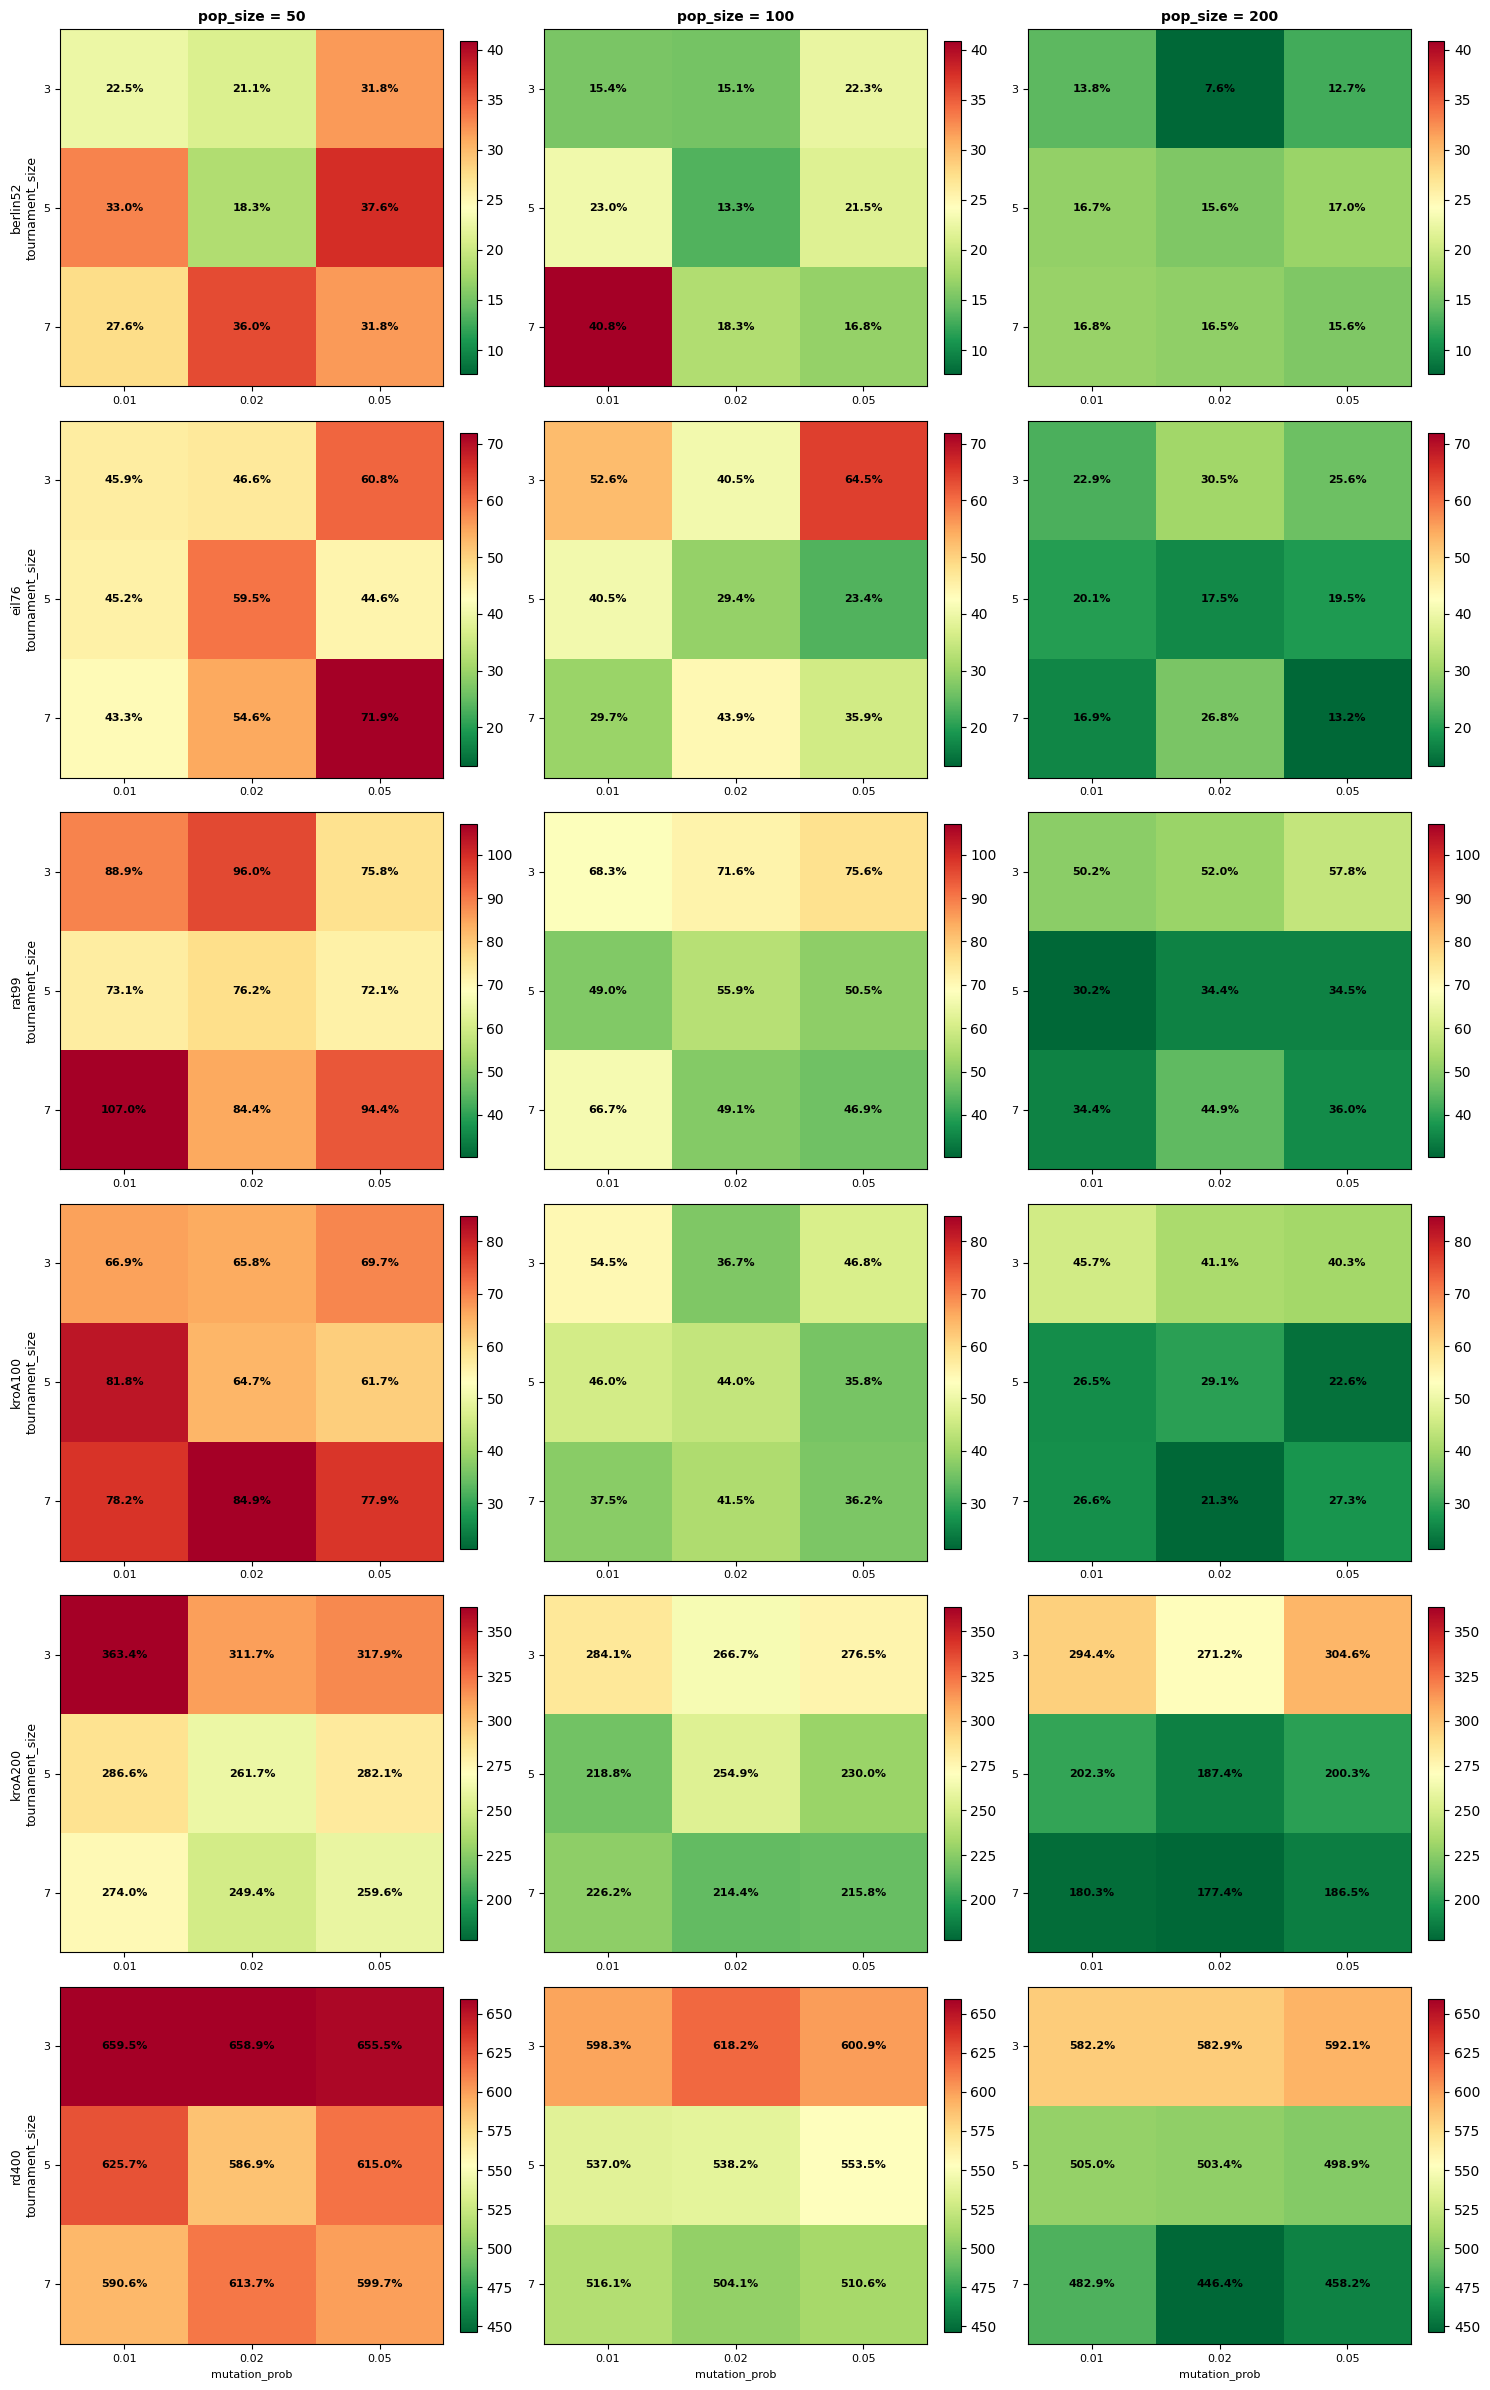

Figure saved: thesis_outputs/figures/fig_grid_search_berlin52.png


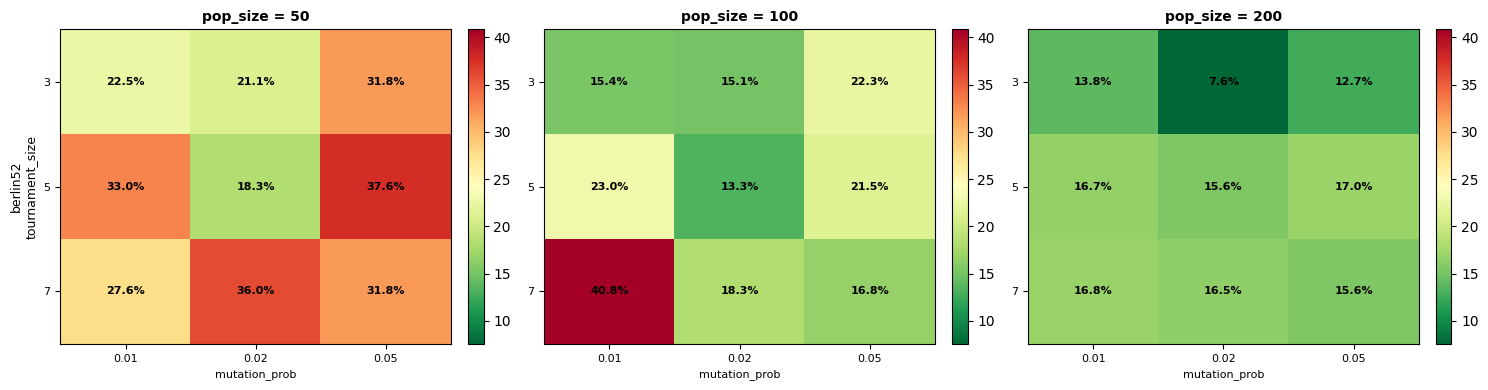

Figure saved: thesis_outputs/figures/fig_grid_search_other_instances.png


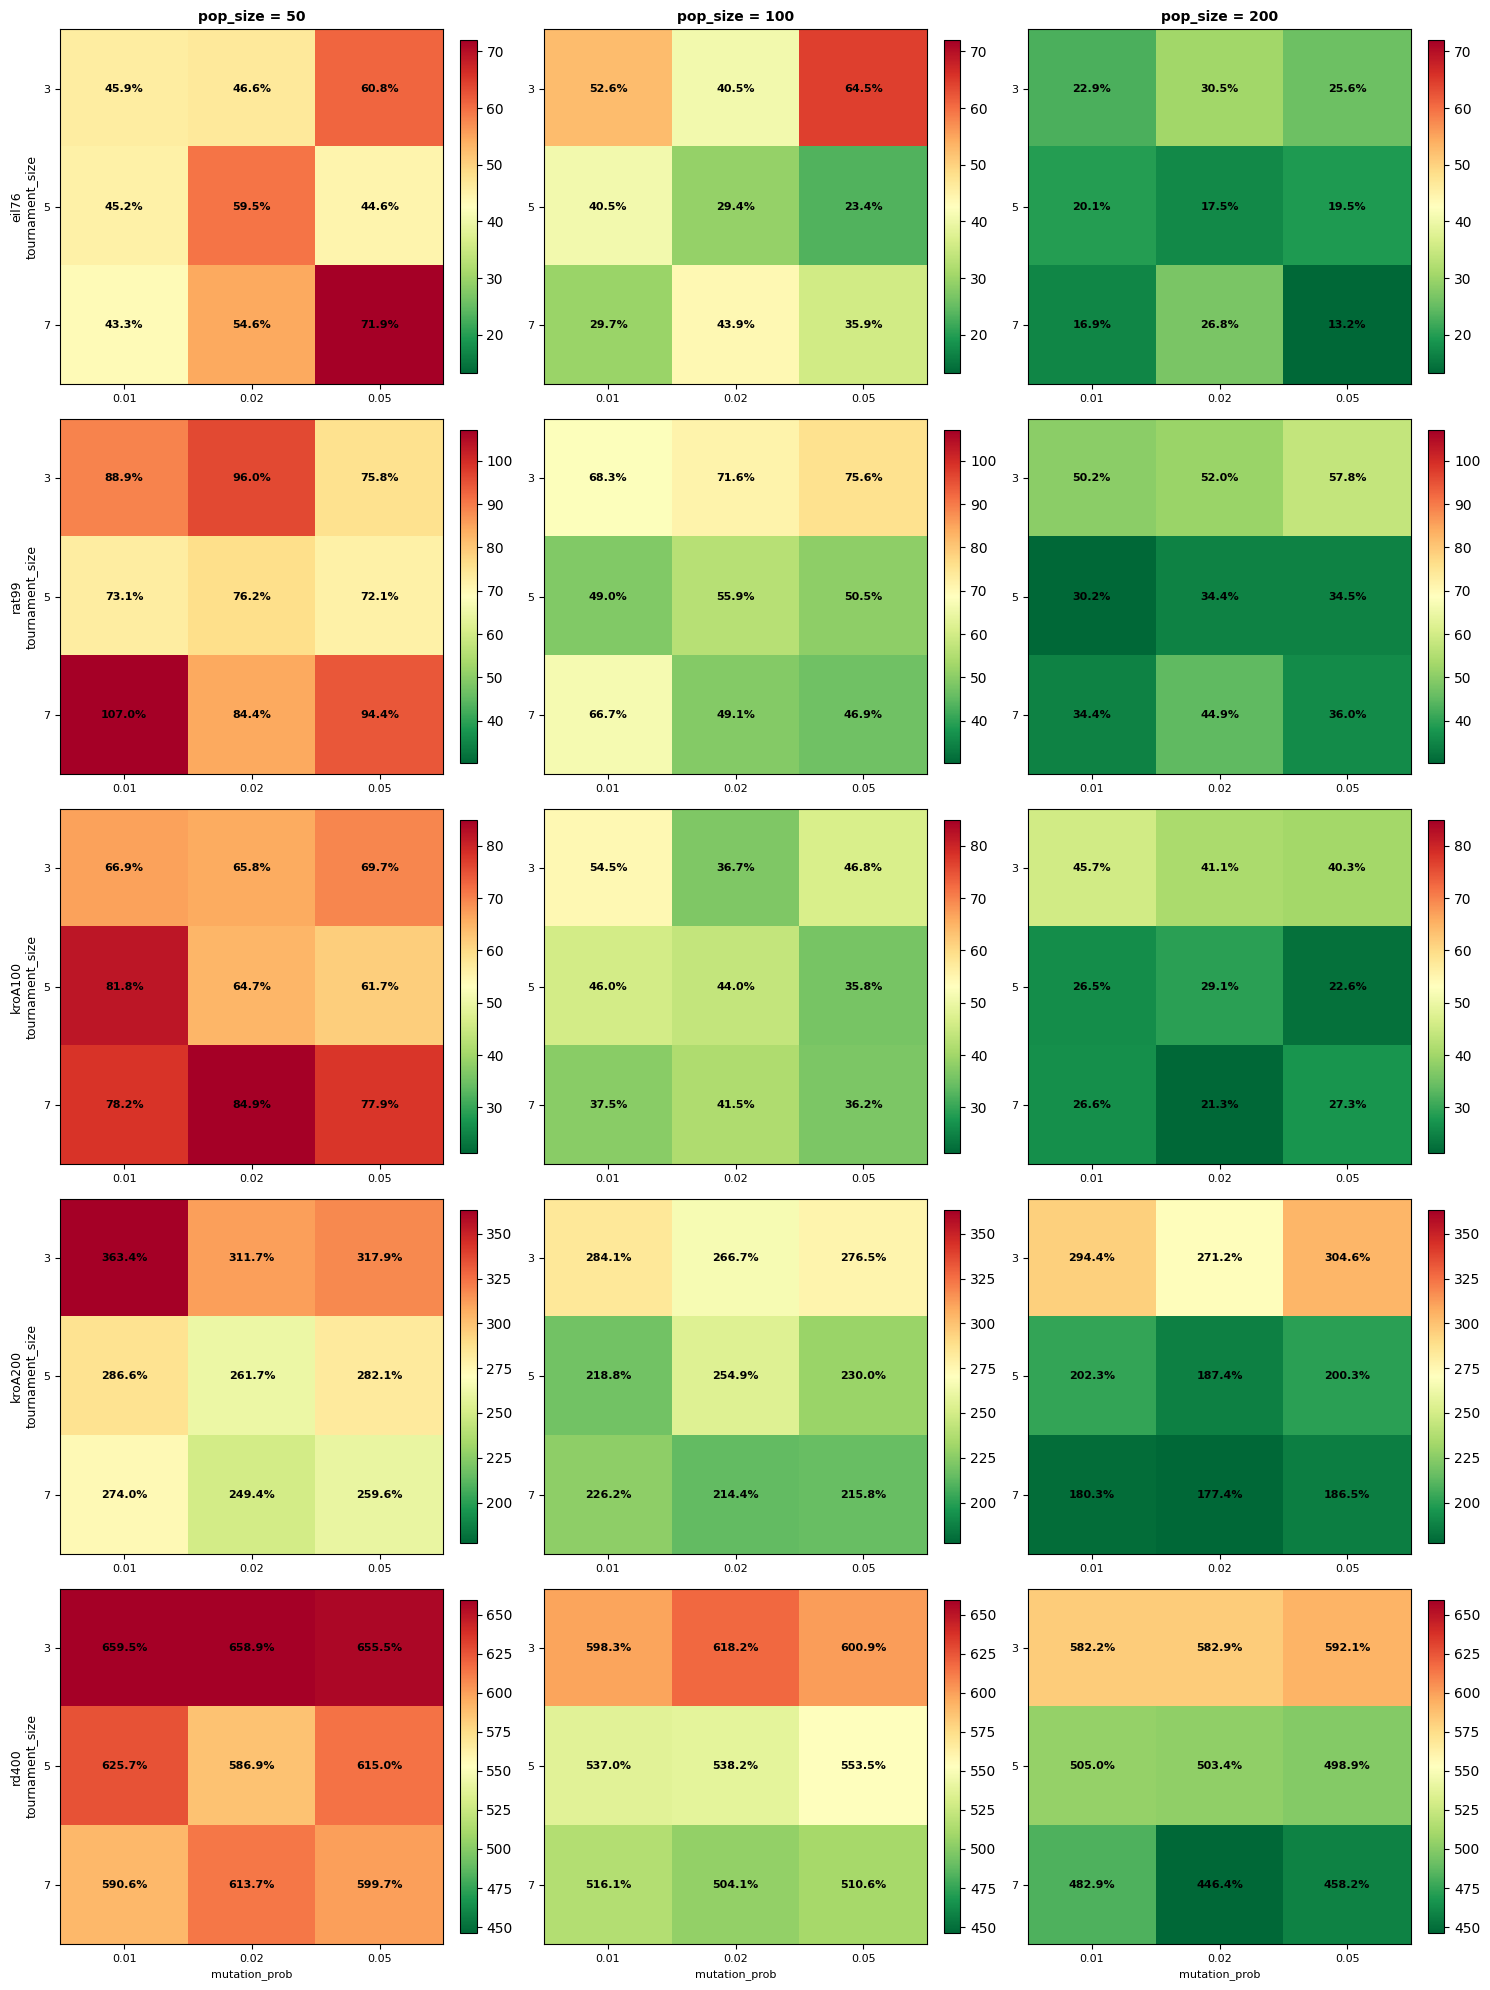

In [ ]:
# Grid search heatmaps — one per instance
# Each panel shows optimality gap (%) for a given pop_size.
# Colour scale: green = better, red = worse.

if not all_grid_results:
    print("No grid search results available. Run cell above first.")
else:
    pop_sizes  = [50, 100, 200]
    mut_vals   = [0.01, 0.02, 0.05]
    tourn_vals = [3, 5, 7]

    n_inst = len(GRID_INSTANCES)
    fig, big_axes = plt.subplots(n_inst, 3, figsize=(15, 4 * n_inst))
    if n_inst == 1:
        big_axes = [big_axes]

    for row_idx, inst_name in enumerate(GRID_INSTANCES):
        results = all_grid_results[inst_name]
        df_g = pd.DataFrame(results)
        vmin, vmax = df_g['gap_%'].min(), df_g['gap_%'].max()

        for col_idx, pop in enumerate(pop_sizes):
            ax = big_axes[row_idx][col_idx]
            matrix = np.zeros((len(tourn_vals), len(mut_vals)))
            for ti, tourn in enumerate(tourn_vals):
                for mi, mut in enumerate(mut_vals):
                    row = df_g[(df_g.population_size == pop) &
                               (df_g.mutation_prob   == mut) &
                               (df_g.tournament_size == tourn)]
                    if len(row):
                        matrix[ti, mi] = row['gap_%'].values[0]
            im = ax.imshow(matrix, cmap='RdYlGn_r', aspect='auto',
                           vmin=vmin, vmax=vmax)
            ax.set_xticks(range(len(mut_vals)))
            ax.set_xticklabels([str(m) for m in mut_vals], fontsize=8)
            ax.set_yticks(range(len(tourn_vals)))
            ax.set_yticklabels([str(t) for t in tourn_vals], fontsize=8)
            if col_idx == 0:
                ax.set_ylabel(f'{inst_name}\ntournament_size', fontsize=9)
            if row_idx == 0:
                ax.set_title(f'pop_size = {pop}', fontsize=10, fontweight='bold')
            if row_idx == n_inst - 1:
                ax.set_xlabel('mutation_prob', fontsize=8)
            for ti in range(len(tourn_vals)):
                for mi in range(len(mut_vals)):
                    ax.text(mi, ti, f'{matrix[ti, mi]:.1f}%',
                            ha='center', va='center', fontsize=8, fontweight='bold')
            fig.colorbar(im, ax=ax, fraction=0.04, pad=0.04)

    # No in-figure suptitle: the LaTeX caption carries this information (Daan, p.15).
    plt.tight_layout()
    save_fig('fig_grid_search_heatmaps_all_instances.png')
    plt.show()

    # Thesis figures: berlin52 row for the main text, the other five instances
    # for Appendix A (separate files, no suptitle).
    def _plot_grid_rows(inst_list, fname):
        n_r = len(inst_list)
        fig2, axs2 = plt.subplots(n_r, 3, figsize=(15, 4 * n_r), squeeze=False)
        for r, inst_name in enumerate(inst_list):
            df_g = pd.DataFrame(all_grid_results[inst_name])
            vmin, vmax = df_g['gap_%'].min(), df_g['gap_%'].max()
            for c, pop in enumerate(pop_sizes):
                ax = axs2[r][c]
                matrix = np.zeros((len(tourn_vals), len(mut_vals)))
                for ti, tourn in enumerate(tourn_vals):
                    for mi, mut in enumerate(mut_vals):
                        row = df_g[(df_g.population_size == pop) &
                                   (df_g.mutation_prob   == mut) &
                                   (df_g.tournament_size == tourn)]
                        if len(row):
                            matrix[ti, mi] = row['gap_%'].values[0]
                im = ax.imshow(matrix, cmap='RdYlGn_r', aspect='auto',
                               vmin=vmin, vmax=vmax)
                ax.set_xticks(range(len(mut_vals)))
                ax.set_xticklabels([str(m) for m in mut_vals], fontsize=8)
                ax.set_yticks(range(len(tourn_vals)))
                ax.set_yticklabels([str(t) for t in tourn_vals], fontsize=8)
                if c == 0:
                    ax.set_ylabel(f'{inst_name}\ntournament_size', fontsize=9)
                if r == 0:
                    ax.set_title(f'pop_size = {pop}', fontsize=10, fontweight='bold')
                if r == n_r - 1:
                    ax.set_xlabel('mutation_prob', fontsize=8)
                for ti in range(len(tourn_vals)):
                    for mi in range(len(mut_vals)):
                        ax.text(mi, ti, f'{matrix[ti, mi]:.1f}%', ha='center',
                                va='center', fontsize=8, fontweight='bold')
                fig2.colorbar(im, ax=ax, fraction=0.04, pad=0.04)
        plt.tight_layout()
        save_fig(fname)
        plt.show()

    _plot_grid_rows(['berlin52'], 'fig_grid_search_berlin52.png')
    _plot_grid_rows([n for n in GRID_INSTANCES if n != 'berlin52'],
                    'fig_grid_search_other_instances.png')


## 7. Experiment A: Selection Strategy Comparison (berlin52)

**Controlled operator-comparison baseline — parameters are PINNED, not inherited
from the tuned configurations:** population = 100, mutation probability = 0.02,
crossover probability = 0.90, **tournament size k = 5**, OX crossover, inversion
mutation, **no 2-opt**, fixed budget of 500 generations (no early stopping: roulette
and rank-based selection progress slowly and erratically; early stopping would
terminate them on a plateau and bias the comparison). Expected runtime: a few
minutes single-seed; ≈ 10–15 min for the 10-seed robustness cell (sequential).

In [ ]:
# Experiment A/B baseline — PINNED parameters (do NOT inherit from CONFIGS).
# These reproduce the documented controlled-comparison conditions of the thesis.
EXP_AB_CONFIG = {
    **CONFIG_BASE,
    'population_size': 100 if not QUICK_TEST else 20,
    'mutation_prob'  : 0.02,
    'tournament_size': 5,        # PINNED: k=5 baseline for operator comparisons
    'n_generations'  : 500 if not QUICK_TEST else 10,
    'patience'       : None,     # fixed budget — no early stopping
}
print("Experiment A/B pinned config:",
      {k: EXP_AB_CONFIG[k] for k in
       ['population_size','mutation_prob','tournament_size','n_generations','patience','crossover_prob']})

SELECTION_METHODS = ["tournament", "roulette", "rank"]
SEL_LABELS = {"tournament": "Tournament (k=5)",
              "roulette"  : "Roulette Wheel",
              "rank"      : "Rank-based (sp=1.5)"}

exp_a_results = {}
print("\n=== Experiment A: Selection Strategy Comparison ===")
print(f"berlin52 | {EXP_AB_CONFIG['n_generations']} generations fixed | pop={EXP_AB_CONFIG['population_size']} "
      f"| k={EXP_AB_CONFIG['tournament_size']} | 2-opt: OFF | seed={SEED}\n")

for sel in SELECTION_METHODS:
    random.seed(SEED); np.random.seed(SEED)
    t0 = _time.time()
    bt, bl, lg = run_ga_exp(INSTANCES['berlin52'], EXP_AB_CONFIG,
                            selection=sel, crossover="ox", use_2opt=False)
    rt = _time.time() - t0
    gap = (bl - BEST_KNOWN['berlin52']) / BEST_KNOWN['berlin52'] * 100
    exp_a_results[sel] = {"best_length": bl, "gap": gap, "runtime": rt,
                          "log": lg, "tour": bt}
    print(f"  {SEL_LABELS[sel]:<25}: {bl:,}  gap={gap:.2f}%  ({rt:.1f}s)")


Experiment A/B pinned config: {'population_size': 100, 'mutation_prob': 0.02, 'tournament_size': 5, 'n_generations': 500, 'patience': None, 'crossover_prob': 0.9}

=== Experiment A: Selection Strategy Comparison ===
berlin52 | 500 generations fixed | pop=100 | k=5 | 2-opt: OFF | seed=42

  Tournament (k=5)         : 8,214  gap=8.91%  (1.9s)
  Roulette Wheel           : 11,316  gap=50.04%  (5.7s)
  Rank-based (sp=1.5)      : 11,693  gap=55.04%  (4.8s)


Figure saved: thesis_outputs/figures/fig_experiment_A_selection.png


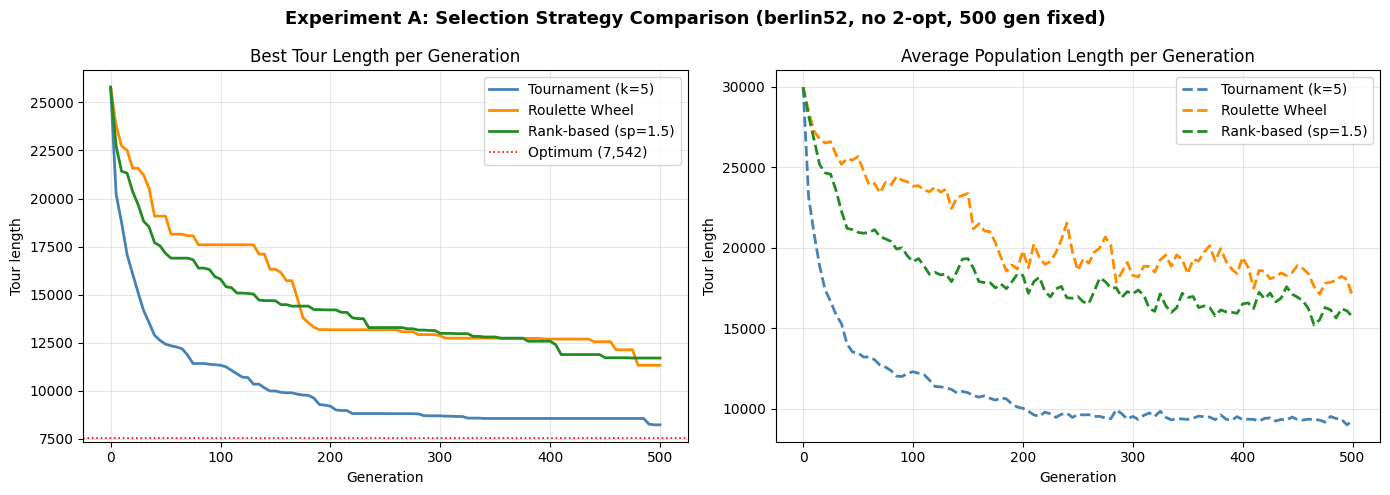


Summary — Experiment A
          Selection  Best length  Gap (%)  Runtime (s)
   Tournament (k=5)         8214     8.91          1.9
     Roulette Wheel        11316    50.04          5.7
Rank-based (sp=1.5)        11693    55.04          4.8

Note: The large gap for Roulette Wheel and Rank-based is a genuine result.
Fitness-proportionate selection loses selection pressure on TSP because the
inverse fitness values (1/length) are nearly equal across all individuals,
making selection almost random. This confirms tournament selection as the
appropriate operator for this problem class (Goldberg & Deb, 1991).


In [ ]:
# Convergence curves — Experiment A
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {"tournament": "steelblue", "roulette": "darkorange", "rank": "forestgreen"}

for sel in SELECTION_METHODS:
    df = exp_a_results[sel]["log"].to_dataframe()
    df = df[~df["synthetic"]]
    axes[0].plot(df["generation"], df["best_length"],
                 color=colors[sel], label=SEL_LABELS[sel], lw=2)
    axes[1].plot(df["generation"], df["avg_length"],
                 color=colors[sel], label=SEL_LABELS[sel], lw=2, ls="--")

axes[0].axhline(BEST_KNOWN["berlin52"], color="red", ls=":", lw=1.2, label="Optimum (7,542)")
axes[0].set_title("Best Tour Length per Generation")
axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Tour length")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].set_title("Average Population Length per Generation")
axes[1].set_xlabel("Generation"); axes[1].set_ylabel("Tour length")
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle("Experiment A: Selection Strategy Comparison (berlin52, no 2-opt, 500 gen fixed)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("fig_experiment_A_selection.png")
plt.show()

# Summary table
print("\nSummary — Experiment A")
rows = [{"Selection": SEL_LABELS[s],
         "Best length": exp_a_results[s]["best_length"],
         "Gap (%)": round(exp_a_results[s]["gap"], 2),
         "Runtime (s)": round(exp_a_results[s]["runtime"], 1)}
        for s in SELECTION_METHODS]
print(pd.DataFrame(rows).to_string(index=False))
print("\nNote: The large gap for Roulette Wheel and Rank-based is a genuine result.")
print("Fitness-proportionate selection loses selection pressure on TSP because the")
print("inverse fitness values (1/length) are nearly equal across all individuals,")
print("making selection almost random. This confirms tournament selection as the")
print("appropriate operator for this problem class (Goldberg & Deb, 1991).")


### 7.1 Experiment A robustness (10 seeds, sequential — heavy)

In [ ]:
# Run only if Experiment A single-seed ran successfully
_saved_a = load_csv('table_exp_A_selection.csv', subdir='tables')
if _saved_a is not None and len(_saved_a) == len(SELECTION_METHODS) and not FORCE_RERUN:
    print('Experiment A robustness loaded from saved CSV — skipped.')
    print(_saved_a.to_string(index=False))
    expA_multi = {sel: [] for sel in SELECTION_METHODS}   # keeps the save cell idle
elif 'exp_a_results' not in dir() or 'tournament' not in exp_a_results:
    print('WARNING: exp_a_results missing -- run Experiment A cell first')
    expA_multi = {sel: [] for sel in SELECTION_METHODS}
else:
    # Experiment A robustness: selection strategy (berlin52, 500 gen fixed, no 2-opt)
    # patience=None: fixed budget, same rationale as the main Experiment A cell.
    EXP_A_CFG = EXP_AB_CONFIG          # pinned baseline (k=5), see Section 7
    inst_b52  = INSTANCES["berlin52"]
    bk_b52    = BEST_KNOWN["berlin52"]

    expA_multi = {}
    for sel in SELECTION_METHODS:
        gaps = []
        for seed in SEEDS:
            random.seed(seed); np.random.seed(seed)
            _, bl, _ = run_ga_exp(inst_b52, EXP_A_CFG, selection=sel,
                                   crossover="ox", use_2opt=False)
            gaps.append((bl - bk_b52) / bk_b52 * 100)
        expA_multi[sel] = gaps

    print("Experiment A — Selection Strategy (mean ± SD, 10 runs, 500 gen fixed, pop=100, no 2-opt)")
    print("-"*72)
    for sel in SELECTION_METHODS:
        g = expA_multi[sel]
        print(f"  {SEL_LABELS[sel]:<25}  {np.mean(g):.2f}% ± {np.std(g):.2f}%  "
              f"(min {np.min(g):.2f}%, max {np.max(g):.2f}%)")



Experiment A robustness loaded from saved CSV — skipped.
          Selection  gap_seed42_%  mean_%  sd_%  min_%  max_%
   Tournament (k=5)          8.91   16.27  5.27   7.72  22.05
     Roulette Wheel         50.04   67.70  6.36  56.67  76.81
Rank-based (sp=1.5)         55.04   48.73  6.75  33.40  57.46


In [ ]:
if expA_multi and any(len(v) > 0 for v in expA_multi.values()):
    # Save Experiment A
    rows_a = []
    for sel in SELECTION_METHODS:
        g = expA_multi[sel]
        rows_a.append({'Selection': SEL_LABELS[sel],
                       'gap_seed42_%': round(exp_a_results[sel]['gap'], 2),
                       'mean_%': round(np.mean(g), 2), 'sd_%': round(np.std(g), 2),
                       'min_%': round(np.min(g), 2), 'max_%': round(np.max(g), 2)})
    df_exp_a = pd.DataFrame(rows_a)
    print(df_exp_a.to_string(index=False))
    save_csv(df_exp_a, 'table_exp_A_selection.csv', subdir='tables')



## 8. Experiment B: Crossover Operator Comparison (berlin52)

Same pinned baseline as Experiment A (pop = 100, k = 5, 500 generations fixed,
no 2-opt); only the crossover operator varies (OX / PMX / CX).

All three children are valid permutations.
  OX  child: [8, 6, 3, 4, 5, 1, 7, 2]
  PMX child: [6, 8, 3, 4, 5, 1, 7, 2]
  CX  child: [1, 8, 3, 4, 5, 6, 7, 2]


/tmp/ipykernel_36493/4093029179.py:123: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Figure saved: thesis_outputs/figures/fig_crossover_operators_example.png


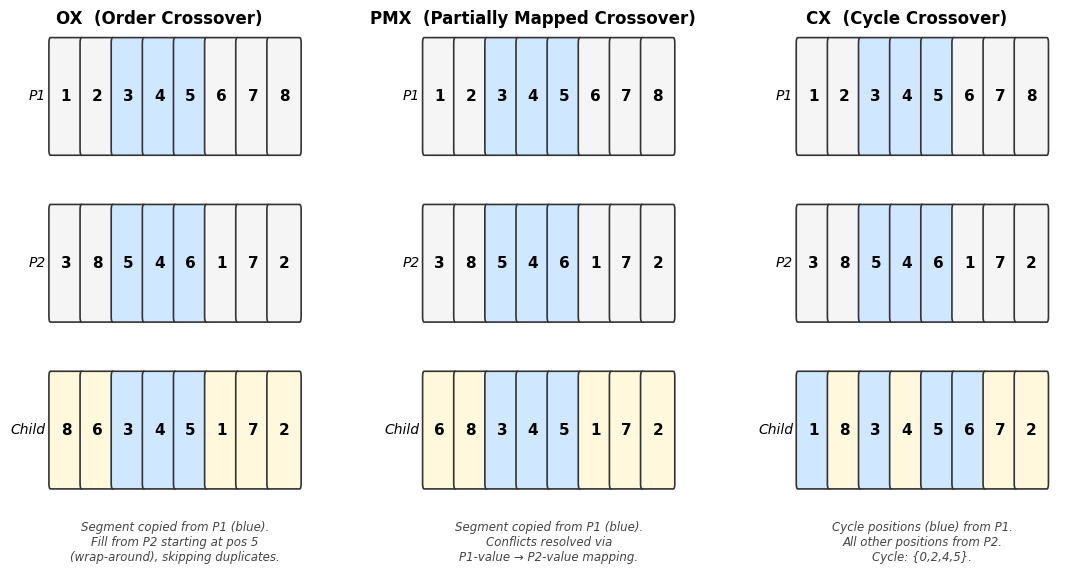


Larrañaga et al. (1999):
  OX  preserves the relative order of cities from one parent.
  PMX preserves absolute positions more closely than OX.
  CX  is the most conservative: every city stays in a position
      it held in one of the parents.


In [ ]:
# Crossover operator visualisation
# Daan comment p.8: "perhaps an example/picture of the three operators
# will increase interpretability of these operators"
#
# Shows OX, PMX and CX on a small 8-city example so the reader can
# follow each step without running the full GA.

import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec

def _draw_permutation(ax, perm, highlight=None, label='', color='white', fontsize=11):
    """Draw a row of labelled boxes representing a permutation."""
    n = len(perm)
    for idx, city in enumerate(perm):
        bg = '#d0e8ff' if (highlight and idx in highlight) else color
        rect = mpatches.FancyBboxPatch(
            (idx, 0), 1, 1, boxstyle='round,pad=0.05',
            linewidth=1.2, edgecolor='#333333', facecolor=bg)
        ax.add_patch(rect)
        ax.text(idx + 0.5, 0.5, str(city),
                ha='center', va='center', fontsize=fontsize, fontweight='bold')
    if label:
        ax.text(-0.15, 0.5, label, ha='right', va='center',
                fontsize=fontsize - 1, style='italic')
    ax.set_xlim(-1.3, n + 0.3)   # FIX: last box was clipped at the right edge
    ax.set_ylim(-0.1, 1.1)
    ax.axis('off')

# Example: 8 cities, segment = positions 2, 3, 4 (0-indexed)
P1  = [1, 2, 3, 4, 5, 6, 7, 8]
P2  = [3, 8, 5, 4, 6, 1, 7, 2]
SEG = {2, 3, 4}   # highlighted segment positions

# ── OX child ────────────────────────────────────────────────────────────────
# 1. Copy segment [3,4,5] from P1 into child.
# 2. Fill remaining positions starting from the position AFTER the segment end
#    (position 5), wrapping around, using P2's order and skipping duplicates.
# Larrañaga et al. (1999), §4.2.1.
ox_seg_cities = {P1[i] for i in SEG}   # {3, 4, 5}
seg_end = max(sorted(SEG))              # 4 — fill starts at position 5
fill_order = [(seg_end + 1 + k) % 8 for k in range(8 - len(SEG))]  # [5,6,7,0,1]
ox_fill = [c for c in P2[seg_end+1:] + P2[:seg_end+1] if c not in ox_seg_cities]
OX_CHILD = [None] * 8
for i in SEG: OX_CHILD[i] = P1[i]
for pos, city in zip(fill_order, ox_fill): OX_CHILD[pos] = city
# Result: [8, 6, 3, 4, 5, 1, 7, 2]

# ── PMX child ───────────────────────────────────────────────────────────────
# 1. Copy segment from P1.
# 2. For each position outside the segment, take P2's city.
#    If it conflicts with a city already in the segment, follow the mapping
#    P1_value -> P2_value at the corresponding segment position until resolved.
# Larrañaga et al. (1999), §4.2.2.
p1_seg = [P1[i] for i in sorted(SEG)]          # [3, 4, 5]
p2_seg = [P2[i] for i in sorted(SEG)]          # [5, 4, 6]
p1_to_p2 = {p1_seg[k]: p2_seg[k] for k in range(len(p1_seg))}  # {3:5, 4:4, 5:6}
PMX_CHILD = [None] * 8
for i in SEG: PMX_CHILD[i] = P1[i]
for i in range(8):
    if i not in SEG:
        city = P2[i]
        seen = set()
        while city in set(p1_seg):      # resolve conflict via mapping
            if city in seen: break      # safety guard against infinite loop
            seen.add(city)
            city = p1_to_p2[city]
        PMX_CHILD[i] = city
# Result: [6, 8, 3, 4, 5, 1, 7, 2]

# ── CX child ────────────────────────────────────────────────────────────────
# Follow the cycle starting at position 0:
#   P1[0]=1 → find 1 in P2 at pos 5 → P1[5]=6 → find 6 in P2 at pos 4
#   → P1[4]=5 → find 5 in P2 at pos 2 → P1[2]=3 → find 3 in P2 at pos 0 → cycle closes.
# Cycle positions {0,2,4,5} inherit from P1; remaining {1,3,6,7} inherit from P2.
# Larrañaga et al. (1999), §4.2.3.
p2_pos = {v: i for i, v in enumerate(P2)}
cycle_pos = set()
pos = 0
while pos not in cycle_pos:
    cycle_pos.add(pos)
    pos = p2_pos[P1[pos]]
CX_CHILD = [P1[i] if i in cycle_pos else P2[i] for i in range(8)]
# Result: [1, 8, 3, 4, 5, 6, 7, 2]

# Quick validity check (assert all tours are valid permutations)
assert sorted(OX_CHILD)  == list(range(1,9)), "OX invalid"
assert sorted(PMX_CHILD) == list(range(1,9)), "PMX invalid"
assert sorted(CX_CHILD)  == list(range(1,9)), "CX invalid"
print("All three children are valid permutations.")
print(f"  OX  child: {OX_CHILD}")
print(f"  PMX child: {PMX_CHILD}")
print(f"  CX  child: {CX_CHILD}")

# ── Plot ─────────────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(13.5, 6.0))
gs  = gridspec.GridSpec(3, 3, figure=fig, hspace=0.30, wspace=0.25)

operators       = ['OX  (Order Crossover)',
                   'PMX  (Partially Mapped Crossover)',
                   'CX  (Cycle Crossover)']
children        = [OX_CHILD, PMX_CHILD, CX_CHILD]
child_highlights = [SEG, SEG, cycle_pos]   # blue = 'came from P1'
notes = [
    "Segment copied from P1 (blue).\nFill from P2 starting at pos 5\n(wrap-around), skipping duplicates.",
    "Segment copied from P1 (blue).\nConflicts resolved via\nP1-value → P2-value mapping.",
    "Cycle positions (blue) from P1.\nAll other positions from P2.\nCycle: {0,2,4,5}.",
]

for col, (op, child, ch, note) in enumerate(zip(operators, children, child_highlights, notes)):
    ax_p1    = fig.add_subplot(gs[0, col])
    ax_p2    = fig.add_subplot(gs[1, col])
    ax_child = fig.add_subplot(gs[2, col])

    _draw_permutation(ax_p1,    P1,    highlight=SEG,  label='P1',    color='#f5f5f5')
    _draw_permutation(ax_p2,    P2,    highlight=SEG,  label='P2',    color='#f5f5f5')
    _draw_permutation(ax_child, child, highlight=ch,   label='Child', color='#fff8dc')

    ax_p1.set_title(op, fontsize=12, fontweight='bold', pad=6)
    ax_child.text(4, -0.35, note, ha='center', va='top', fontsize=8.5,
                  style='italic', color='#444444')

# No in-figure suptitle: the LaTeX caption carries this information (Daan, p.15).
plt.tight_layout()
save_fig('fig_crossover_operators_example.png')
plt.show()

print("\nLarrañaga et al. (1999):")
print("  OX  preserves the relative order of cities from one parent.")
print("  PMX preserves absolute positions more closely than OX.")
print("  CX  is the most conservative: every city stays in a position")
print("      it held in one of the parents.")


In [ ]:
CROSSOVER_METHODS = ["ox", "pmx", "cx"]
CX_LABELS = {"ox": "OX (Order Crossover)", "pmx": "PMX (Partially Mapped)",
             "cx": "CX (Cycle Crossover)"}

exp_b_results = {}
print("=== Experiment B: Crossover Operator Comparison ===")
print(f"berlin52 | {EXP_AB_CONFIG['n_generations']} generations fixed | pop={EXP_AB_CONFIG['population_size']} "
      f"| tournament k={EXP_AB_CONFIG['tournament_size']} | 2-opt: OFF | seed={SEED}\n")

for cx in CROSSOVER_METHODS:
    random.seed(SEED); np.random.seed(SEED)
    t0 = _time.time()
    bt, bl, lg = run_ga_exp(INSTANCES['berlin52'], EXP_AB_CONFIG,
                            selection="tournament", crossover=cx, use_2opt=False)
    rt = _time.time() - t0
    gap = (bl - BEST_KNOWN['berlin52']) / BEST_KNOWN['berlin52'] * 100
    exp_b_results[cx] = {"best_length": bl, "gap": gap, "runtime": rt,
                         "log": lg, "tour": bt}
    print(f"  {CX_LABELS[cx]:<25}: {bl:,}  gap={gap:.2f}%  ({rt:.1f}s)")


=== Experiment B: Crossover Operator Comparison ===
berlin52 | 500 generations fixed | pop=100 | tournament k=5 | 2-opt: OFF | seed=42

  OX (Order Crossover)     : 8,214  gap=8.91%  (2.2s)
  PMX (Partially Mapped)   : 10,072  gap=33.55%  (3.0s)
  CX (Cycle Crossover)     : 11,582  gap=53.57%  (6.1s)


Figure saved: thesis_outputs/figures/fig_experiment_B_crossover.png


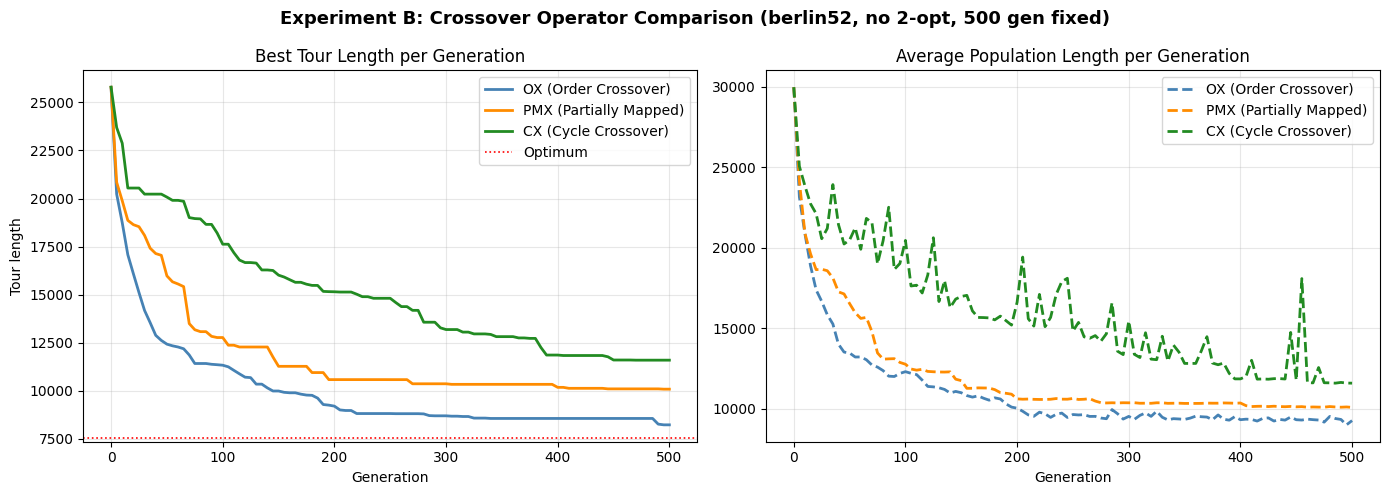


Summary — Experiment B
             Crossover  Best length  Gap (%)  Runtime (s)
  OX (Order Crossover)         8214     8.91          2.2
PMX (Partially Mapped)        10072    33.55          3.0
  CX (Cycle Crossover)        11582    53.57          6.1

→ Best selection: Tournament (k=5)
→ Best crossover: OX (Order Crossover)
  OX + Tournament is confirmed as the best operator combination.
  This validates the design choices in the main experiments.


In [ ]:
# Convergence curves — Experiment B
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cx_colors = {"ox": "steelblue", "pmx": "darkorange", "cx": "forestgreen"}

for cx in CROSSOVER_METHODS:
    df = exp_b_results[cx]["log"].to_dataframe()
    df = df[~df["synthetic"]]
    axes[0].plot(df["generation"], df["best_length"],
                 color=cx_colors[cx], label=CX_LABELS[cx], lw=2)
    axes[1].plot(df["generation"], df["avg_length"],
                 color=cx_colors[cx], label=CX_LABELS[cx], lw=2, ls="--")

axes[0].axhline(BEST_KNOWN["berlin52"], color="red", ls=":", lw=1.2, label="Optimum")
axes[0].set_title("Best Tour Length per Generation")
axes[0].set_xlabel("Generation"); axes[0].set_ylabel("Tour length")
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].set_title("Average Population Length per Generation")
axes[1].set_xlabel("Generation"); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.suptitle("Experiment B: Crossover Operator Comparison (berlin52, no 2-opt, 500 gen fixed)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
save_fig("fig_experiment_B_crossover.png")
plt.show()

# Summary table
print("\nSummary — Experiment B")
rows = [{"Crossover": CX_LABELS[c],
         "Best length": exp_b_results[c]["best_length"],
         "Gap (%)": round(exp_b_results[c]["gap"], 2),
         "Runtime (s)": round(exp_b_results[c]["runtime"], 1)}
        for c in CROSSOVER_METHODS]
print(pd.DataFrame(rows).to_string(index=False))

best_sel = min(exp_a_results, key=lambda s: exp_a_results[s]["gap"])
best_cx  = min(exp_b_results, key=lambda c: exp_b_results[c]["gap"])
print(f"\n→ Best selection: {SEL_LABELS[best_sel]}")
print(f"→ Best crossover: {CX_LABELS[best_cx]}")
print(f"  OX + Tournament is confirmed as the best operator combination.")
print(f"  This validates the design choices in the main experiments.")


### 8.1 Experiment B robustness (10 seeds, sequential — heavy)

In [ ]:
_saved_b = load_csv('table_exp_B_crossover.csv', subdir='tables')
if _saved_b is not None and len(_saved_b) == len(CROSSOVER_METHODS) and not FORCE_RERUN:
    print('Experiment B robustness loaded from saved CSV — skipped.')
    print(_saved_b.to_string(index=False))
    expB_multi = {cx: [] for cx in CROSSOVER_METHODS}     # keeps the save cell idle
elif 'exp_b_results' not in dir() or 'ox' not in exp_b_results:
    print('WARNING: exp_b_results missing -- run Experiment B cell first')
    expB_multi = {cx: [] for cx in CROSSOVER_METHODS}
else:
    # Experiment B robustness: crossover operator (berlin52, 500 gen fixed, no 2-opt)
    # patience=None: fixed budget, same rationale as the main Experiment B cell.
    EXP_B_CFG = EXP_AB_CONFIG          # pinned baseline (k=5), see Section 7
    inst_b52  = INSTANCES["berlin52"]
    bk_b52    = BEST_KNOWN["berlin52"]

    expB_multi = {}
    for cx in CROSSOVER_METHODS:
        gaps = []
        for seed in SEEDS:
            random.seed(seed); np.random.seed(seed)
            _, bl, _ = run_ga_exp(inst_b52, EXP_B_CFG, selection="tournament",
                                   crossover=cx, use_2opt=False)
            gaps.append((bl - bk_b52) / bk_b52 * 100)
        expB_multi[cx] = gaps

    print("Experiment B — Crossover Operator (mean ± SD, 10 runs, 500 gen fixed, pop=100, no 2-opt)")
    print("-"*72)
    for cx in CROSSOVER_METHODS:
        g = expB_multi[cx]
        print(f"  {CX_LABELS[cx]:<30}  {np.mean(g):.2f}% ± {np.std(g):.2f}%  "
              f"(min {np.min(g):.2f}%, max {np.max(g):.2f}%)")



Experiment B robustness loaded from saved CSV — skipped.
             Crossover  gap_seed42_%  mean_%  sd_%  min_%  max_%
  OX (Order Crossover)          8.91   16.27  5.27   7.72  22.05
PMX (Partially Mapped)         33.55   32.21  3.50  27.15  37.24
  CX (Cycle Crossover)         53.57   52.63  8.86  38.94  71.57


In [ ]:
if expB_multi and any(len(v) > 0 for v in expB_multi.values()):
    # Save Experiment B
    rows_b = []
    for cx in CROSSOVER_METHODS:
        g = expB_multi[cx]
        rows_b.append({'Crossover': CX_LABELS[cx],
                       'gap_seed42_%': round(exp_b_results[cx]['gap'], 2),
                       'mean_%': round(np.mean(g), 2), 'sd_%': round(np.std(g), 2),
                       'min_%': round(np.min(g), 2), 'max_%': round(np.max(g), 2)})
    df_exp_b = pd.DataFrame(rows_b)
    print(df_exp_b.to_string(index=False))
    save_csv(df_exp_b, 'table_exp_B_crossover.csv', subdir='tables')



## 9. Single-Seed Experiments: Pure GA vs Memetic GA (Table: pure vs memetic)

Runtimes are recorded for **both** algorithms (Daan, p.14). 2-opt variant per
instance: **full (Numba) 2-opt** for berlin52, eil76, rat99, kroA100; **neighbour-list
2-opt (k = 15)** for kroA200, rd400, rat575, pr1002 — recorded in the results table.

**Resumable:** if a saved result (metadata + full search log) exists and
`FORCE_RERUN=False`, it is loaded instead of recomputed. Expected runtimes
(Colab Pro, previous run): kroA200 ≈ 4 min, rd400 ≈ 15 min, rat575 ≈ 30 min,
pr1002 ≈ 90 min (memetic; pure GA is faster).

In [ ]:
# berlin52 — both algorithms (also needed for the explanation section)
name = 'berlin52'
meta_mem, log_loaded = _load_full_log(f'{name}_memetic_seed42', subdir='single_seed')
meta_pure = load_json(f'{name}_pure_seed42_metadata.json', subdir='single_seed')

if (not FORCE_RERUN) and meta_mem and log_loaded is not None and meta_pure:
    best_length_pure, gap_pure = meta_pure['best_length'], meta_pure['gap_%']
    t_pure_b52 = meta_pure.get('runtime_s', float('nan'))
    best_tour_mem  = meta_mem['best_tour']
    best_length_mem, gap_mem = meta_mem['best_length'], meta_mem['gap_%']
    t_mem_b52 = meta_mem.get('runtime_s', float('nan'))
    log_mem = log_loaded
    log_pure = None
    print(f"berlin52: loaded saved results (pure gap={gap_pure}%, memetic gap={gap_mem}%)")
else:
    cfg = CONFIGS.get('berlin52', {**CONFIG, 'patience': PATIENCE_SCALE['berlin52']})
    random.seed(SEED); np.random.seed(SEED)
    print("berlin52 | Pure GA...")
    t0 = _time.time()
    best_tour_pure, best_length_pure, log_pure = run_ga(INSTANCES['berlin52'], cfg,
                                                        use_2opt=False, verbose=False)
    t_pure_b52 = _time.time() - t0
    gap_pure = (best_length_pure - BEST_KNOWN['berlin52']) / BEST_KNOWN['berlin52'] * 100
    print(f"  Pure GA    : {best_length_pure:,}  gap={gap_pure:.2f}%  ({t_pure_b52:.1f}s)")

    random.seed(SEED); np.random.seed(SEED)
    print("berlin52 | Memetic GA (full 2-opt)...")
    t0 = _time.time()
    best_tour_mem, best_length_mem, log_mem = run_ga(INSTANCES['berlin52'], cfg,
                                                     use_2opt=True, verbose=False)
    t_mem_b52 = _time.time() - t0
    gap_mem = (best_length_mem - BEST_KNOWN['berlin52']) / BEST_KNOWN['berlin52'] * 100
    print(f"  Memetic GA : {best_length_mem:,}  gap={gap_mem:.2f}%  ({t_mem_b52:.1f}s)")

    _save_result('berlin52_pure_seed42',
                 {'best_length': int(best_length_pure), 'gap_%': round(gap_pure, 2),
                  'runtime_s': round(t_pure_b52, 1), 'instance': 'berlin52',
                  'algorithm': 'pure', '2opt_type': 'none'},
                 log=log_pure, subdir='single_seed')
    _save_result('berlin52_memetic_seed42',
                 {'best_length': int(best_length_mem), 'gap_%': round(gap_mem, 2),
                  'runtime_s': round(t_mem_b52, 1), 'instance': 'berlin52',
                  'algorithm': 'memetic', '2opt_type': 'full',
                  'best_tour': [int(c) for c in best_tour_mem]},
                 log=log_mem, subdir='single_seed', full_log=True)

# Aliases for the explanation section
best_tour, best_length, log = list(best_tour_mem), int(best_length_mem), log_mem

results_table = [
    {'instance': 'berlin52', 'n_cities': 52, 'best_known': BEST_KNOWN['berlin52'],
     'pure_GA': int(best_length_pure), 'pure_gap_%': round(gap_pure, 2),
     'memetic_GA': int(best_length_mem), 'memetic_gap_%': round(gap_mem, 2),
     'runtime_pure_s': round(float(t_pure_b52), 1),
     'runtime_memetic_s': round(float(t_mem_b52), 1),
     '2opt_type': 'full'},
]


berlin52: loaded saved results (pure gap=7.58%, memetic gap=0.0%)


In [ ]:
# Core instances: eil76, rat99, kroA100 (full 2-opt) — resumable
explanation_inputs = {}   # name -> dict(inst, best_tour, best_length, log, gap)

for name in ['eil76', 'rat99', 'kroA100']:
    inst = INSTANCES[name]
    bk   = BEST_KNOWN[name]
    cfg  = CONFIGS.get(name, {**CONFIG, 'patience': PATIENCE_SCALE[name]})

    meta_mem, log_loaded = _load_full_log(f'{name}_memetic_seed42', subdir='single_seed')
    meta_pure = load_json(f'{name}_pure_seed42_metadata.json', subdir='single_seed')

    if (not FORCE_RERUN) and meta_mem and meta_pure and \
       (log_loaded is not None or name == 'kroA100'):
        bl_pure, gp = meta_pure['best_length'], meta_pure['gap_%']
        t_pure = meta_pure.get('runtime_s', float('nan'))
        bt_mem = meta_mem['best_tour']; bl_mem = meta_mem['best_length']
        gm = meta_mem['gap_%']; t_mem = meta_mem.get('runtime_s', float('nan'))
        lg_mem = log_loaded
        print(f"{name}: loaded saved results (pure gap={gp}%, memetic gap={gm}%)")
    else:
        print(f"\n{name} | n={inst['n']}")
        random.seed(SEED); np.random.seed(SEED)
        t0 = _time.time()
        bt_pure, bl_pure, lg_pure = run_ga(inst, cfg, use_2opt=False, verbose=False)
        t_pure = _time.time() - t0
        gp = (bl_pure - bk) / bk * 100
        print(f"  Pure GA    : {bl_pure:,}  gap={gp:.2f}%  ({t_pure:.1f}s)")

        random.seed(SEED); np.random.seed(SEED)
        t0 = _time.time()
        bt_mem, bl_mem, lg_mem = run_ga(inst, cfg, use_2opt=True, verbose=False)
        t_mem = _time.time() - t0
        gm = (bl_mem - bk) / bk * 100
        print(f"  Memetic GA : {bl_mem:,}  gap={gm:.2f}%  ({t_mem:.1f}s)  [full 2-opt]")

        _save_result(f'{name}_pure_seed42',
                     {'best_length': int(bl_pure), 'gap_%': round(gp, 2),
                      'runtime_s': round(t_pure, 1), 'instance': name,
                      'algorithm': 'pure', '2opt_type': 'none'},
                     log=lg_pure, subdir='single_seed')
        # full log saved for explanation instances (eil76, rat99)
        _save_result(f'{name}_memetic_seed42',
                     {'best_length': int(bl_mem), 'gap_%': round(gm, 2),
                      'runtime_s': round(t_mem, 1), 'instance': name,
                      'algorithm': 'memetic', '2opt_type': 'full',
                      'best_tour': [int(c) for c in bt_mem]},
                     log=lg_mem, subdir='single_seed',
                     full_log=(name in ['eil76', 'rat99']))

    results_table.append({'instance': name, 'n_cities': inst['n'], 'best_known': bk,
                          'pure_GA': int(bl_pure), 'pure_gap_%': round(float(gp), 2),
                          'memetic_GA': int(bl_mem), 'memetic_gap_%': round(float(gm), 2),
                          'runtime_pure_s': round(float(t_pure), 1),
                          'runtime_memetic_s': round(float(t_mem), 1),
                          '2opt_type': 'full'})
    if name in ['eil76', 'rat99'] and lg_mem is not None:
        explanation_inputs[name] = {'inst': inst, 'best_tour': list(bt_mem),
                                    'best_length': int(bl_mem), 'log': lg_mem,
                                    'gap': float(gm)}
explanation_inputs['berlin52'] = {'inst': INSTANCES['berlin52'], 'best_tour': best_tour,
                                  'best_length': best_length, 'log': log,
                                  'gap': float(gap_mem)}


eil76: loaded saved results (pure gap=6.51%, memetic gap=0.0%)
rat99: loaded saved results (pure gap=22.21%, memetic gap=0.0%)
kroA100: loaded saved results (pure gap=11.56%, memetic gap=0.02%)


### 9.1 Heavy instances (kroA200, rd400, rat575, pr1002) — RUN_HEAVY, resumable

*Expected memetic runtimes (Colab Pro): ≈ 4 / 15 / 30 / 90 minutes respectively.*

In [ ]:
# Heavy instances — neighbour-list 2-opt (k=15) for the memetic GA
HEAVY_SPECS = ['kroA200', 'rd400', 'rat575', 'pr1002']
heavy_vars = {}

for name in HEAVY_SPECS:
    inst = INSTANCES[name]
    bk   = BEST_KNOWN[name]
    cfg  = CONFIGS.get(name, {**CONFIG, 'patience': PATIENCE_SCALE[name]})

    meta_mem, log_loaded = _load_full_log(f'{name}_memetic_seed42', subdir='single_seed')
    meta_pure = load_json(f'{name}_pure_seed42_metadata.json', subdir='single_seed')
    need_log  = name in ['rat575', 'pr1002']     # explanation instances

    if (not FORCE_RERUN) and meta_mem and meta_pure and \
       ((not need_log) or log_loaded is not None):
        print(f"{name}: loaded saved results (pure gap={meta_pure['gap_%']}%, "
              f"memetic gap={meta_mem['gap_%']}%)")
        results_table.append({'instance': name, 'n_cities': inst['n'], 'best_known': bk,
                              'pure_GA': meta_pure['best_length'],
                              'pure_gap_%': meta_pure['gap_%'],
                              'memetic_GA': meta_mem['best_length'],
                              'memetic_gap_%': meta_mem['gap_%'],
                              'runtime_pure_s': meta_pure.get('runtime_s'),
                              'runtime_memetic_s': meta_mem.get('runtime_s'),
                              '2opt_type': 'neighbour-list k=15'})
        if need_log:
            heavy_vars[name] = {'inst': inst, 'best_tour': meta_mem['best_tour'],
                                'best_length': meta_mem['best_length'],
                                'log': log_loaded, 'gap': meta_mem['gap_%']}
        continue

    if not RUN_HEAVY:
        print(f"{name}: no saved result — set RUN_HEAVY=True to compute.")
        results_table.append({'instance': name, 'n_cities': inst['n'], 'best_known': bk,
                              'pure_GA': None, 'pure_gap_%': None,
                              'memetic_GA': None, 'memetic_gap_%': None,
                              'runtime_pure_s': None, 'runtime_memetic_s': None,
                              '2opt_type': 'neighbour-list k=15'})
        continue

    print(f"\n{name} | n={inst['n']} | RUN_HEAVY=True")
    random.seed(SEED); np.random.seed(SEED)
    t0 = _time.time()
    bt_pure, bl_pure, lg_pure = run_ga(inst, cfg, use_2opt=False, verbose=False)
    t_pure = _time.time() - t0
    gp = (bl_pure - bk) / bk * 100
    print(f"  Pure GA    : {bl_pure:,}  gap={gp:.2f}%  ({t_pure:.0f}s)")
    _save_result(f'{name}_pure_seed42',
                 {'best_length': int(bl_pure), 'gap_%': round(gp, 2),
                  'runtime_s': round(t_pure, 1), 'instance': name,
                  'algorithm': 'pure', '2opt_type': 'none'},
                 log=lg_pure, subdir='single_seed')

    random.seed(SEED); np.random.seed(SEED)
    t0 = _time.time()
    bt_mem, bl_mem, lg_mem = run_ga_nn(inst, cfg, verbose=True)
    t_mem = _time.time() - t0
    gm = (bl_mem - bk) / bk * 100
    print(f"  Memetic GA : {bl_mem:,}  gap={gm:.2f}%  ({t_mem:.0f}s)  [neighbour-list k=15]")
    _save_result(f'{name}_memetic_seed42',
                 {'best_length': int(bl_mem), 'gap_%': round(gm, 2),
                  'runtime_s': round(t_mem, 1), 'instance': name,
                  'algorithm': 'memetic', '2opt_type': 'neighbour-list k=15',
                  'best_tour': [int(c) for c in bt_mem]},
                 log=lg_mem, subdir='single_seed', full_log=need_log)

    results_table.append({'instance': name, 'n_cities': inst['n'], 'best_known': bk,
                          'pure_GA': int(bl_pure), 'pure_gap_%': round(gp, 2),
                          'memetic_GA': int(bl_mem), 'memetic_gap_%': round(gm, 2),
                          'runtime_pure_s': round(t_pure, 1),
                          'runtime_memetic_s': round(t_mem, 1),
                          '2opt_type': 'neighbour-list k=15'})
    if need_log:
        heavy_vars[name] = {'inst': inst, 'best_tour': list(bt_mem),
                            'best_length': int(bl_mem), 'log': lg_mem, 'gap': float(gm)}


kroA200: loaded saved results (pure gap=51.35%, memetic gap=0.0%)
rd400: loaded saved results (pure gap=134.32%, memetic gap=0.04%)
rat575: loaded saved results (pure gap=201.7%, memetic gap=0.06%)
pr1002: loaded saved results (pure gap=455.19%, memetic gap=0.42%)


In [ ]:
# TABLE: Pure GA vs Memetic GA — runtimes for BOTH algorithms (Daan, p.14)
df_results = pd.DataFrame(results_table)
cols = ['instance','n_cities','best_known','pure_GA','pure_gap_%',
        'memetic_GA','memetic_gap_%','runtime_pure_s','runtime_memetic_s','2opt_type']
print("\n" + "="*100)
print("TABLE — Pure GA vs Memetic GA (seed=42)")
print("="*100)
print(df_results[cols].to_string(index=False))
print("\nNote: runtimes are wall-clock seconds (seed=42). '2opt_type' is the local-search")
print("      variant of the memetic GA: 'full' = exhaustive 2-opt; 'neighbour-list k=15'")
print("      = approximate 2-opt restricted to 15 nearest neighbours.")
save_csv(df_results[cols], 'table_pure_vs_memetic.csv', subdir='tables')



TABLE — Pure GA vs Memetic GA (seed=42)
instance  n_cities  best_known  pure_GA  pure_gap_%  memetic_GA  memetic_gap_%  runtime_pure_s  runtime_memetic_s           2opt_type
berlin52        52        7542     8114        7.58        7542           0.00             4.0                1.9                full
   eil76        76         538      573        6.51         538           0.00            10.1                4.9                full
   rat99        99        1211     1480       22.21        1211           0.00            13.6               12.2                full
 kroA100       100       21282    23743       11.56       21287           0.02            15.3               12.4                full
 kroA200       200       29368    44447       51.35       29368           0.00            30.1              216.5 neighbour-list k=15
   rd400       400       15281    35806      134.32       15287           0.04            53.6             1022.3 neighbour-list k=15
  rat575       575   

### 9.2 Convergence figure: Pure vs Memetic (berlin52) — plotting only

berlin52 pure-GA log not in memory (results were loaded from disk).
The figure uses the saved summary CSVs instead.
Figure saved: thesis_outputs/figures/fig_berlin52_convergence_pure_vs_memetic.png


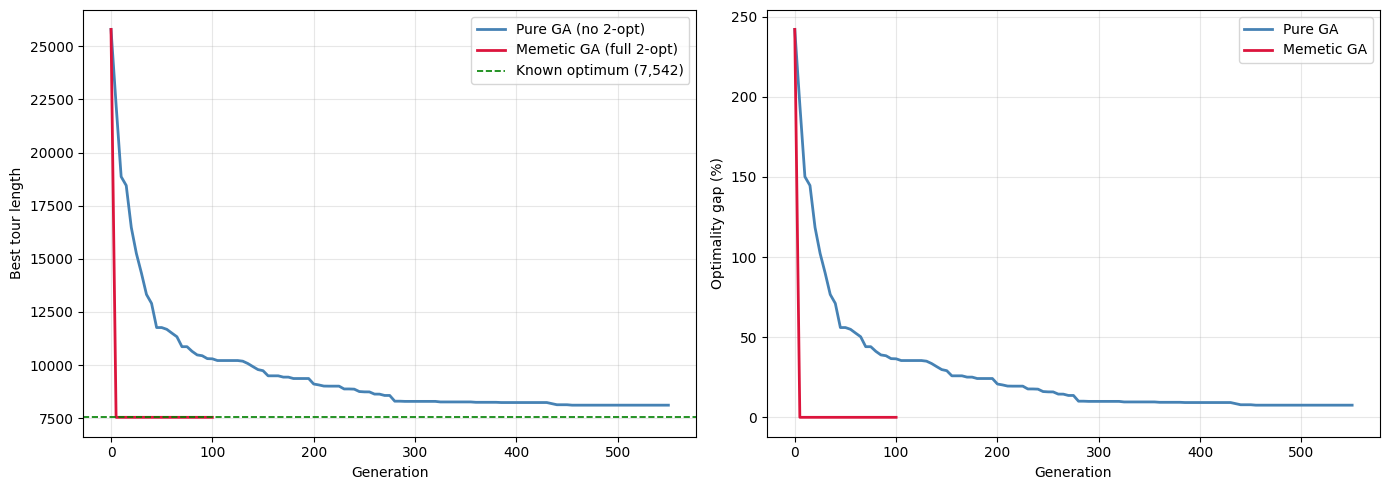

In [ ]:
# Convergence comparison Pure vs Memetic on berlin52 (Daan, p.15)
# Requires fresh logs: re-run the berlin52 cell with FORCE_RERUN=True if log_pure is None.
if log_pure is None:
    print("berlin52 pure-GA log not in memory (results were loaded from disk).")
    print("The figure uses the saved summary CSVs instead.")
    df_pure_log = load_csv('berlin52_pure_seed42_log.csv', subdir='single_seed')
    df_mem_log  = load_csv('berlin52_memetic_seed42_log.csv', subdir='single_seed')
else:
    df_pure_log = log_pure.to_dataframe()
    df_mem_log  = log_mem.to_dataframe()

if df_pure_log is not None and df_mem_log is not None:
    # exclude synthetic entries from the plotted series, if the column exists
    for _df in (df_pure_log, df_mem_log):
        if 'synthetic' in _df.columns:
            _df.drop(_df[_df['synthetic'] == True].index, inplace=True)
    bk = BEST_KNOWN['berlin52']
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(df_pure_log['generation'], df_pure_log['best_length'],
                 color='steelblue', lw=2, label='Pure GA (no 2-opt)')
    axes[0].plot(df_mem_log['generation'], df_mem_log['best_length'],
                 color='crimson', lw=2, label='Memetic GA (full 2-opt)')
    axes[0].axhline(bk, color='green', ls='--', lw=1.2, label=f'Known optimum ({bk:,})')
    axes[0].set_xlabel('Generation'); axes[0].set_ylabel('Best tour length')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(df_pure_log['generation'], (df_pure_log['best_length'] - bk) / bk * 100,
                 color='steelblue', lw=2, label='Pure GA')
    axes[1].plot(df_mem_log['generation'], (df_mem_log['best_length'] - bk) / bk * 100,
                 color='crimson', lw=2, label='Memetic GA')
    axes[1].set_xlabel('Generation'); axes[1].set_ylabel('Optimality gap (%)')
    axes[1].legend(); axes[1].grid(alpha=0.3)
    plt.tight_layout()
    save_fig('fig_berlin52_convergence_pure_vs_memetic.png')
    plt.show()


## 10. Robustness Analysis (10 seeds, parallel, resumable)

Robustness = variability of the final optimality gap across 10 independent runs
(seeds 10–19); reported as mean, population SD, min and max. Memetic GA uses
**full 2-opt** for berlin52/eil76/rat99/kroA100 and **neighbour-list 2-opt (k=15)**
for kroA200/rd400 (recorded in the saved JSON). rat575 and pr1002 are excluded
(computational cost). Instances with a saved `robustness_<name>.json` are loaded,
not recomputed. Expected runtime on Colab Pro: ≈ 1–2 h (rd400 memetic dominates).

In [ ]:
import multiprocessing as _mp

def _robustness_worker(args):
    """Top-level worker for multiprocessing."""
    seed, inst_name, inst_coords, inst_dist, bk, cfg, use_2opt, use_nn = args
    import random as _r, numpy as _np, math as _m
    _r.seed(seed); _np.random.seed(seed)

    inst = {'name': inst_name, 'n': len(inst_coords), 'coords': inst_coords, 'dist': inst_dist}
    run_cfg = {**cfg, 'log_every': 99999}

    if use_nn:
        best_tour, best_len, _ = run_ga_nn(inst, run_cfg, verbose=False)
    else:
        best_tour, best_len, _ = run_ga(inst, run_cfg, use_2opt=use_2opt, verbose=False)

    gap = (best_len - bk) / bk * 100
    return seed, best_len, gap


def robustness_run(inst, cfg, use_2opt, seeds, use_nn=False, label=''):
    n_workers = min(N_CORES, len(seeds))
    args_list = [(s, inst['name'], inst['coords'], inst['dist'],
                  BEST_KNOWN[inst['name']], cfg, use_2opt, use_nn)
                 for s in seeds]
    results = []
    if n_workers > 1 and ON_COLAB:
        try:
            ctx = _mp.get_context('fork')
            with ctx.Pool(processes=n_workers) as pool:
                raw = pool.map(_robustness_worker, args_list)
            results = sorted(raw, key=lambda x: x[0])
            print(f"  [{label}] Parallel ({n_workers} workers) done.")
        except Exception as e:
            print(f"  [{label}] Parallel failed ({e}), sequential...")
            for a in args_list:
                results.append(_robustness_worker(a))
    else:
        for a in args_list:
            s, bl, gap = _robustness_worker(a)
            results.append((s, bl, gap))
            print(f"  [{label}] seed={s}: {bl:,}  gap={gap:.2f}%")
    return results

print(f"Robustness runner ready. N_CORES={N_CORES}")


Robustness runner ready. N_CORES=2


In [ ]:
# Robustness for all 6 instances
N_RUNS = 10

multi_results = {}

# Instances that use neighbour-list 2-opt for memetic
NN_INSTANCES = {'kroA200', 'rd400'}
# Memetic GA runs for all 6 robustness instances
MEMETIC_ROBUSTNESS_INSTANCES = ['berlin52', 'eil76', 'rat99', 'kroA100', 'kroA200', 'rd400']

for name in ROBUSTNESS_INSTANCES:
    inst = INSTANCES[name]
    bk   = BEST_KNOWN[name]
    cfg  = {**CONFIGS.get(name, {**CONFIG, 'patience': PATIENCE_SCALE[name]}), 'log_every': 99999}
    use_nn = name in NN_INSTANCES

    # Resume: load saved robustness results if present
    saved = load_json(f'robustness_{name}.json', subdir='robustness')
    if saved and not FORCE_RERUN and saved.get('seeds') == SEEDS:
        multi_results[(name, 'pure')]    = saved['pure']
        multi_results[(name, 'memetic')] = saved['memetic']
        print(f"{name}: robustness loaded from saved JSON — skipped.")
        continue
    if name in HEAVY_INSTANCES and not RUN_HEAVY:
        print(f"{name}: no saved robustness result (set RUN_HEAVY=True)")
        continue

    import time as _t
    print(f"\n{name} | n={inst['n']} | Pure GA ({N_RUNS} seeds)...")
    t0 = _t.time()
    raw_pure = robustness_run(inst, cfg, use_2opt=False, seeds=SEEDS, label=f'{name}/pure')
    pure_gaps = [r[2] for r in raw_pure]
    pure_lens = [r[1] for r in raw_pure]
    multi_results[(name, 'pure')] = {'gaps': pure_gaps, 'lens': pure_lens}
    print(f"  mean={np.mean(pure_gaps):.2f}%  SD={np.std(pure_gaps):.2f}%  "
          f"min={np.min(pure_gaps):.2f}%  max={np.max(pure_gaps):.2f}%  ({_t.time()-t0:.0f}s)")

    print(f"  Memetic GA ({name}){'  [neighbour-list k=15]' if use_nn else ''}...")
    t0 = _t.time()
    raw_mem = robustness_run(inst, cfg, use_2opt=True, seeds=SEEDS, use_nn=use_nn, label=f'{name}/memetic')
    mem_gaps = [r[2] for r in raw_mem]
    mem_lens = [r[1] for r in raw_mem]
    multi_results[(name, 'memetic')] = {'gaps': mem_gaps, 'lens': mem_lens}
    print(f"  mean={np.mean(mem_gaps):.2f}%  SD={np.std(mem_gaps):.2f}%  "
          f"min={np.min(mem_gaps):.2f}%  max={np.max(mem_gaps):.2f}%  ({_t.time()-t0:.0f}s)")

    # Checkpoint to Drive immediately
    save_json({'instance': name, 'seeds': SEEDS,
               'pure': {'gaps': pure_gaps, 'lens': pure_lens},
               'memetic': {'gaps': mem_gaps, 'lens': mem_lens,
                           '2opt_type': 'neighbour-list k=15' if use_nn else 'full O(n^2)'}},
              f'robustness_{name}.json', subdir='robustness')


berlin52: robustness loaded from saved JSON — skipped.
eil76: robustness loaded from saved JSON — skipped.
rat99: robustness loaded from saved JSON — skipped.
kroA100: robustness loaded from saved JSON — skipped.
kroA200: robustness loaded from saved JSON — skipped.
rd400: robustness loaded from saved JSON — skipped.


In [ ]:
# TABLE 5: Robustness summary
rows = []
for name in ROBUSTNESS_INSTANCES:
    bk = BEST_KNOWN[name]
    for alg in ['pure', 'memetic']:
        key = (name, alg)
        d = multi_results.get(key)
        if d:
            rows.append({'Instance': name, 'n': INSTANCES[name]['n'],
                         'Algorithm': 'Pure GA' if alg=='pure' else 'Memetic GA',
                         'Best known': bk,
                         'Mean gap (%)': round(np.mean(d['gaps']), 2),
                         'SD (%)': round(np.std(d['gaps']), 2),
                         'Min (%)': round(np.min(d['gaps']), 2),
                         'Max (%)': round(np.max(d['gaps']), 2)})
        else:
            rows.append({'Instance': name, 'n': INSTANCES[name]['n'],
                         'Algorithm': 'Pure GA' if alg=='pure' else 'Memetic GA',
                         'Best known': bk, 'Mean gap (%)': 'n/a',
                         'SD (%)': 'n/a', 'Min (%)': 'n/a', 'Max (%)': 'n/a'})

df_robust = pd.DataFrame(rows)
print("TABLE 5 -- Robustness (10 runs, seeds 10-19):")
print(df_robust.to_string(index=False))
print("\nNote: SD = population std (np.std, ddof=0). "
      "rat575 and pr1002 excluded due to compute cost.")
save_csv(df_robust, 'table_robustness.csv', subdir='tables')


TABLE 5 -- Robustness (10 runs, seeds 10-19):
Instance   n  Algorithm  Best known  Mean gap (%)  SD (%)  Min (%)  Max (%)
berlin52  52    Pure GA        7542          8.97    3.50     2.60    12.57
berlin52  52 Memetic GA        7542          0.00    0.00     0.00     0.00
   eil76  76    Pure GA         538         12.36    3.65     5.95    17.66
   eil76  76 Memetic GA         538          0.00    0.00     0.00     0.00
   rat99  99    Pure GA        1211         19.75    5.46    13.71    32.87
   rat99  99 Memetic GA        1211          0.00    0.00     0.00     0.00
 kroA100 100    Pure GA       21282         15.03    4.07    10.26    24.79
 kroA100 100 Memetic GA       21282          0.02    0.00     0.02     0.02
 kroA200 200    Pure GA       29368         77.27    3.94    69.41    84.92
 kroA200 200 Memetic GA       29368          0.00    0.00     0.00     0.00
   rd400 400    Pure GA       15281        225.15    8.78   209.66   245.40
   rd400 400 Memetic GA       15281       

### 10.1 Robustness bar chart (plotting only)

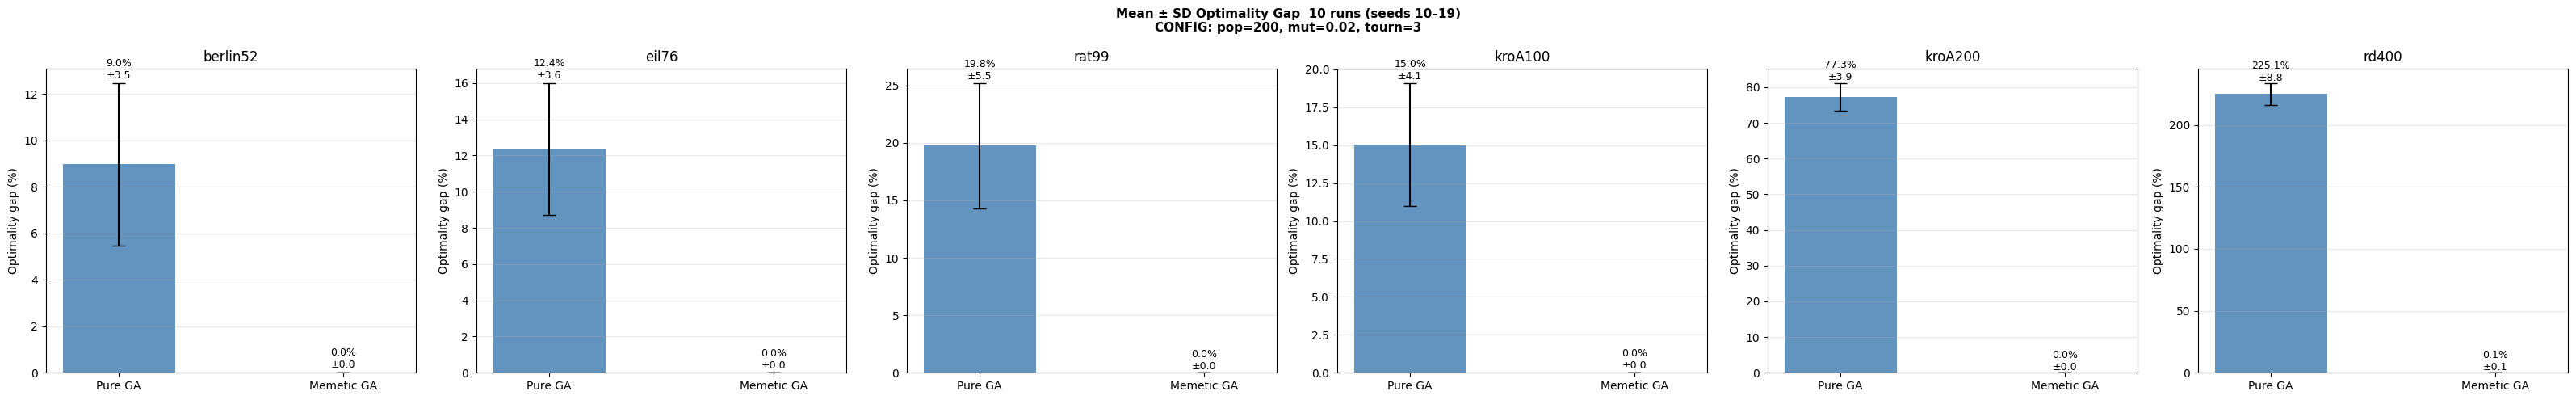

In [ ]:
import matplotlib.pyplot as plt

# Only plot instances where both pure and memetic results are available
plot_instances = [n for n in INSTANCES.keys() if (n, "memetic") in multi_results]

fig, axes = plt.subplots(1, len(plot_instances), figsize=(5*len(plot_instances)+2, 5))
if len(plot_instances) == 1:
    axes = [axes]

for ax, name in zip(axes, plot_instances):
    pure_gaps = multi_results[(name,"pure")]["gaps"]
    mem_gaps  = multi_results[(name,"memetic")]["gaps"]
    means = [np.mean(pure_gaps), np.mean(mem_gaps)]
    stds  = [np.std(pure_gaps),  np.std(mem_gaps)]
    bars = ax.bar([0,1], means, yerr=stds, color=["steelblue","crimson"],
                  capsize=6, alpha=0.85, width=0.5,
                  error_kw=dict(elinewidth=1.5, ecolor="black"))
    ax.set_xticks([0,1]); ax.set_xticklabels(["Pure GA","Memetic GA"])
    ax.set_ylabel("Optimality gap (%)"); ax.set_title(name)
    ax.grid(axis="y", alpha=0.3)
    for bar, mean, std in zip(bars, means, stds):
        ax.text(bar.get_x()+bar.get_width()/2, mean+std+0.1,
                f"{mean:.1f}%\n±{std:.1f}", ha="center", va="bottom", fontsize=9)

fig.suptitle(
    f"Mean ± SD Optimality Gap  {N_RUNS} runs (seeds {SEEDS[0]}–{SEEDS[-1]})\n"
    f"CONFIG: pop={CONFIG['population_size']}, mut={CONFIG['mutation_prob']}, tourn={CONFIG['tournament_size']}",
    fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()


## 11. Explanation Framework (corrected)

Five analyses, all operating on the **non-synthetic** part of the search log:

1. **Contrastive edge evidence (corrected).** For each edge of the best tour, mean
   length of tours *without* vs. *with* the edge, computed **within the near-optimal
   pool** (tours ≤ 5% above the best logged length). This conditions on solution
   quality and removes the generation-stage confound of the previous all-generations
   variant (where "tours without the edge" were dominated by early random tours, so
   the contrast mostly measured search progress). The share of pool tours containing
   each edge is reported, and a reliability flag warns when the "without" group is
   small. *This is observational contrastive evidence over the empirical distribution
   of logged solutions — NOT a counterfactual explanation in the sense of Kurtz et
   al. (2025) / Kurtz (2025): nothing is intervened on and no model is re-solved.*
   The legacy all-generations variant is kept (`pool='all'`) for comparison only.
2. **Edge importance / frequency analysis.** Lift of an edge in the top-10% of
   logged tours vs. the whole log. Note: the ratio is **capped at
   1/top_percentile = 10 by construction**; edges with few observations are
   filtered via `min_obs`.
3. **Diverse near-optimal tours.** Greedy max–min selection on Jaccard distance
   between edge sets, plus the new grey/red comparison figure.
4. **Partial-solution (stable subpath) analysis — new.** Maximal contiguous
   segments of the best tour whose edges each appear in ≥ 80% of near-optimal
   tours: the parts of the recommendation that are structurally fixed across
   high-quality alternatives.
5. **Convergence & diversity analysis.** Best/average length and mean pairwise
   Jaccard diversity per logged generation (synthetic entries excluded).

*Implementation note: edge sets are encoded as sorted integer arrays (code = min(a,b)·n + max(a,b)) and all membership/Jaccard operations use binary search/merge. The previous frozenset-based pool needed ~8 GB for the pr1002 log and crashed the Colab session; the encoded pool needs ~0.3 GB.*


In [ ]:
# ---------------------------------------------------------------------------
# 11.1 Contrastive edge evidence (corrected; vectorized, memory-efficient)
# ---------------------------------------------------------------------------
def contrastive_edge_evidence(best_tour, log, dist, top_k=10,
                              pool='near_optimal', threshold=None,
                              min_without=30, verbose=True):
    """
    Observational edge-level contrastive evidence from the search log.

    For each edge e of the best tour, compares the mean length of pool tours
    WITHOUT e against pool tours WITH e:

        contrastive_impact(e) = mean_length(without e) - mean_length(with e).

    pool='near_optimal' (default): pool = logged tours within `threshold`
        (default CONFIG_BASE['near_optimal_threshold']) of the best logged
        length. Conditioning on quality removes the generation-stage confound
        of the unrestricted log.
    pool='all': legacy unrestricted pool. Kept for comparison only; its
        impacts mostly reflect search progress, not edge value.

    Additional columns:
        share_with : fraction of pool tours containing the edge
        n_without  : size of the contrast ("without") group
        reliable   : n_without >= min_without
        stable     : edge present in ALL pool tours (no contrast group exists;
                     impact is NaN — itself strong evidence of structural
                     stability)

    NOTE: this is NOT a counterfactual explanation (no intervention, no
    re-optimisation). It is contrastive evidence over the empirical
    distribution of solutions observed during the search; synthetic log
    entries are excluded.

    Implementation: edge membership is evaluated with binary search on the
    encoded edge arrays and aggregated with one boolean matrix product —
    feasible even for the pr1002 log (~40k tours).
    """
    if threshold is None:
        threshold = CONFIG_BASE['near_optimal_threshold']

    tours, lengths, edge_codes = log.flat_pool()
    if not tours:
        raise ValueError("Search log contains no non-synthetic entries.")

    lengths = np.asarray(lengths, dtype=np.float64)
    if pool == 'near_optimal':
        cutoff = lengths.min() * (1 + threshold)
        idx = np.where(lengths <= cutoff)[0]
        if verbose:
            print(f"Contrastive pool: {len(idx):,} near-optimal tours "
                  f"(<= {threshold*100:.0f}% above best logged length).")
    elif pool == 'all':
        idx = np.arange(len(lengths))
        if verbose:
            print(f"Contrastive pool: ALL {len(idx):,} logged tours "
                  f"(legacy variant — generation-stage confound applies).")
    else:
        raise ValueError("pool must be 'near_optimal' or 'all'")

    pool_lengths = lengths[idx]
    P = len(idx)
    n = len(best_tour)
    n_inst = n
    best_pairs = [(best_tour[k], best_tour[(k+1) % n]) for k in range(n)]
    best_codes = np.array([edge_code(a, b, n_inst) for a, b in best_pairs],
                          dtype=np.int64)

    # membership matrix M[r, k] = pool tour r contains best edge k
    M = np.empty((P, n), dtype=bool)
    for r, i_tour in enumerate(idx):
        M[r] = codes_contain(edge_codes[i_tour], best_codes)

    n_with    = M.sum(axis=0)
    n_without = P - n_with
    sum_with  = M.astype(np.float64).T @ pool_lengths
    total     = pool_lengths.sum()
    with np.errstate(invalid='ignore', divide='ignore'):
        mean_with    = np.where(n_with > 0, sum_with / np.maximum(n_with, 1),
                                np.nan)
        mean_without = np.where(n_without > 0,
                                (total - sum_with) / np.maximum(n_without, 1),
                                np.nan)
    impact = mean_without - mean_with

    rows = []
    for k, (a, b) in enumerate(best_pairs):
        stable = n_without[k] == 0
        rows.append({'edge': f"{a}-{b}", 'city_a': a, 'city_b': b,
                     'edge_weight': int(dist[a][b]),
                     'mean_length_with': (round(float(mean_with[k]), 1)
                                          if n_with[k] else float('nan')),
                     'mean_length_without': (round(float(mean_without[k]), 1)
                                             if not stable else float('nan')),
                     'contrastive_impact': (round(float(impact[k]), 1)
                                            if not stable else float('nan')),
                     'share_with': round(float(n_with[k] / P), 4),
                     'n_without': int(n_without[k]),
                     'reliable': bool(n_without[k] >= min_without) and not stable,
                     'stable': bool(stable)})

    df = pd.DataFrame(rows)
    n_stable     = int(df['stable'].sum())
    n_unreliable = int(((~df['reliable']) & (~df['stable'])).sum())
    if verbose:
        if n_stable:
            print(f"  {n_stable} best-tour edge(s) appear in ALL pool tours "
                  f"(fully stable; no contrast group).")
        if n_unreliable:
            print(f"  WARNING: {n_unreliable} edge(s) have a 'without' group "
                  f"smaller than {min_without} tours — contrast unreliable.")
    df = df.sort_values(['contrastive_impact'], ascending=False,
                        na_position='last').reset_index(drop=True)
    return df


# ---------------------------------------------------------------------------
# 11.2 Edge importance / frequency analysis (vectorized)
# ---------------------------------------------------------------------------
def edge_frequency_analysis(log, n_cities, top_percentile=0.10, min_obs=None):
    """
    Edge frequency lift in good solutions (synthetic entries excluded).

        importance_ratio(e) = (freq_top(e)/n_top) / (freq_all(e)/n_total)

    where freq_*(e) count edge OCCURRENCES, n_top is the NUMBER OF TOURS in the
    top `top_percentile` of the log by length and n_total the total number of
    logged tours. Ratio > 1: the edge appears disproportionately often in good
    solutions. NOTE: the ratio is capped at 1/top_percentile (= 10 for the
    default 10%) by construction — an edge occurring only in top tours attains
    exactly this cap. `min_obs` filters out edges with too few observations,
    whose ratios are dominated by sampling noise.
    De Bock et al. (2024), attribution perspective.
    """
    tours, lengths, edge_codes = log.flat_pool()
    if not tours:
        raise ValueError("Search log contains no non-synthetic entries.")

    n_total = len(tours)
    n_top   = max(int(n_total * top_percentile), 1)
    top_idx = np.argsort(np.asarray(lengths))[:n_top]

    all_codes = np.concatenate(edge_codes)
    uniq, cnt_all = np.unique(all_codes, return_counts=True)
    del all_codes
    top_codes = np.concatenate([edge_codes[i] for i in top_idx])
    uniq_top, cnt_top_u = np.unique(top_codes, return_counts=True)
    del top_codes

    cnt_top = np.zeros_like(cnt_all)
    pos = np.searchsorted(uniq, uniq_top)
    cnt_top[pos] = cnt_top_u

    ratio = (cnt_top / n_top) / (cnt_all / n_total)
    a = (uniq // n_cities).astype(int)
    b = (uniq %  n_cities).astype(int)
    df = pd.DataFrame({'edge': [f"{ai}-{bi}" for ai, bi in zip(a, b)],
                       'city_a': a, 'city_b': b,
                       'freq_all': cnt_all, 'freq_top': cnt_top,
                       'importance_ratio': np.round(ratio, 3)})
    df.attrs['n_total'], df.attrs['n_top'] = n_total, int(n_top)
    if min_obs is not None:
        n_excluded = int((df['freq_all'] < min_obs).sum())
        if n_excluded:
            print(f"  edge_frequency_analysis: {n_excluded} edge(s) with "
                  f"freq_all < {min_obs} excluded (unreliable ratios; "
                  f"cap = {1/top_percentile:.0f} by construction).")
        df = df[df['freq_all'] >= min_obs]
    return df.sort_values('importance_ratio', ascending=False).reset_index(drop=True)


def plot_edge_heatmap(coords, df_edge, best_tour=None, n_top=None,
                      title="Edge importance"):
    """Every edge of the best tour coloured by its importance ratio, with the
    tour drawn underneath in light grey so the reader can relate edge
    importance to the final solution (Daan, p.20). All best-tour edges are
    coloured (not only the top ones); the colour scale spans the full range of
    importance ratios observed on the best-tour edges."""
    fig, ax = plt.subplots(figsize=(9, 7))
    imp = {}
    for _, row in df_edge.iterrows():
        a, b = int(row['city_a']), int(row['city_b'])
        imp[(min(a, b), max(a, b))] = row['importance_ratio']

    if best_tour is not None:
        xs = [coords[c][0] for c in best_tour] + [coords[best_tour[0]][0]]
        ys = [coords[c][1] for c in best_tour] + [coords[best_tour[0]][1]]
        ax.plot(xs, ys, color='lightgrey', lw=1.0, zorder=2,
                label='best tour (algorithm output)')
        tour_edges = [(min(best_tour[k], best_tour[(k + 1) % len(best_tour)]),
                       max(best_tour[k], best_tour[(k + 1) % len(best_tour)]))
                      for k in range(len(best_tour))]
        ratios = [imp.get(e, 0.0) for e in tour_edges]
        vmin, vmax = min(ratios), max(ratios)
        span = (vmax - vmin) or 1.0
        cmap = plt.get_cmap('YlOrRd')
        for e, r in zip(tour_edges, ratios):
            t = (r - vmin) / span
            (i, j) = e
            ax.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]],
                    color=cmap(t), linewidth=1.0 + 3.0 * t, alpha=0.95, zorder=4)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin, vmax))
    else:
        top = df_edge.head(n_top or 20)
        vmax = top['importance_ratio'].max()
        cmap = plt.get_cmap('YlOrRd')
        for _, row in top.iterrows():
            i, j = int(row['city_a']), int(row['city_b'])
            r = row['importance_ratio'] / vmax
            ax.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]],
                    color=cmap(r), linewidth=0.5 + 3.5 * r, alpha=0.9, zorder=4)
        sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, vmax))

    ax.scatter([c[0] for c in coords], [c[1] for c in coords],
               s=30, zorder=5, color='navy')
    sm.set_array([])
    plt.colorbar(sm, ax=ax, label='Importance ratio (best-tour edges)')
    if best_tour is not None:
        ax.legend(loc='best', fontsize=8)
    ax.set_title(title)
    ax.set_xlabel("x coordinate"); ax.set_ylabel("y coordinate")
    ax.tick_params(labelsize=7)
    plt.tight_layout()


In [ ]:
# ---------------------------------------------------------------------------
# 11.3 Diverse near-optimal tours + grey/red comparison figure
# ---------------------------------------------------------------------------
def get_diverse_near_optimal(log, best_length, threshold=None, n_select=4):
    """
    Diverse set of near-optimal tours (synthetic entries excluded).
    Pool: unique logged tours within (1+threshold)*best_length. Selection:
    greedy max-min on Jaccard distance between edge sets, starting from the
    best tour (= algorithm output).
    Deduplication uses a digest of the sorted edge-code array: for a
    Hamiltonian cycle the undirected edge set determines the tour up to
    orientation and rotation, so this removes all re-encodings of the same
    cycle. Jaccard distances are computed on the encoded arrays (binary
    merge), keeping the pr1002 pool (~40k tours) tractable.
    """
    import hashlib
    if threshold is None:
        threshold = CONFIG_BASE['near_optimal_threshold']
    tours, lengths, edge_codes = log.flat_pool()
    cutoff = best_length * (1 + threshold)

    candidates, cand_codes, seen = [], [], set()
    for t, l, codes in zip(tours, lengths, edge_codes):
        if l <= cutoff:
            key = hashlib.blake2b(codes.tobytes(), digest_size=16).digest()
            if key not in seen:
                seen.add(key)
                candidates.append((list(t), int(l)))
                cand_codes.append(codes)
    if not candidates:
        print(f"Warning: no near-optimal tours within {threshold*100:.1f}% of best.")
        return [], 0
    pool_size = len(candidates)
    print(f"Near-optimal pool: {pool_size:,} unique tours within "
          f"{threshold*100:.0f}% of best ({best_length:,}).")
    if pool_size < n_select:
        print(f"Warning: only {pool_size} unique tour(s) — returning all "
              f"(requested {n_select}).")

    best_idx = int(np.argmin([l for _, l in candidates]))
    selected = [best_idx]
    min_dist = np.array([jaccard_codes(codes, cand_codes[best_idx])
                         for codes in cand_codes])
    for _ in range(min(n_select - 1, pool_size - 1)):
        for s in selected:
            min_dist[s] = -1.0
        nxt = int(np.argmax(min_dist))
        if min_dist[nxt] < 0:
            break
        selected.append(nxt)
        d_new = np.array([jaccard_codes(codes, cand_codes[nxt])
                          for codes in cand_codes])
        min_dist = np.minimum(min_dist, d_new)
    return [candidates[i] for i in selected], pool_size


def diverse_tours_report(diverse_tours, best_known):
    """Pairwise Jaccard distance matrix + mean over pairs."""
    code_sets = [encode_tour_edges(t) for t, _ in diverse_tours]
    k = len(diverse_tours)
    mat = np.zeros((k, k))
    pairs = []
    for i in range(k):
        for j in range(k):
            if i != j:
                mat[i, j] = jaccard_codes(code_sets[i], code_sets[j])
                if i < j:
                    pairs.append(mat[i, j])
    mean_jd = float(np.mean(pairs)) if pairs else 0.0
    labels = ['Global best'] + [f'Alt {i}' for i in range(1, k)]
    df = pd.DataFrame(np.round(mat, 4), index=labels, columns=labels)
    return df, mean_jd


def plot_diverse_tours_panel(name, coords, diverse_tours, best_known,
                             threshold=None, save_name=None):
    """
    Grey/red comparison figure:
      panel 1            : global best tour (algorithm output, blue)
      following panels   : alternatives — grey edges shared with the global
                           best, red edges that differ; each annotated with
                           length, optimality gap and number of differing edges.
    """
    if threshold is None:
        threshold = CONFIG_BASE['near_optimal_threshold']
    if not diverse_tours:
        print("No diverse tours to plot."); return None
    best_tour_, best_len_ = diverse_tours[0]
    best_edges = tour_edge_set(best_tour_)
    alt_jd = [jaccard_dist(tour_edge_set(t), best_edges) for t, _ in diverse_tours]

    k = len(diverse_tours)
    ncols = min(3, k)
    nrows = int(np.ceil(k / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 4.6 * nrows))
    axes = np.atleast_1d(axes).ravel()

    _, mean_jd = diverse_tours_report(diverse_tours, best_known)

    for rank, (ax, (tour, length)) in enumerate(zip(axes, diverse_tours)):
        gap = (length - best_known) / best_known * 100
        n_t = len(tour)
        if rank == 0:
            xs = [coords[c][0] for c in tour] + [coords[tour[0]][0]]
            ys = [coords[c][1] for c in tour] + [coords[tour[0]][1]]
            ax.plot(xs, ys, color='steelblue', lw=1.4, zorder=3)
            ax.set_title(f"GLOBAL BEST (algorithm output)\n"
                         f"Length: {length:,}  |  Gap: {gap:.2f}%",
                         fontsize=10, color='steelblue', fontweight='bold')
        else:
            n_diff = 0
            for kk in range(n_t):
                i, j = tour[kk], tour[(kk + 1) % n_t]
                shared = frozenset((i, j)) in best_edges
                if not shared:
                    n_diff += 1
                ax.plot([coords[i][0], coords[j][0]],
                        [coords[i][1], coords[j][1]],
                        color=('grey' if shared else 'red'),
                        lw=(0.9 if shared else 2.4),
                        alpha=(0.65 if shared else 1.0),
                        zorder=(3 if shared else 4))
            ax.set_title(f"ALTERNATIVE {rank}  (differing edges: {n_diff})\n"
                         f"Length: {length:,}  |  Gap: {gap:.2f}%  |  "
                         f"Jaccard to best: {alt_jd[rank]:.3f}", fontsize=9.5)
        ax.scatter([c[0] for c in coords], [c[1] for c in coords],
                   s=14, zorder=5, color='navy')
        ax.tick_params(labelsize=6)
    for ax in axes[k:]:
        ax.axis('off')

    fig.suptitle(
        f"{name} — Diverse near-optimal tours (within {threshold*100:.0f}% of best)\n"
        f"Grey = shared with global best   |   Red = differs from global best   |   "
        f"Mean pairwise Jaccard distance: {mean_jd:.3f}",
        fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.93])
    if save_name:
        save_fig(save_name)
    return mean_jd


# ---------------------------------------------------------------------------
# 11.4 Partial-solution (stable subpath) analysis — NEW
# ---------------------------------------------------------------------------
def partial_solution_analysis(best_tour, log, dist, threshold=None,
                              min_share=0.80):
    """
    Stable subpaths of the best tour across the near-optimal pool.

    For each edge of the best tour, share(e) = fraction of near-optimal pool
    tours containing e. Maximal contiguous runs of best-tour edges with
    share(e) >= min_share form 'stable segments': parts of the recommended
    route that are preserved across structurally different high-quality
    alternatives. Complements the diverse-tours view: it identifies WHICH
    local structures stay fixed while the rest of the tour varies.
    (Attribution perspective: De Bock et al., 2024; solution-set/diversity
    perspective on explaining evolutionary search: Zhou et al., 2025.)
    Returns (df_segments, df_edges, coverage) where coverage is the fraction
    of best-tour edges that are stable.
    """
    if threshold is None:
        threshold = CONFIG_BASE['near_optimal_threshold']
    tours, lengths, edge_codes = log.flat_pool()
    lengths = np.asarray(lengths, dtype=np.float64)
    cutoff = lengths.min() * (1 + threshold)
    pool_idx = np.where(lengths <= cutoff)[0]
    n_pool = len(pool_idx)

    n = len(best_tour)
    best_codes = np.array([edge_code(best_tour[k], best_tour[(k+1) % n], n)
                           for k in range(n)], dtype=np.int64)
    counts = np.zeros(n, dtype=np.int64)
    for i_tour in pool_idx:
        counts += codes_contain(edge_codes[i_tour], best_codes)
    share = counts / n_pool
    stable = share >= min_share
    coverage = float(stable.mean())

    df_edges = pd.DataFrame({
        'pos': range(n),
        'edge': [f"{best_tour[k]}-{best_tour[(k+1) % n]}" for k in range(n)],
        'share': np.round(share, 4),
        'stable': stable})

    # maximal contiguous stable runs on the cycle (rotate to an unstable edge)
    segments = []
    if stable.all():
        segments.append(list(range(n)))
    elif stable.any():
        start = int(np.argmin(stable))           # an unstable position
        order = [(start + k) % n for k in range(n)]
        run = []
        for p in order:
            if stable[p]:
                run.append(p)
            elif run:
                segments.append(run); run = []
        if run:
            segments.append(run)

    rows = []
    for sid, seg in enumerate(sorted(segments, key=len, reverse=True), 1):
        cities = [best_tour[seg[0]]] + [best_tour[(p + 1) % n] for p in seg]
        seg_len = int(sum(dist[best_tour[p]][best_tour[(p + 1) % n]] for p in seg))
        rows.append({'segment': sid, 'n_edges': len(seg),
                     'cities': '-'.join(map(str, cities)),
                     'segment_length': seg_len,
                     'mean_share': round(float(share[seg].mean()), 4),
                     'min_share': round(float(share[seg].min()), 4)})
    df_segments = pd.DataFrame(rows)
    print(f"Partial-solution analysis: {len(segments)} stable segment(s); "
          f"{coverage*100:.1f}% of best-tour edges appear in >= {min_share*100:.0f}% "
          f"of {n_pool:,} near-optimal tours.")
    return df_segments, df_edges, coverage


def _count_segments_from_stable(stable):
    """Number of maximal contiguous stable runs on a cyclic tour."""
    stable = list(stable)
    n = len(stable)
    if all(stable):
        return 1
    if not any(stable):
        return 0
    start = stable.index(False)
    order = stable[start:] + stable[:start]
    return sum(1 for a, b in zip([False] + order[:-1], order) if b and not a)


def plot_stable_segments_compare(name, coords, best_tour, df_edges,
                                 thresholds=(0.80, 0.90), save_name=None):
    """Best tour drawn side by side for several share thresholds, so the reader
    can see how the stable skeleton fragments as the threshold increases.
    Uses the per-edge share already in df_edges (no recomputation)."""
    share = df_edges['share'].to_numpy()
    n = len(best_tour)
    m = len(thresholds)
    fig, axes = plt.subplots(1, m, figsize=(6.0 * m, 6.0), squeeze=False)
    axes = axes[0]
    for ax, thr in zip(axes, thresholds):
        stable = share >= thr
        for k in range(n):
            i, j = best_tour[k], best_tour[(k + 1) % n]
            st = bool(stable[k])
            ax.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]],
                    color=('darkgreen' if st else 'lightgrey'),
                    lw=(2.6 if st else 1.0), alpha=(1.0 if st else 0.8),
                    zorder=(4 if st else 3))
        ax.scatter([c[0] for c in coords], [c[1] for c in coords],
                   s=20, zorder=5, color='navy')
        cov = stable.mean() * 100
        n_seg = _count_segments_from_stable(stable)
        ax.set_title(f"share >= {thr*100:.0f}%\n"
                     f"{cov:.0f}% of edges stable, {n_seg} segment(s)",
                     fontsize=11)
        ax.set_xlabel("x coordinate"); ax.set_ylabel("y coordinate")
        ax.tick_params(labelsize=7)
    fig.suptitle(f"{name} — stable subpaths of the best tour at two thresholds "
                 f"(green = stable edge)", fontsize=12)
    plt.tight_layout(rect=(0, 0, 1, 0.96))
    if save_name:
        save_fig(save_name)


STABLE_THRESHOLDS = [0.70, 0.80, 0.90, 0.95, 0.98]

def stable_threshold_sensitivity(df_edges, thresholds=None):
    """
    Sensitivity of the stable-subpath analysis to the share threshold s.

    Re-uses the per-edge shares already computed by partial_solution_analysis,
    so this is pure post-processing (no GA reruns). For each threshold it
    reports: number of stable edges, coverage (%), number of maximal
    contiguous stable segments and the size of the largest segment.
    Motivation: the default s = 0.80 is an empirical choice; showing how
    coverage and segmentation react to s demonstrates how robust the
    "stable skeleton" finding is to this choice.
    """
    if thresholds is None:
        thresholds = STABLE_THRESHOLDS
    share = df_edges['share'].to_numpy()
    n = len(share)
    rows = []
    for thr in thresholds:
        stable = share >= thr
        n_stable = int(stable.sum())
        if stable.all():
            n_seg, largest = 1, n
        elif stable.any():
            start = int(np.argmin(stable))
            order = [(start + k) % n for k in range(n)]
            n_seg, largest, run = 0, 0, 0
            for p in order:
                if stable[p]:
                    run += 1
                else:
                    if run:
                        n_seg += 1; largest = max(largest, run); run = 0
            if run:
                n_seg += 1; largest = max(largest, run)
        else:
            n_seg, largest = 0, 0
        rows.append({'threshold': thr,
                     'stable_edges': n_stable,
                     'coverage_%': round(100.0 * n_stable / n, 1),
                     'n_segments': n_seg,
                     'largest_segment': largest})
    return pd.DataFrame(rows)

def plot_stable_segments(name, coords, best_tour, df_edges, save_name=None,
                         min_share=0.80):
    """Best tour with stable edges (share >= min_share) highlighted."""
    fig, ax = plt.subplots(figsize=(9, 7))
    n = len(best_tour)
    for k in range(n):
        i, j = best_tour[k], best_tour[(k + 1) % n]
        st = bool(df_edges.iloc[k]['stable'])
        ax.plot([coords[i][0], coords[j][0]], [coords[i][1], coords[j][1]],
                color=('darkgreen' if st else 'lightgrey'),
                lw=(2.6 if st else 1.0), alpha=(1.0 if st else 0.8),
                zorder=(4 if st else 3))
    ax.scatter([c[0] for c in coords], [c[1] for c in coords],
               s=20, zorder=5, color='navy')
    cov = df_edges['stable'].mean() * 100
    # count maximal stable runs for the title annotation
    st = df_edges['stable'].tolist()
    if all(st):
        n_seg = 1
    else:
        k0 = st.index(False)
        order = st[k0:] + st[:k0]
        n_seg = sum(1 for a, b in zip([False] + order[:-1], order) if b and not a)
    ax.set_title(f"{name} — stable subpaths of the best tour\n"
                 f"Green = edge present in >= {min_share*100:.0f}% of near-optimal "
                 f"tours ({cov:.0f}% of edges, {n_seg} segment(s))", fontsize=11)
    ax.set_xlabel("x coordinate"); ax.set_ylabel("y coordinate")
    ax.tick_params(labelsize=7)
    plt.tight_layout()
    if save_name:
        save_fig(save_name)


# ---------------------------------------------------------------------------
# 11.5 Convergence & diversity analysis (synthetic entries excluded)
# ---------------------------------------------------------------------------
def convergence_and_diversity_explanation(log, best_known=None,
                                          sample_size=20, seed=None):
    """
    Per-generation convergence and structural-diversity statistics.
    Diversity = mean pairwise Jaccard distance between edge sets of
    `sample_size` sampled tours per logged generation. Synthetic entries
    (single-tour ensure_best records) are excluded — they would otherwise
    inject an artificial diversity of 0.
    Blum & Roli (2003); Talbi (2009).
    """
    if seed is not None:
        random.seed(seed)
    ridx = log.real_entries()
    if not ridx:
        raise ValueError("Search log contains no non-synthetic entries.")

    gens, bests, avgs, divers = [], [], [], []
    for k in ridx:
        gen_tours = log.all_tours[k]
        sample = random.sample(gen_tours, min(sample_size, len(gen_tours)))
        codes = [encode_tour_edges(t) for t in sample]
        dists = [jaccard_codes(codes[i], codes[j])
                 for i in range(len(codes)) for j in range(i + 1, len(codes))]
        divers.append(float(np.mean(dists)) if dists else 0.0)
        gens.append(log.generations[k])
        bests.append(log.best_lengths[k])
        avgs.append(log.avg_lengths[k])

    improvements = [0.0] + [bests[k-1] - bests[k] for k in range(1, len(bests))]
    df = pd.DataFrame({"generation": gens, "best_length": bests,
                       "avg_length": avgs, "diversity": divers,
                       "improvement": improvements})
    if best_known is not None:
        df["gap_%"] = (df["best_length"] - best_known) / best_known * 100

    # summary
    conv_gen = int(df.loc[df["best_length"] == df["best_length"].min(),
                          "generation"].iloc[0])
    init_div = df["diversity"].iloc[0]
    drop = df[df["diversity"] < 0.5 * init_div]
    drop_gen = int(drop["generation"].iloc[0]) if len(drop) else None
    print(f"  Total improvement : {bests[0]:,} -> {min(bests):,} "
          f"({(bests[0]-min(bests))/max(bests[0],1)*100:.1f}% of initial)")
    print(f"  Convergence gen   : {conv_gen} (first generation at final best)")
    print(f"  Diversity <50%    : gen {drop_gen} (initial diversity {init_div:.4f})")
    print(f"  Final diversity   : {df['diversity'].iloc[-1]:.4f}")
    return df


def plot_convergence_diversity(df_conv, name, best_known, save_name=None):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
    axes[0].plot(df_conv['generation'], df_conv['best_length'],
                 color='steelblue', lw=2, label='Best tour length')
    axes[0].plot(df_conv['generation'], df_conv['avg_length'],
                 color='orange', lw=1.2, alpha=0.8, label='Avg tour length')
    axes[0].axhline(best_known, color='green', ls='--', lw=1.2,
                    label=f'Known optimum ({best_known:,})')
    conv_gen_plot = int(df_conv.loc[df_conv['best_length'] ==
                                    df_conv['best_length'].min(),
                                    'generation'].iloc[0])
    axes[0].axvline(conv_gen_plot, color='grey', ls=':',
                    label=f'convergence (gen {conv_gen_plot})')
    axes[0].set_xlabel('Generation'); axes[0].set_ylabel('Tour length')
    axes[0].set_title('Convergence'); axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    init_div = df_conv['diversity'].iloc[0]
    axes[1].plot(df_conv['generation'], df_conv['diversity'],
                 color='crimson', lw=1.6, label='Jaccard diversity')
    drop = df_conv[df_conv['diversity'] < 0.5 * init_div]
    if len(drop):
        axes[1].axvline(drop['generation'].iloc[0], color='grey', ls=':',
                        label=f"50% drop (gen {int(drop['generation'].iloc[0])})")
    axes[1].set_xlabel('Generation')
    axes[1].set_ylabel('Mean pairwise Jaccard distance')
    axes[1].set_title('Population diversity'); axes[1].legend(fontsize=8)
    axes[1].grid(alpha=0.3)

    axes[2].bar(df_conv['generation'], df_conv['improvement'],
                width=max(df_conv['generation'].max() / 120, 1.0),
                color='steelblue')
    axes[2].set_xlabel('Generation'); axes[2].set_ylabel('Improvement (units)')
    axes[2].set_title('Improvement per logged generation'); axes[2].grid(alpha=0.3)

    fig.suptitle(f'{name} — convergence and diversity (memetic GA, seed={SEED})',
                 fontsize=12)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    if save_name:
        save_fig(save_name)


In [ ]:
# ---------------------------------------------------------------------------
# 11.6 Orchestrator: run the full explanation suite for one instance
# ---------------------------------------------------------------------------
def run_explanations(name, inst, best_tour_, best_length_, log_,
                     n_select=6, min_obs=None, top_k=10):
    """Apply all five analyses; save tables/figures; return a summary dict."""
    bk = BEST_KNOWN[name]
    coords = inst['coords']
    gap = (best_length_ - bk) / bk * 100
    print(f"\n{'='*64}\nExplanations — {name} (gap {gap:.2f}%)\n{'='*64}")

    # 1) contrastive evidence: corrected (near-optimal pool) + legacy comparison
    print("\n[1/5] Contrastive edge evidence (near-optimal pool)...")
    df_c = contrastive_edge_evidence(best_tour_, log_, inst['dist'],
                                     top_k=top_k, pool='near_optimal')
    save_csv(df_c, f'contrastive_nearopt_{name}.csv', subdir='explanations')
    print(df_c.head(top_k).to_string(index=False))
    df_c_all = contrastive_edge_evidence(best_tour_, log_, inst['dist'],
                                         top_k=top_k, pool='all', verbose=False)
    save_csv(df_c_all, f'contrastive_allpool_{name}.csv', subdir='explanations')

    df_c_rel = df_c[df_c['reliable']]
    top_edges = [(int(r.city_a), int(r.city_b))
                 for _, r in df_c_rel.head(top_k).iterrows()]
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    plot_tour(coords, best_tour_,
              title=f'{name} — best tour; top-{len(top_edges)} contrastive edges (red)',
              highlight_edges=top_edges, show_labels=(inst['n'] <= 100), ax=axes[0])
    dfp = df_c_rel.head(top_k)
    axes[1].barh(dfp['edge'], dfp['contrastive_impact'], color='steelblue')
    for _y, (_imp, _sh) in enumerate(zip(dfp['contrastive_impact'], dfp['share_with'])):
        axes[1].text(_imp, _y, f"  share {_sh:.3f}", va='center', fontsize=7.5,
                     color='#333333')
    axes[1].axvline(0, color='black', lw=0.8)
    axes[1].set_xlabel('Contrastive impact within near-optimal pool\n'
                       '(mean length without edge − with edge)')
    axes[1].set_ylabel('Edge')
    axes[1].set_title(f'{name} — contrastive edge evidence')
    axes[1].invert_yaxis()
    plt.tight_layout()
    save_fig(f'fig_{name}_contrastive_evidence.png')
    plt.show()

    # 2) edge importance / frequency
    print("\n[2/5] Edge importance / frequency analysis...")
    df_e = edge_frequency_analysis(log_, inst['n'], top_percentile=0.10,
                                   min_obs=min_obs)
    save_csv(df_e.head(50), f'edge_importance_{name}.csv', subdir='explanations')
    print(df_e.head(10).to_string(index=False))
    plot_edge_heatmap(coords, df_e, best_tour=best_tour_,
                      title=f'{name} — best-tour edges by importance ratio '
                            f'(grey: best tour)')
    save_fig(f'fig_{name}_edge_importance.png')
    plt.show()

    # 3) diverse near-optimal tours + grey/red panel
    print("\n[3/5] Diverse near-optimal tours...")
    diverse, pool_size = get_diverse_near_optimal(log_, best_length_,
                                                  n_select=n_select)
    mean_jd = None
    if diverse:
        df_jac, mean_jd = diverse_tours_report(diverse, bk)
        print("Pairwise Jaccard distances between selected tours:")
        print(df_jac.to_string())
        df_jac_out = df_jac.copy(); df_jac_out.insert(0, 'tour', df_jac_out.index)
        save_csv(df_jac_out, f'diverse_tours_jaccard_{name}.csv',
                 subdir='explanations')
        plot_diverse_tours_panel(name, coords, diverse, bk,
                                 save_name=f'fig_{name}_diverse_tours.png')
        plt.show()

    # 4) partial-solution (stable subpath) analysis
    print("\n[4/5] Partial-solution (stable subpath) analysis...")
    df_seg, df_edges_ps, coverage = partial_solution_analysis(
        best_tour_, log_, inst['dist'])
    save_csv(df_seg, f'stable_segments_{name}.csv', subdir='explanations')
    if len(df_seg):
        print(df_seg.head(10).to_string(index=False))

    # threshold sensitivity (pure post-processing of the per-edge shares)
    df_sens = stable_threshold_sensitivity(df_edges_ps)
    save_csv(df_sens, f'stable_sensitivity_{name}.csv', subdir='explanations')
    print("\nStable-subpath threshold sensitivity:")
    print(df_sens.to_string(index=False))
    plot_stable_segments(name, coords, best_tour_, df_edges_ps,
                         save_name=f'fig_{name}_stable_segments.png')
    plt.show()
    # paired comparison at two thresholds (used for berlin52 in the report,
    # but produced for every instance so the figure is always available)
    plot_stable_segments_compare(
        name, coords, best_tour_, df_edges_ps, thresholds=(0.80, 0.90),
        save_name=f'fig_{name}_stable_segments_compare.png')
    plt.show()

    # 5) convergence & diversity
    print("\n[5/5] Convergence and diversity analysis...")
    df_conv = convergence_and_diversity_explanation(log_, best_known=bk,
                                                    sample_size=20, seed=SEED)
    save_csv(df_conv, f'convergence_diversity_{name}.csv', subdir='explanations')
    plot_convergence_diversity(df_conv, name, bk,
                               save_name=f'fig_{name}_convergence_diversity.png')
    plt.show()

    conv_gen = int(df_conv.loc[df_conv['best_length'] ==
                               df_conv['best_length'].min(), 'generation'].iloc[0])
    df_c_ok = df_c[df_c['reliable']]
    summary = {
        'Instance': name,
        'n cities': inst['n'],
        'Optimality gap (%)': round(gap, 2),
        'Near-optimal pool size': pool_size,
        'Stable edges (share=1)': int(df_c['stable'].sum()),
        'Max contrastive impact (pool)': (round(float(df_c_ok['contrastive_impact'].max()), 1)
                                          if len(df_c_ok) else float('nan')),
        # normalised by best-known length -> scale-independent, comparable across instances
        'Max contrastive impact (% of best-known)': (
            round(float(df_c_ok['contrastive_impact'].max()) / bk * 100, 2)
            if len(df_c_ok) else float('nan')),
        'Max importance ratio': (round(float(df_e['importance_ratio'].max()), 3)
                                 if len(df_e) else float('nan')),
        'Stable-subpath coverage (%)': round(coverage * 100, 1),
        'Mean pairwise Jaccard (selected)': (round(mean_jd, 3)
                                             if mean_jd is not None else float('nan')),
        'Convergence generation': conv_gen,
        'Final diversity': round(float(df_conv['diversity'].iloc[-1]), 4),
    }
    # checkpoint: lets the cross-instance cell recover after a session restart
    save_json(summary, f'explanation_summary_{name}.json', subdir='explanations')
    return summary

explanation_results = {}
print("Explanation framework ready.")


Explanation framework ready.


## 12. Explanation Results per Instance

### 12.1 berlin52 (primary explanation instance)


Explanations — berlin52 (gap 0.00%)

[1/5] Contrastive edge evidence (near-optimal pool)...
Contrastive pool: 3,427 near-optimal tours (<= 5% above best logged length).
  7 best-tour edge(s) appear in ALL pool tours (fully stable; no contrast group).
CSV saved: thesis_outputs/tables/contrastive_nearopt_berlin52.csv
 edge  city_a  city_b  edge_weight  mean_length_with  mean_length_without  contrastive_impact  share_with  n_without  reliable  stable
44-18      44      18           75            7621.5               7913.0               291.5      0.9997          1     False   False
10-51      10      51          399            7621.1               7871.7               250.6      0.9980          7     False   False
13-12      13      12          206            7621.1               7871.7               250.6      0.9980          7     False   False
32-50      32      50          475            7618.1               7864.7               246.7      0.9857         49      True   False
 9-42  

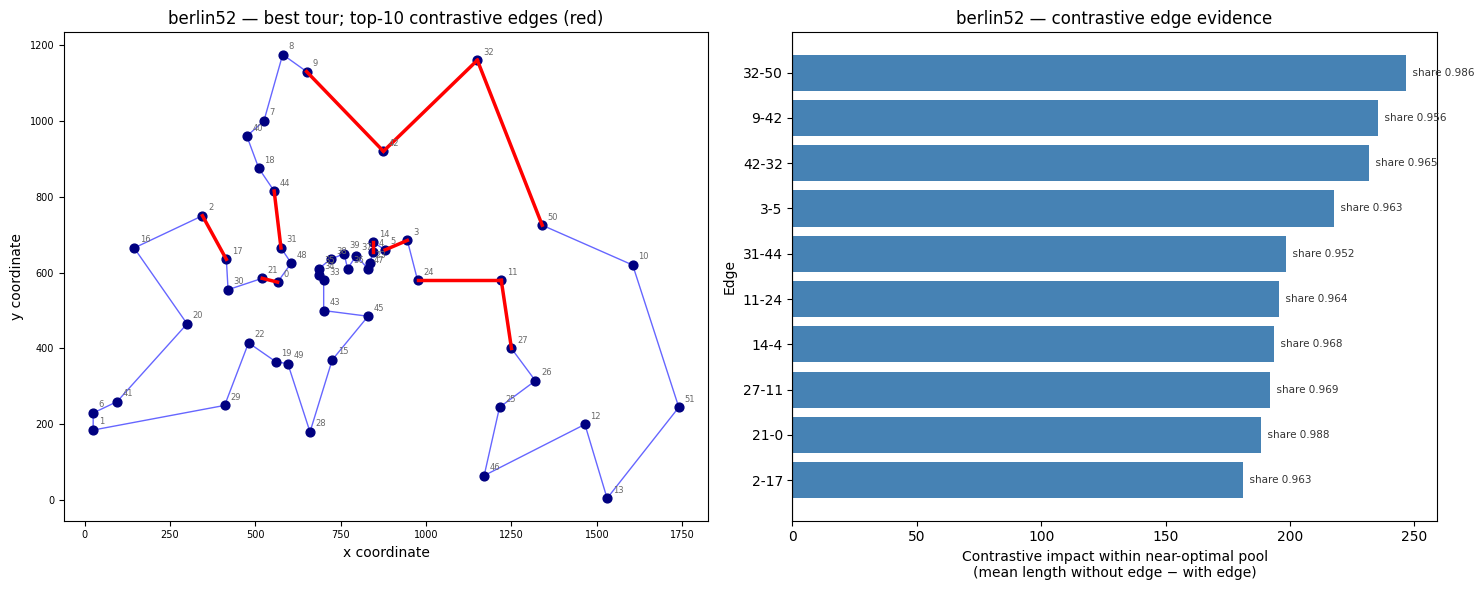


[2/5] Edge importance / frequency analysis...
CSV saved: thesis_outputs/tables/edge_importance_berlin52.csv
 edge  city_a  city_b  freq_all  freq_top  importance_ratio
43-45      43      45      3210       420             1.308
 0-48       0      48      3387       420             1.240
15-45      15      45      3431       420             1.224
36-39      36      39      3457       420             1.215
37-47      37      47      3484       420             1.206
22-29      22      29      3555       420             1.181
28-49      28      49      3589       420             1.170
12-46      12      46      3602       420             1.166
 3-24       3      24      3605       420             1.165
21-30      21      30      3608       420             1.164
Figure saved: thesis_outputs/figures/fig_berlin52_edge_importance.png


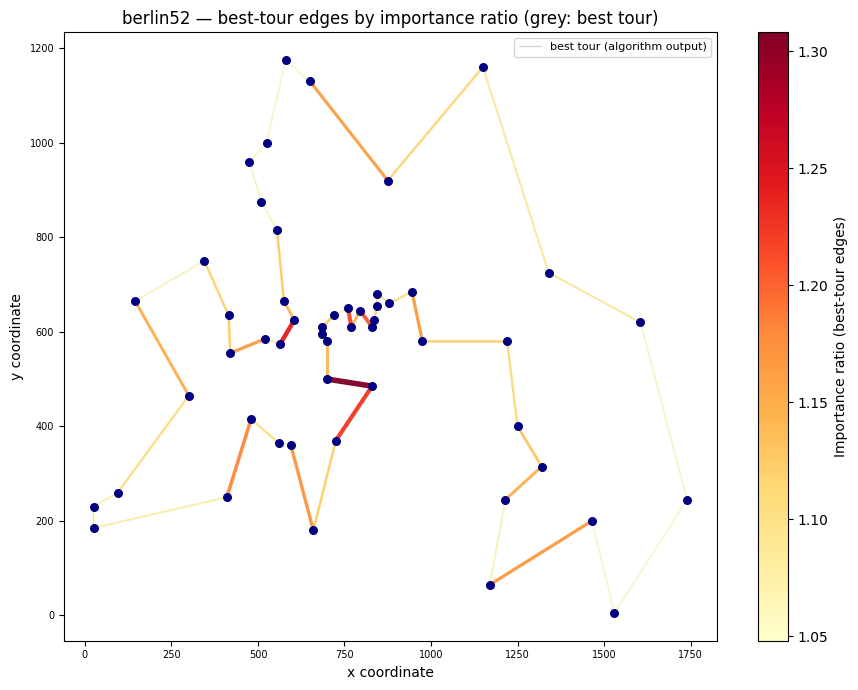


[3/5] Diverse near-optimal tours...
Near-optimal pool: 382 unique tours within 5% of best (7,542).
Pairwise Jaccard distances between selected tours:
             Global best   Alt 1   Alt 2   Alt 3   Alt 4   Alt 5
Global best       0.0000  0.4706  0.4478  0.4242  0.4242  0.4478
Alt 1             0.4706  0.0000  0.4706  0.5946  0.5556  0.5352
Alt 2             0.4478  0.4706  0.0000  0.5143  0.4928  0.4242
Alt 3             0.4242  0.5946  0.5143  0.0000  0.5143  0.4242
Alt 4             0.4242  0.5556  0.4928  0.5143  0.0000  0.5143
Alt 5             0.4478  0.5352  0.4242  0.4242  0.5143  0.0000
CSV saved: thesis_outputs/tables/diverse_tours_jaccard_berlin52.csv
Figure saved: thesis_outputs/figures/fig_berlin52_diverse_tours.png


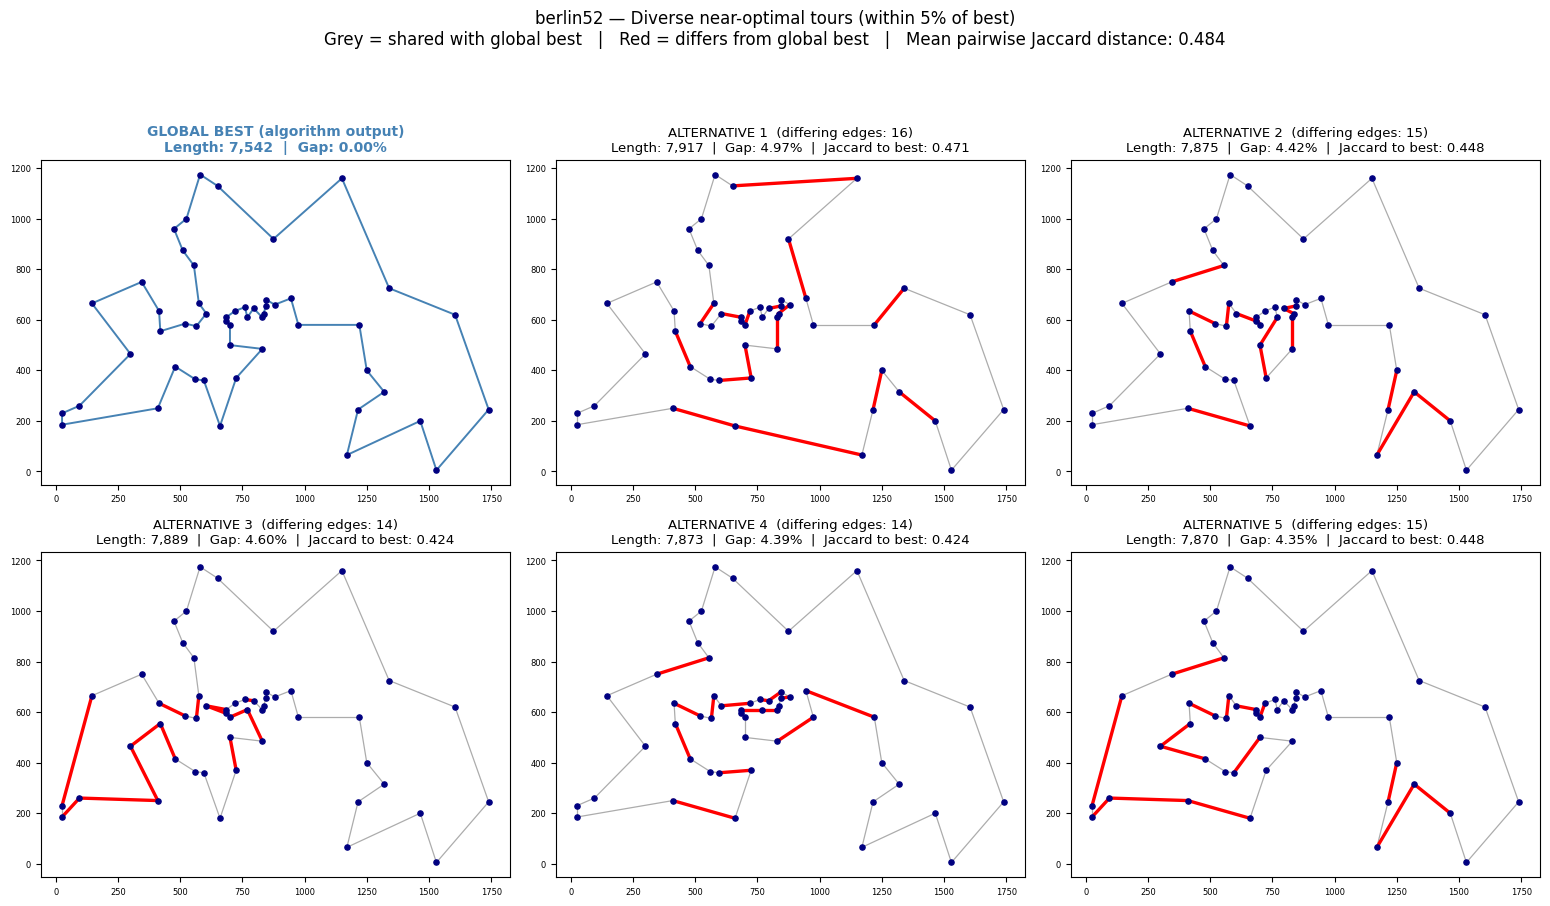


[4/5] Partial-solution (stable subpath) analysis...
Partial-solution analysis: 1 stable segment(s); 100.0% of best-tour edges appear in >= 80% of 3,427 near-optimal tours.
CSV saved: thesis_outputs/tables/stable_segments_berlin52.csv
 segment  n_edges                                                                                                                                               cities  segment_length  mean_share  min_share
       1       52 39-38-35-34-33-43-45-15-28-49-19-22-29-1-6-41-20-16-2-17-30-21-0-48-31-44-18-40-7-8-9-42-32-50-10-51-13-12-46-25-26-27-11-24-3-5-14-4-23-47-37-36-39            7542      0.9608     0.8696
CSV saved: thesis_outputs/tables/stable_sensitivity_berlin52.csv

Stable-subpath threshold sensitivity:
 threshold  stable_edges  coverage_%  n_segments  largest_segment
      0.70            52       100.0           1               52
      0.80            52       100.0           1               52
      0.90            48        92.3           3   

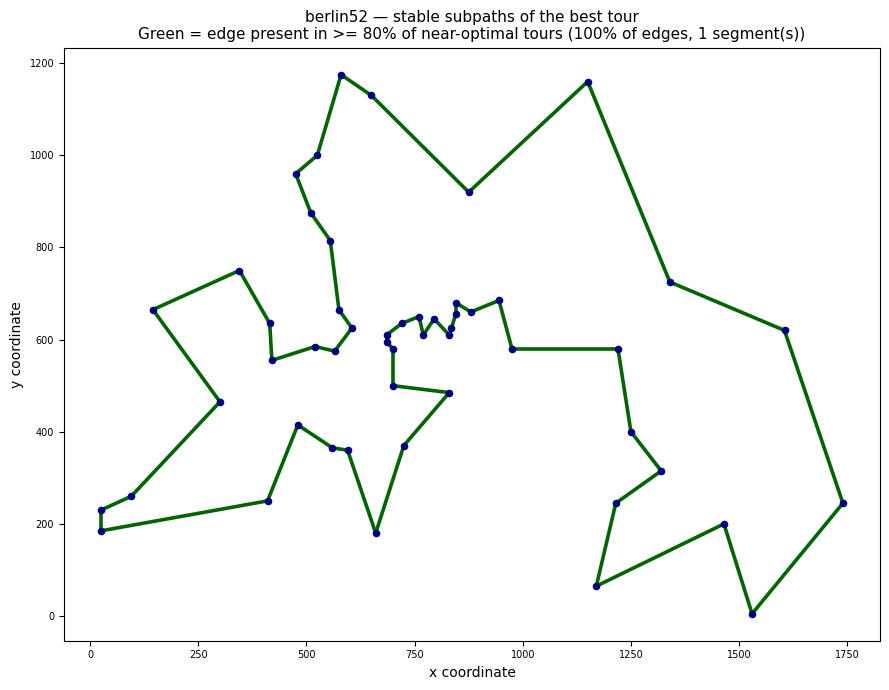

Figure saved: thesis_outputs/figures/fig_berlin52_stable_segments_compare.png


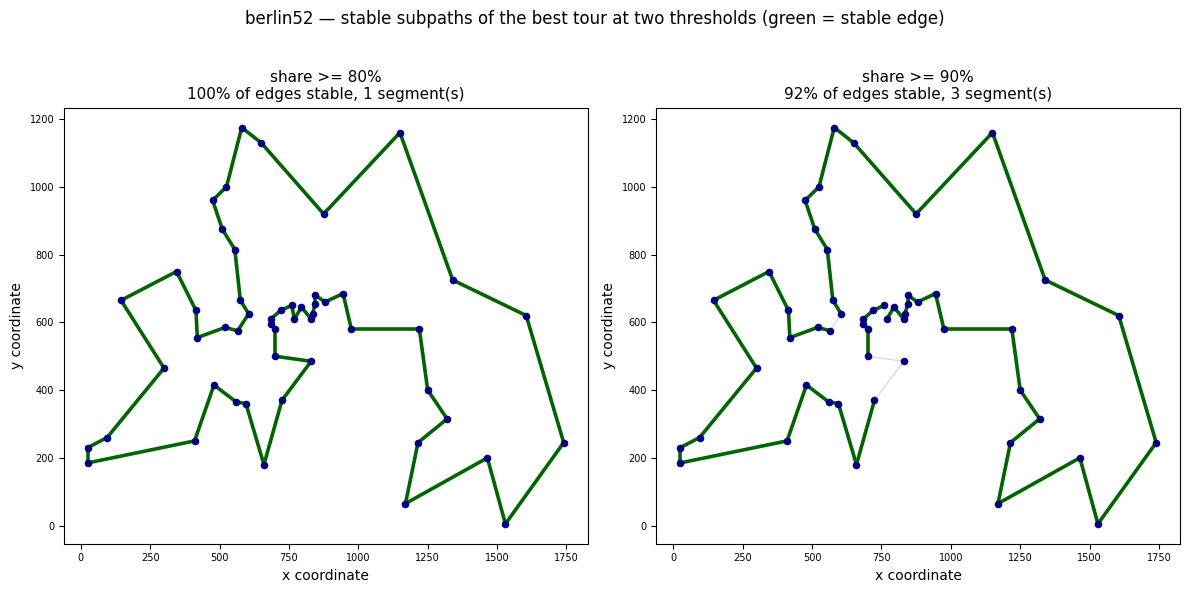


[5/5] Convergence and diversity analysis...
  Total improvement : 25,795 -> 7,542 (70.8% of initial)
  Convergence gen   : 5 (first generation at final best)
  Diversity <50%    : gen 5 (initial diversity 0.9809)
  Final diversity   : 0.1584
CSV saved: thesis_outputs/tables/convergence_diversity_berlin52.csv
Figure saved: thesis_outputs/figures/fig_berlin52_convergence_diversity.png


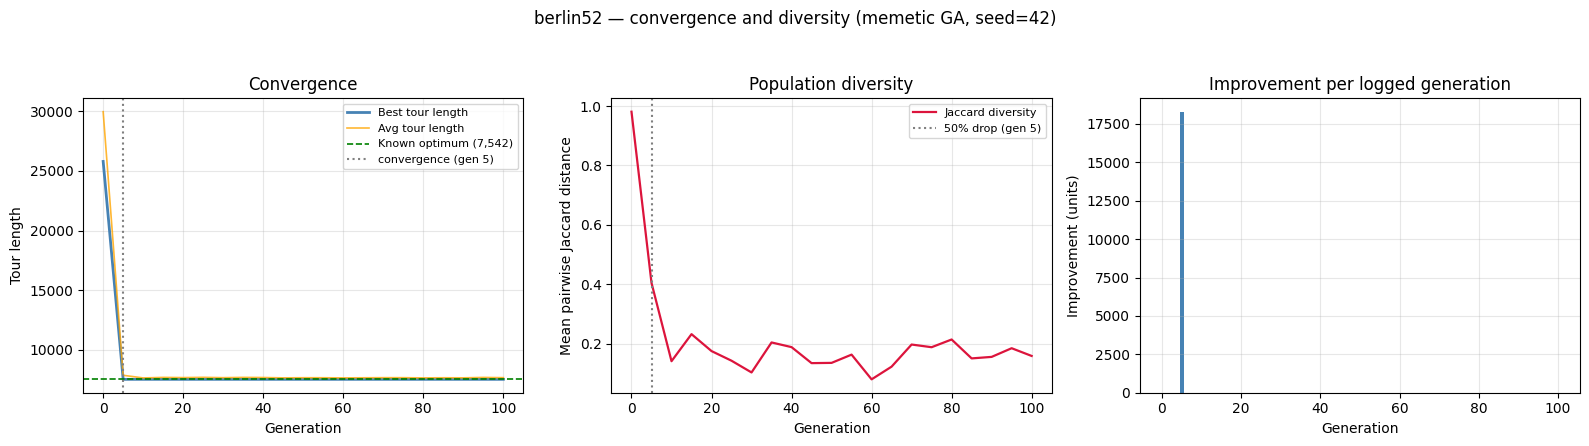

In [ ]:
inp = explanation_inputs['berlin52']
explanation_results['berlin52'] = run_explanations(
    'berlin52', inp['inst'], inp['best_tour'], inp['best_length'], inp['log'])


### 12.2 eil76


Explanations — eil76 (gap 0.00%)

[1/5] Contrastive edge evidence (near-optimal pool)...
Contrastive pool: 5,970 near-optimal tours (<= 5% above best logged length).
  3 best-tour edge(s) appear in ALL pool tours (fully stable; no contrast group).
CSV saved: thesis_outputs/tables/contrastive_nearopt_eil76.csv
 edge  city_a  city_b  edge_weight  mean_length_with  mean_length_without  contrastive_impact  share_with  n_without  reliable  stable
13-58      13      58           11             544.3                559.4                15.0      0.9977         14     False   False
14-56      14      56            4             544.3                558.4                14.1      0.9980         12     False   False
 2-43       2      43            3             544.3                558.3                13.9      0.9968         19     False   False
17-23      17      23           13             544.1                557.9                13.8      0.9802        118      True   False
24-49      24

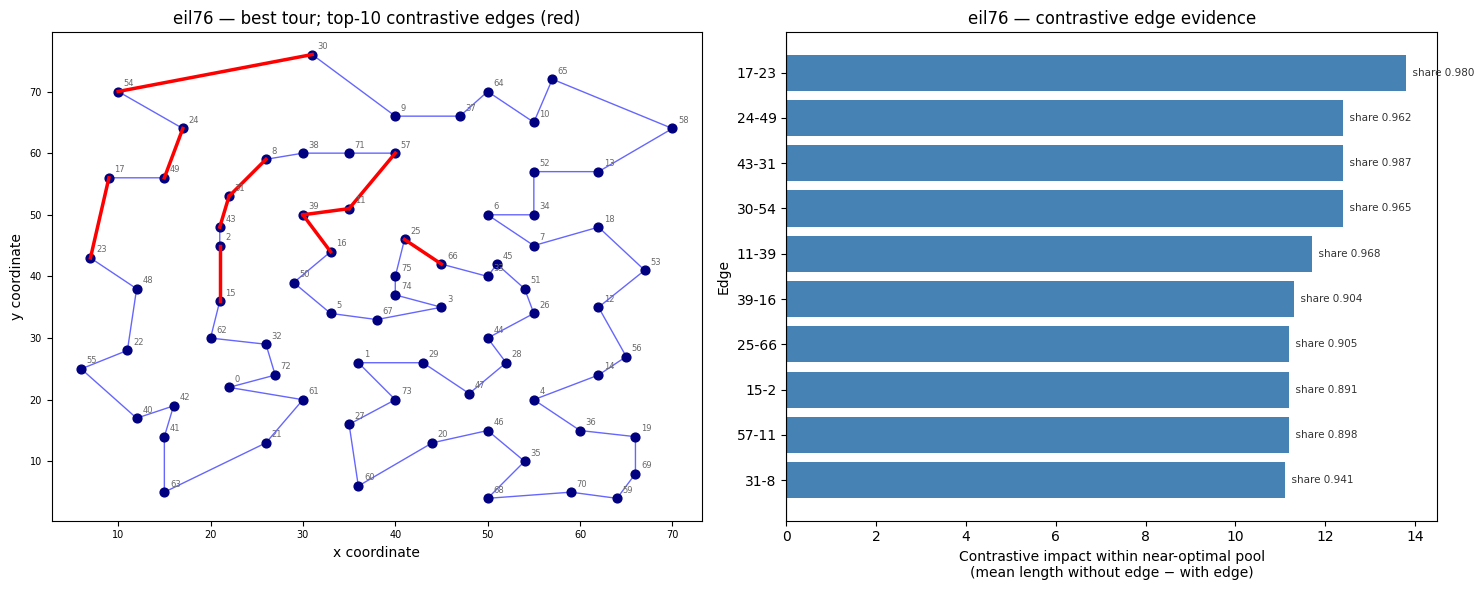


[2/5] Edge importance / frequency analysis...
CSV saved: thesis_outputs/tables/edge_importance_eil76.csv
 edge  city_a  city_b  freq_all  freq_top  importance_ratio
 3-67       3      67      4906       660             1.345
 3-74       3      74      4946       660             1.334
 0-32       0      32      2434       309             1.270
 6-52       6      52      2785       352             1.264
 1-29       1      29      5264       660             1.254
25-75      25      75      5525       660             1.195
 1-73       1      73      5531       660             1.193
33-66      33      66      5145       613             1.191
 2-15       2      15      5584       660             1.182
11-57      11      57      5592       660             1.180
Figure saved: thesis_outputs/figures/fig_eil76_edge_importance.png


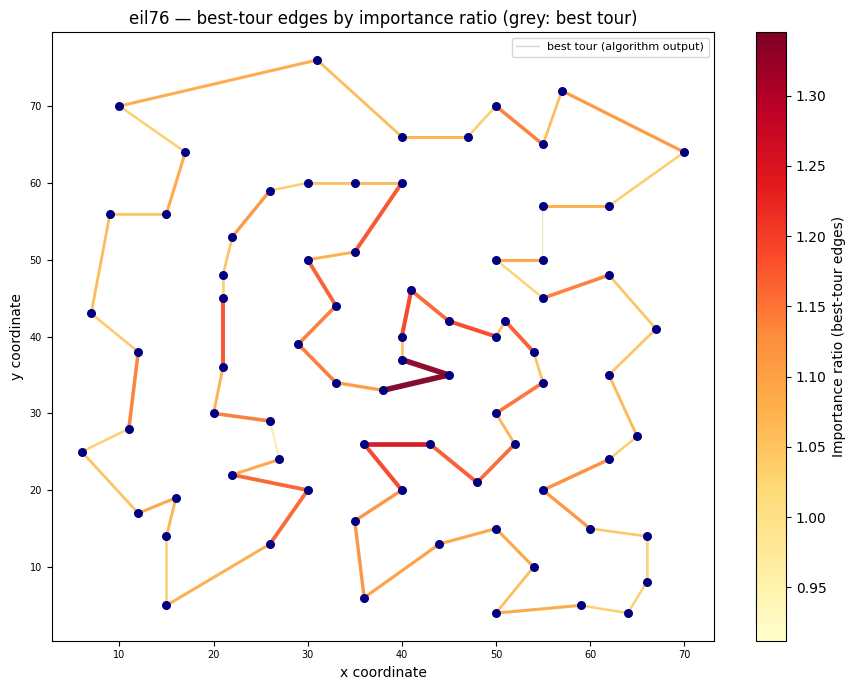


[3/5] Diverse near-optimal tours...
Near-optimal pool: 2,412 unique tours within 5% of best (538).
Pairwise Jaccard distances between selected tours:
             Global best   Alt 1   Alt 2   Alt 3   Alt 4   Alt 5
Global best       0.0000  0.5926  0.5660  0.5524  0.5385  0.5243
Alt 1             0.5926  0.0000  0.5926  0.5660  0.6549  0.5794
Alt 2             0.5660  0.5926  0.0000  0.6055  0.5794  0.5243
Alt 3             0.5524  0.5660  0.6055  0.0000  0.5660  0.5243
Alt 4             0.5385  0.6549  0.5794  0.5660  0.0000  0.6306
Alt 5             0.5243  0.5794  0.5243  0.5243  0.6306  0.0000
CSV saved: thesis_outputs/tables/diverse_tours_jaccard_eil76.csv
Figure saved: thesis_outputs/figures/fig_eil76_diverse_tours.png


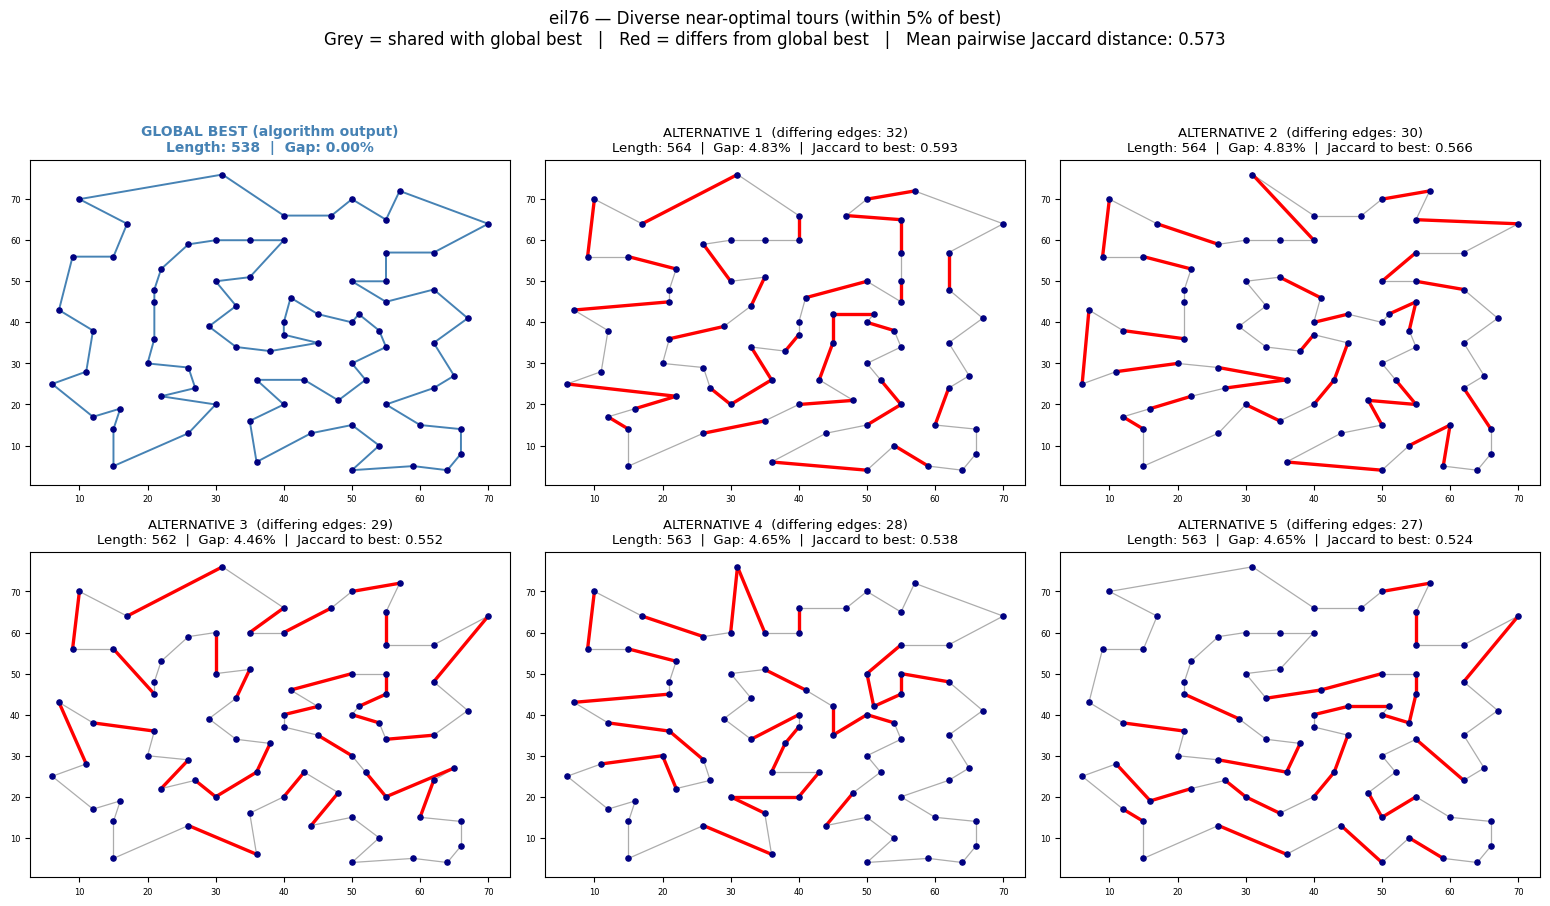


[4/5] Partial-solution (stable subpath) analysis...
Partial-solution analysis: 5 stable segment(s); 92.1% of best-tour edges appear in >= 80% of 5,970 near-optimal tours.
CSV saved: thesis_outputs/tables/stable_segments_eil76.csv
 segment  n_edges                                                                                       cities  segment_length  mean_share  min_share
       1       31 74-75-25-66-33-45-51-26-44-28-47-29-1-73-27-60-20-46-35-68-70-59-69-19-36-4-14-56-12-53-18-7             197      0.9401     0.8144
       2       22                          52-13-58-65-10-64-37-9-30-54-24-49-17-23-48-22-55-40-42-41-63-21-61             203      0.9660     0.8966
       3       15                                                 32-62-15-2-43-31-8-38-71-57-11-39-16-50-5-67              89      0.9466     0.8911
       4        1                                                                                         6-34               5      0.9541     0.9541
       5        1  

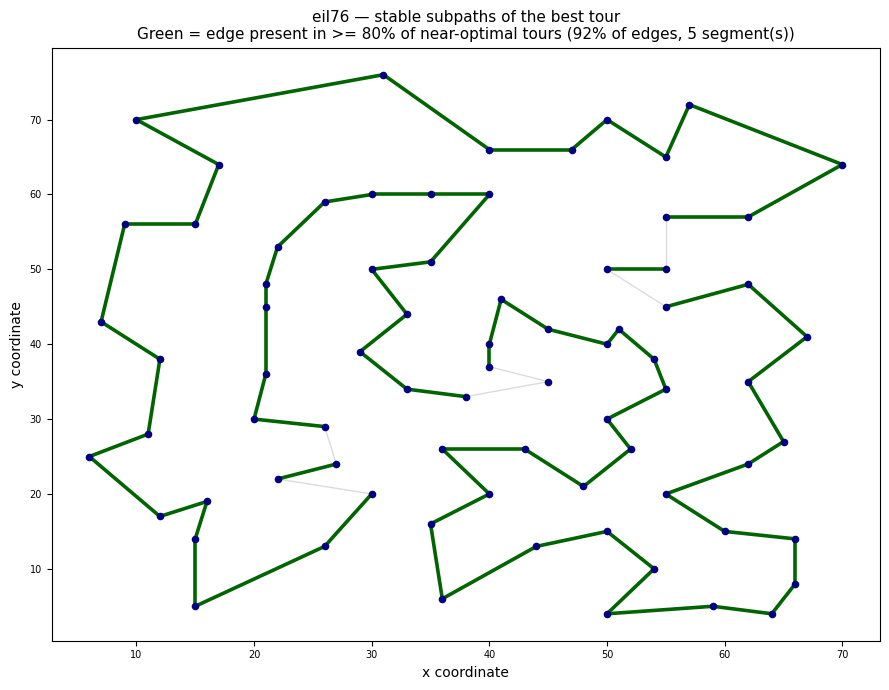

Figure saved: thesis_outputs/figures/fig_eil76_stable_segments_compare.png


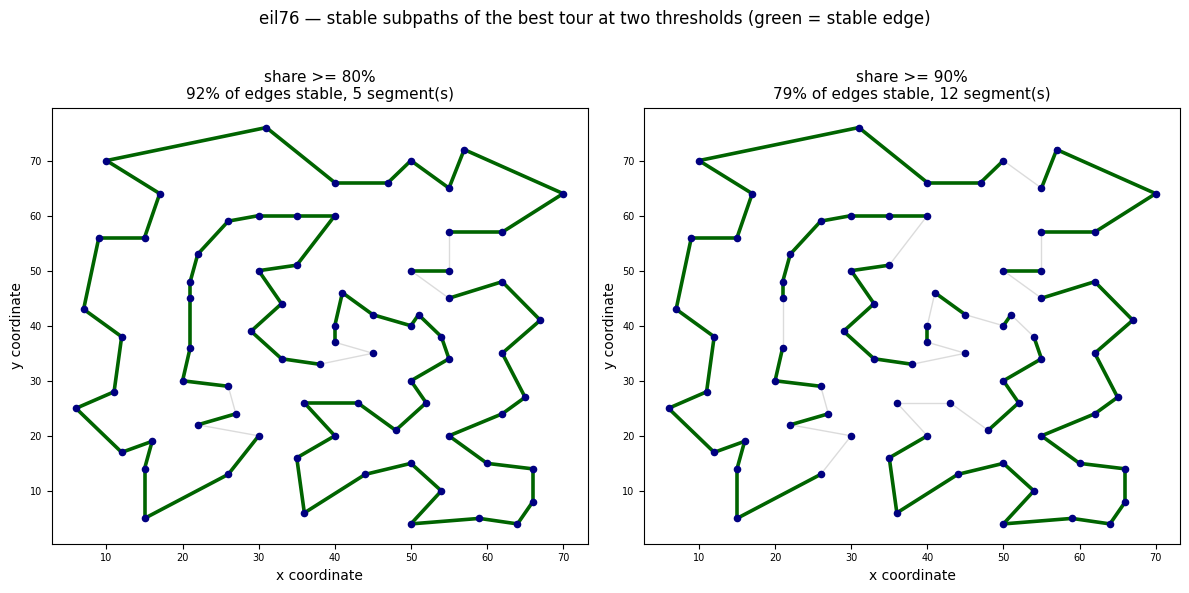


[5/5] Convergence and diversity analysis...
  Total improvement : 2,234 -> 538 (75.9% of initial)
  Convergence gen   : 15 (first generation at final best)
  Diversity <50%    : gen 10 (initial diversity 0.9852)
  Final diversity   : 0.2219
CSV saved: thesis_outputs/tables/convergence_diversity_eil76.csv
Figure saved: thesis_outputs/figures/fig_eil76_convergence_diversity.png


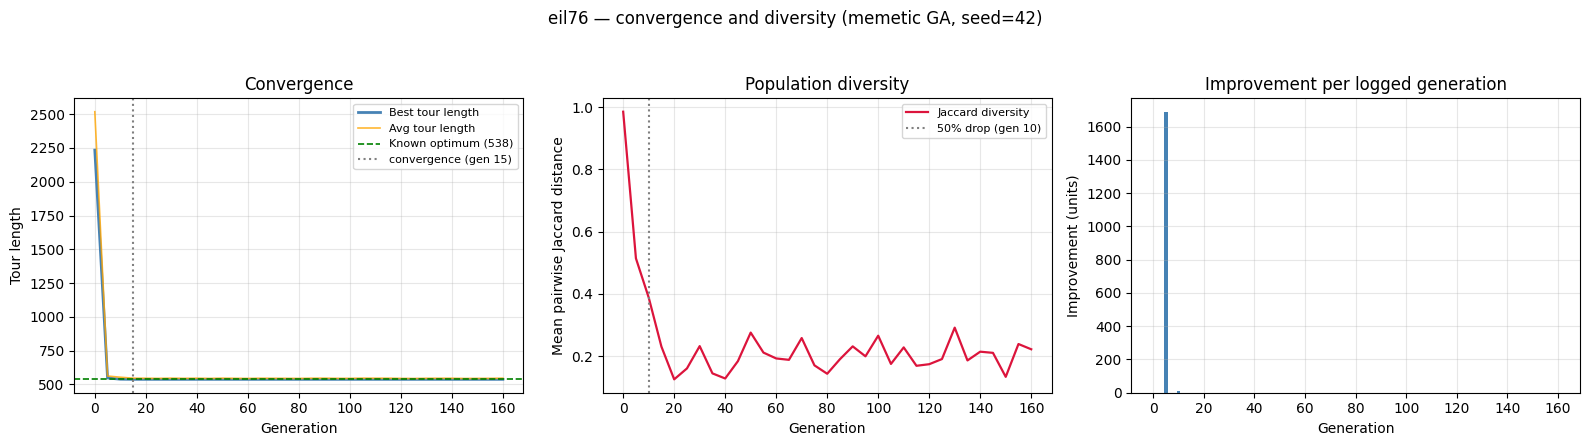

In [ ]:
if 'eil76' in explanation_inputs:
    inp = explanation_inputs['eil76']
    explanation_results['eil76'] = run_explanations(
        'eil76', inp['inst'], inp['best_tour'], inp['best_length'], inp['log'])
else:
    print('eil76 results not available — re-run Section 9 with FORCE_RERUN=True.')


### 12.3 rat99


Explanations — rat99 (gap 0.00%)

[1/5] Contrastive edge evidence (near-optimal pool)...
Contrastive pool: 7,143 near-optimal tours (<= 5% above best logged length).
  6 best-tour edge(s) appear in ALL pool tours (fully stable; no contrast group).
CSV saved: thesis_outputs/tables/contrastive_nearopt_rat99.csv
 edge  city_a  city_b  edge_weight  mean_length_with  mean_length_without  contrastive_impact  share_with  n_without  reliable  stable
 8-17       8      17           20            1226.4               1263.2                36.8      0.9993          5     False   False
31-30      31      30           11            1226.1               1259.5                33.3      0.9905         68      True   False
29-28      29      28           11            1226.0               1257.7                31.8      0.9845        111      True   False
  5-6       5       6           11            1226.4               1257.8                31.4      0.9972         20     False   False
45-46      45

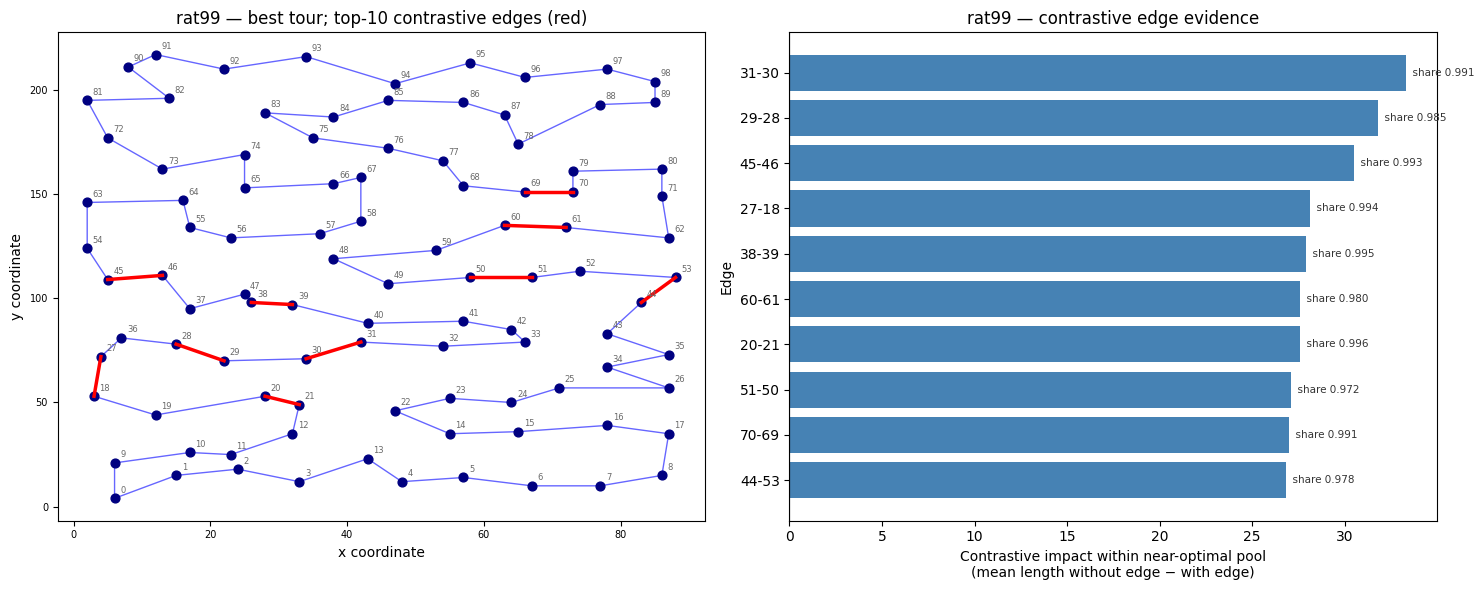


[2/5] Edge importance / frequency analysis...
CSV saved: thesis_outputs/tables/edge_importance_rat99.csv
 edge  city_a  city_b  freq_all  freq_top  importance_ratio
58-67      58      67      6295       840             1.334
48-59      48      59      6616       840             1.270
40-41      40      41      6699       840             1.254
65-74      65      74      6718       840             1.250
49-50      49      50      6777       840             1.239
31-32      31      32      6919       840             1.214
78-88      78      88      6944       840             1.210
75-83      75      83      6979       840             1.204
56-57      56      57      6989       840             1.202
73-74      73      74      6995       840             1.201
Figure saved: thesis_outputs/figures/fig_rat99_edge_importance.png


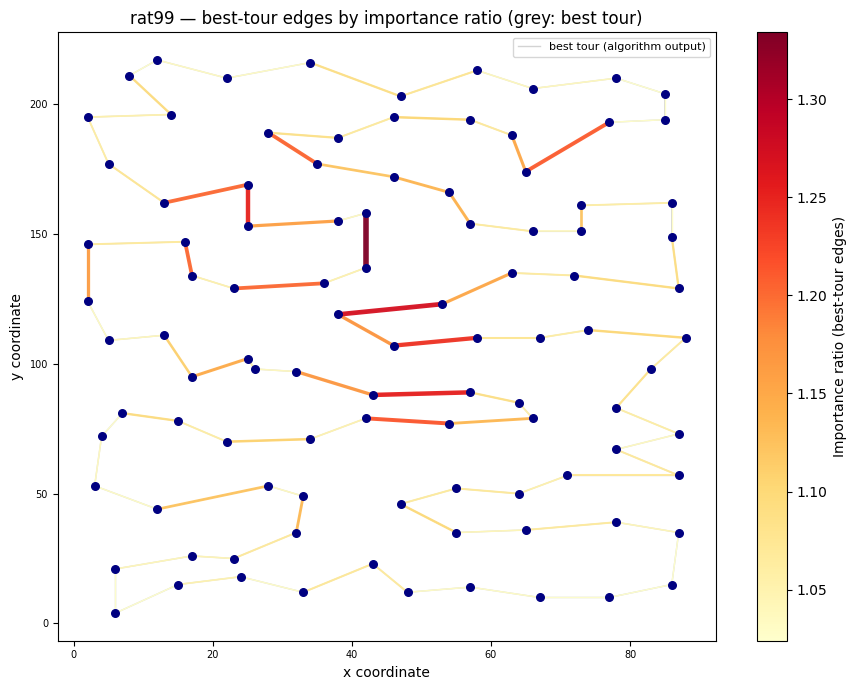


[3/5] Diverse near-optimal tours...
Near-optimal pool: 2,192 unique tours within 5% of best (1,211).
Pairwise Jaccard distances between selected tours:
             Global best   Alt 1   Alt 2   Alt 3   Alt 4   Alt 5
Global best       0.0000  0.4769  0.4409  0.4409  0.4160  0.4160
Alt 1             0.4769  0.0000  0.4531  0.4651  0.4286  0.4286
Alt 2             0.4409  0.4531  0.0000  0.4651  0.4885  0.5113
Alt 3             0.4409  0.4651  0.4651  0.0000  0.4409  0.4032
Alt 4             0.4160  0.4286  0.4885  0.4409  0.0000  0.4409
Alt 5             0.4160  0.4286  0.5113  0.4032  0.4409  0.0000
CSV saved: thesis_outputs/tables/diverse_tours_jaccard_rat99.csv
Figure saved: thesis_outputs/figures/fig_rat99_diverse_tours.png


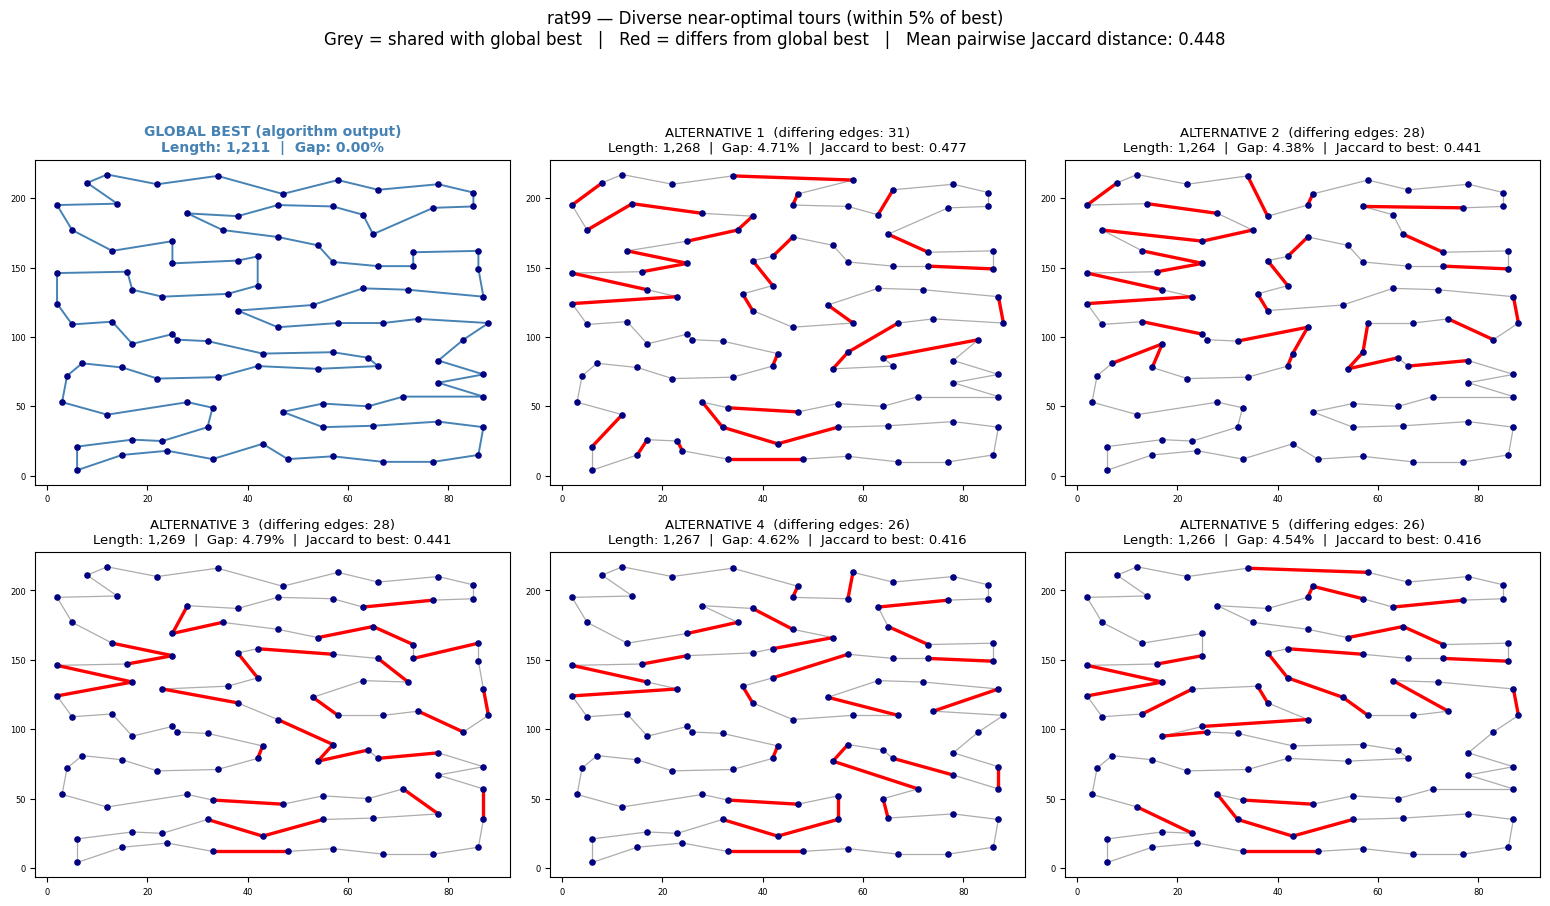


[4/5] Partial-solution (stable subpath) analysis...
Partial-solution analysis: 1 stable segment(s); 100.0% of best-tour edges appear in >= 80% of 7,143 near-optimal tours.
CSV saved: thesis_outputs/tables/stable_segments_rat99.csv
 segment  n_edges                                                                                                                                                                                                                                                                                            cities  segment_length  mean_share  min_share
       1       99 82-81-72-73-74-65-66-67-58-57-56-55-64-63-54-45-46-37-47-38-39-40-41-42-33-32-31-30-29-28-36-27-18-19-20-21-12-11-10-9-0-1-2-3-13-4-5-6-7-8-17-16-15-14-22-23-24-25-26-34-35-43-44-53-52-51-50-49-48-59-60-61-62-71-80-79-70-69-68-77-76-75-83-84-85-86-87-78-88-89-98-97-96-95-94-93-92-91-90-82            1211      0.9585     0.8111
CSV saved: thesis_outputs/tables/stable_sensitivity_rat99.csv

Stable-subp

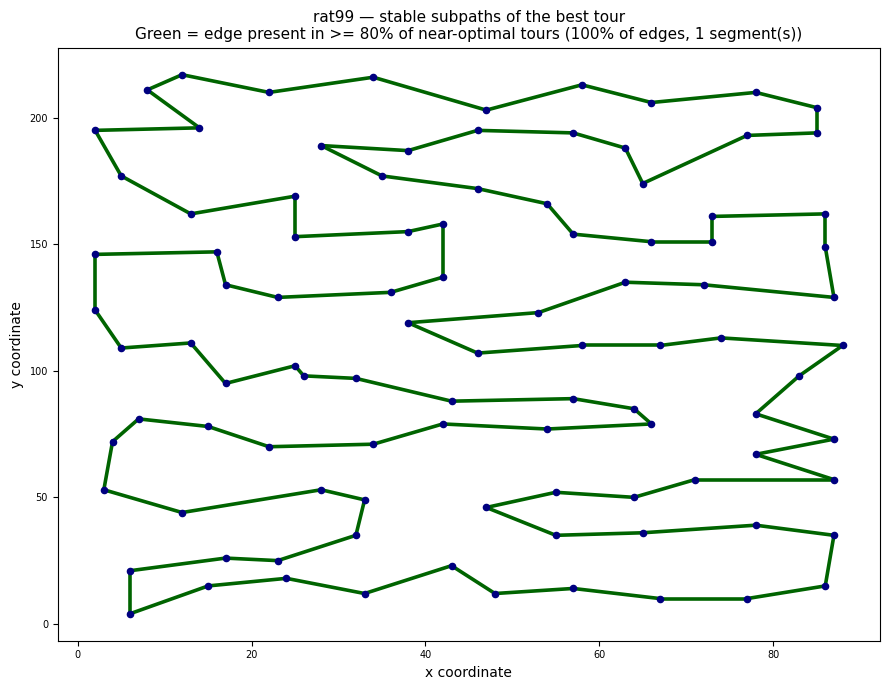

Figure saved: thesis_outputs/figures/fig_rat99_stable_segments_compare.png


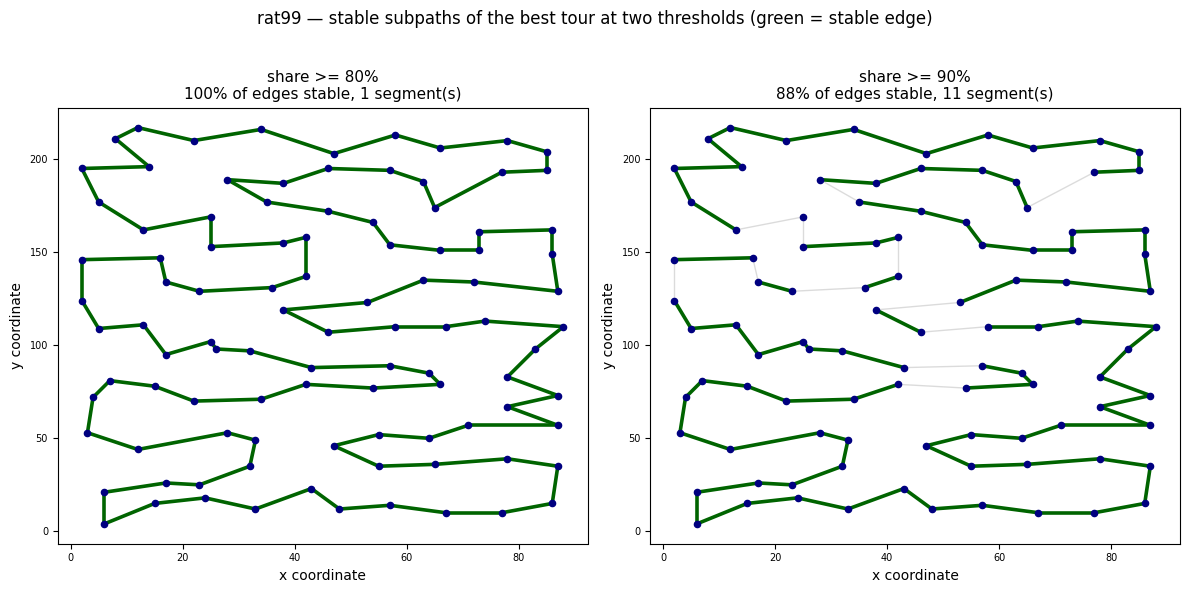


[5/5] Convergence and diversity analysis...
  Total improvement : 7,345 -> 1,211 (83.5% of initial)
  Convergence gen   : 10 (first generation at final best)
  Diversity <50%    : gen 5 (initial diversity 0.9904)
  Final diversity   : 0.0652
CSV saved: thesis_outputs/tables/convergence_diversity_rat99.csv
Figure saved: thesis_outputs/figures/fig_rat99_convergence_diversity.png


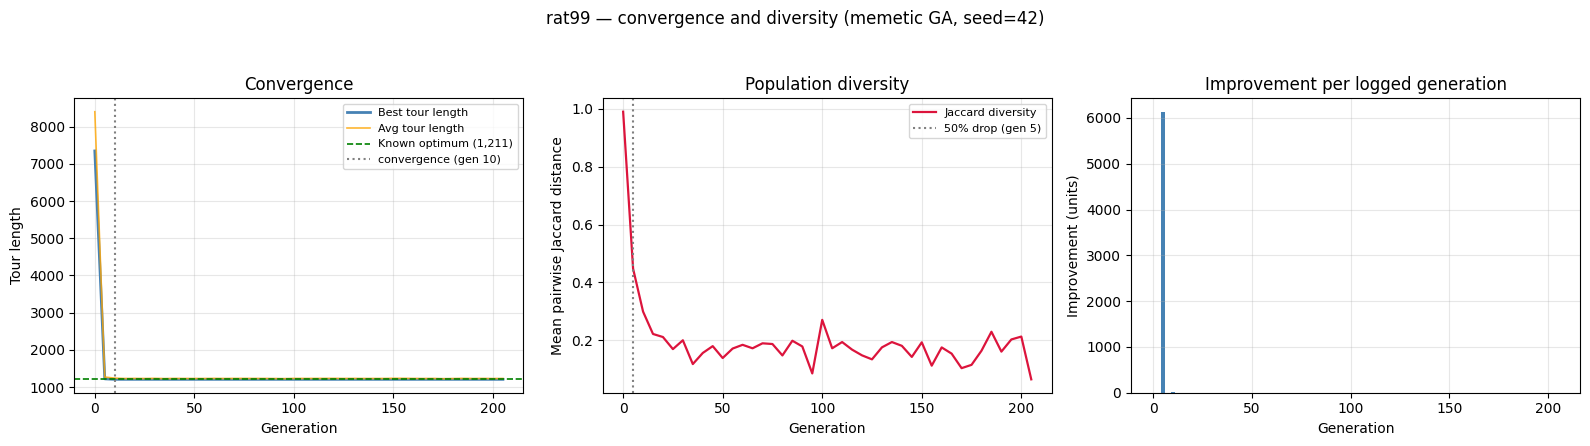

In [ ]:
if 'rat99' in explanation_inputs:
    inp = explanation_inputs['rat99']
    explanation_results['rat99'] = run_explanations(
        'rat99', inp['inst'], inp['best_tour'], inp['best_length'], inp['log'])
else:
    print('rat99 results not available — re-run Section 9 with FORCE_RERUN=True.')


### 12.4 rat575 and pr1002 (RUN_HEAVY)

*The diverse-tour selection on pr1002 iterates over tens of thousands of pool tours — expect several minutes per instance. Edge-importance ratios use `min_obs` filtering (rare edges produce the ratio cap of 10 by construction).*


Explanations — rat575 (gap 0.06%)

[1/5] Contrastive edge evidence (near-optimal pool)...
Contrastive pool: 29,963 near-optimal tours (<= 5% above best logged length).
  11 best-tour edge(s) appear in ALL pool tours (fully stable; no contrast group).
CSV saved: thesis_outputs/tables/contrastive_nearopt_rat575.csv
   edge  city_a  city_b  edge_weight  mean_length_with  mean_length_without  contrastive_impact  share_with  n_without  reliable  stable
548-549     548     549            9            6805.7               6984.6               178.9      0.9984         47      True   False
452-475     452     475            7            6805.9               6980.4               174.6      0.9993         21     False   False
  69-46      69      46           16            6805.5               6979.6               174.1      0.9970         90      True   False
558-557     558     557           20            6805.1               6967.8               162.7      0.9947        158      True   False

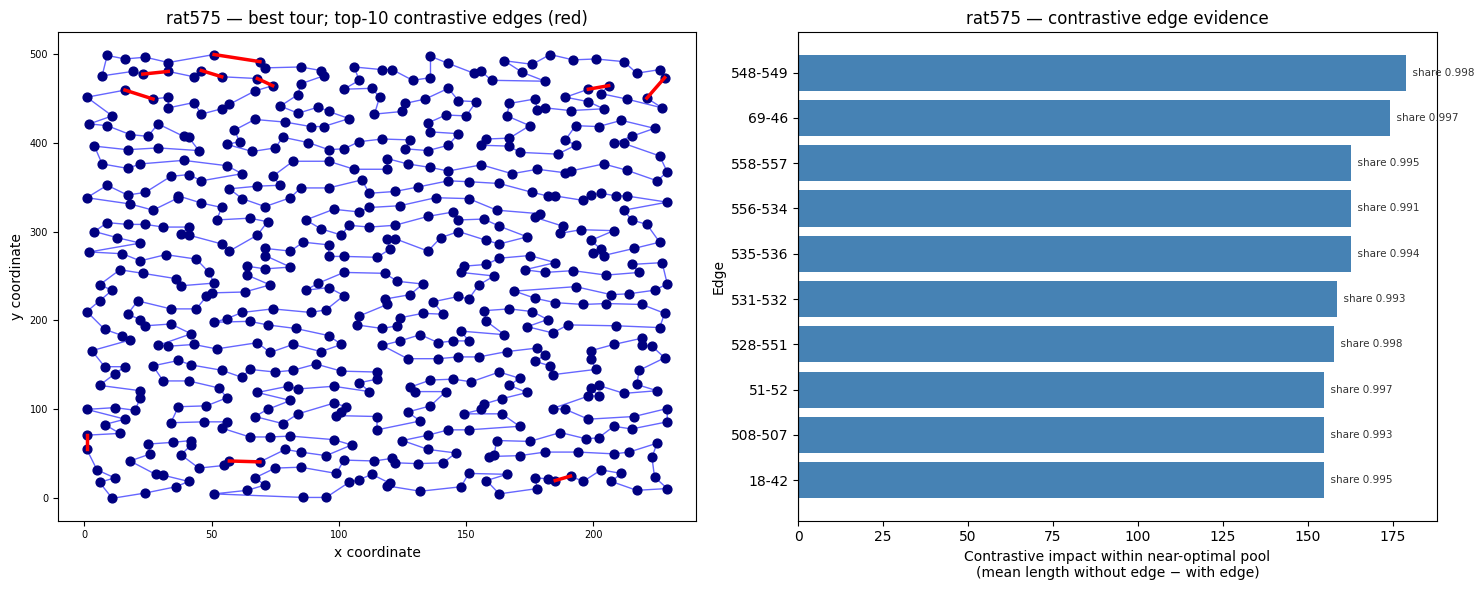


[2/5] Edge importance / frequency analysis...
  edge_frequency_analysis: 83910 edge(s) with freq_all < 9000 excluded (unreliable ratios; cap = 10 by construction).
CSV saved: thesis_outputs/tables/edge_importance_rat575.csv
   edge  city_a  city_b  freq_all  freq_top  importance_ratio
269-272     269     272     21179      3020             1.426
106-108     106     108     21464      3020             1.407
 90-114      90     114     21523      3020             1.403
290-292     290     292     21532      3020             1.403
113-137     113     137     21559      3020             1.401
133-134     133     134     21590      3020             1.399
 84-109      84     109     21553      3008             1.396
135-157     135     157     21656      3020             1.395
136-158     136     158     21656      3020             1.395
111-113     111     113     21716      3020             1.391
Figure saved: thesis_outputs/figures/fig_rat575_edge_importance.png


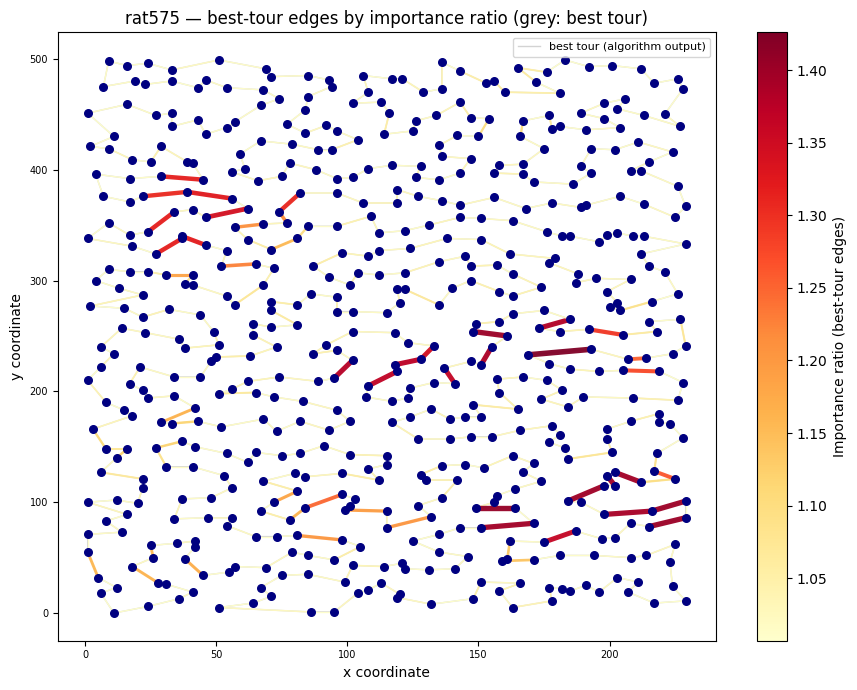


[3/5] Diverse near-optimal tours...
Near-optimal pool: 10,051 unique tours within 5% of best (6,777).
Pairwise Jaccard distances between selected tours:
             Global best   Alt 1   Alt 2   Alt 3   Alt 4   Alt 5
Global best       0.0000  0.4768  0.4480  0.4459  0.4522  0.4354
Alt 1             0.4768  0.0000  0.4543  0.4868  0.4332  0.4396
Alt 2             0.4480  0.4543  0.0000  0.4748  0.4564  0.4908
Alt 3             0.4459  0.4868  0.4748  0.0000  0.4928  0.4268
Alt 4             0.4522  0.4332  0.4564  0.4928  0.0000  0.4459
Alt 5             0.4354  0.4396  0.4908  0.4268  0.4459  0.0000
CSV saved: thesis_outputs/tables/diverse_tours_jaccard_rat575.csv
Figure saved: thesis_outputs/figures/fig_rat575_diverse_tours.png


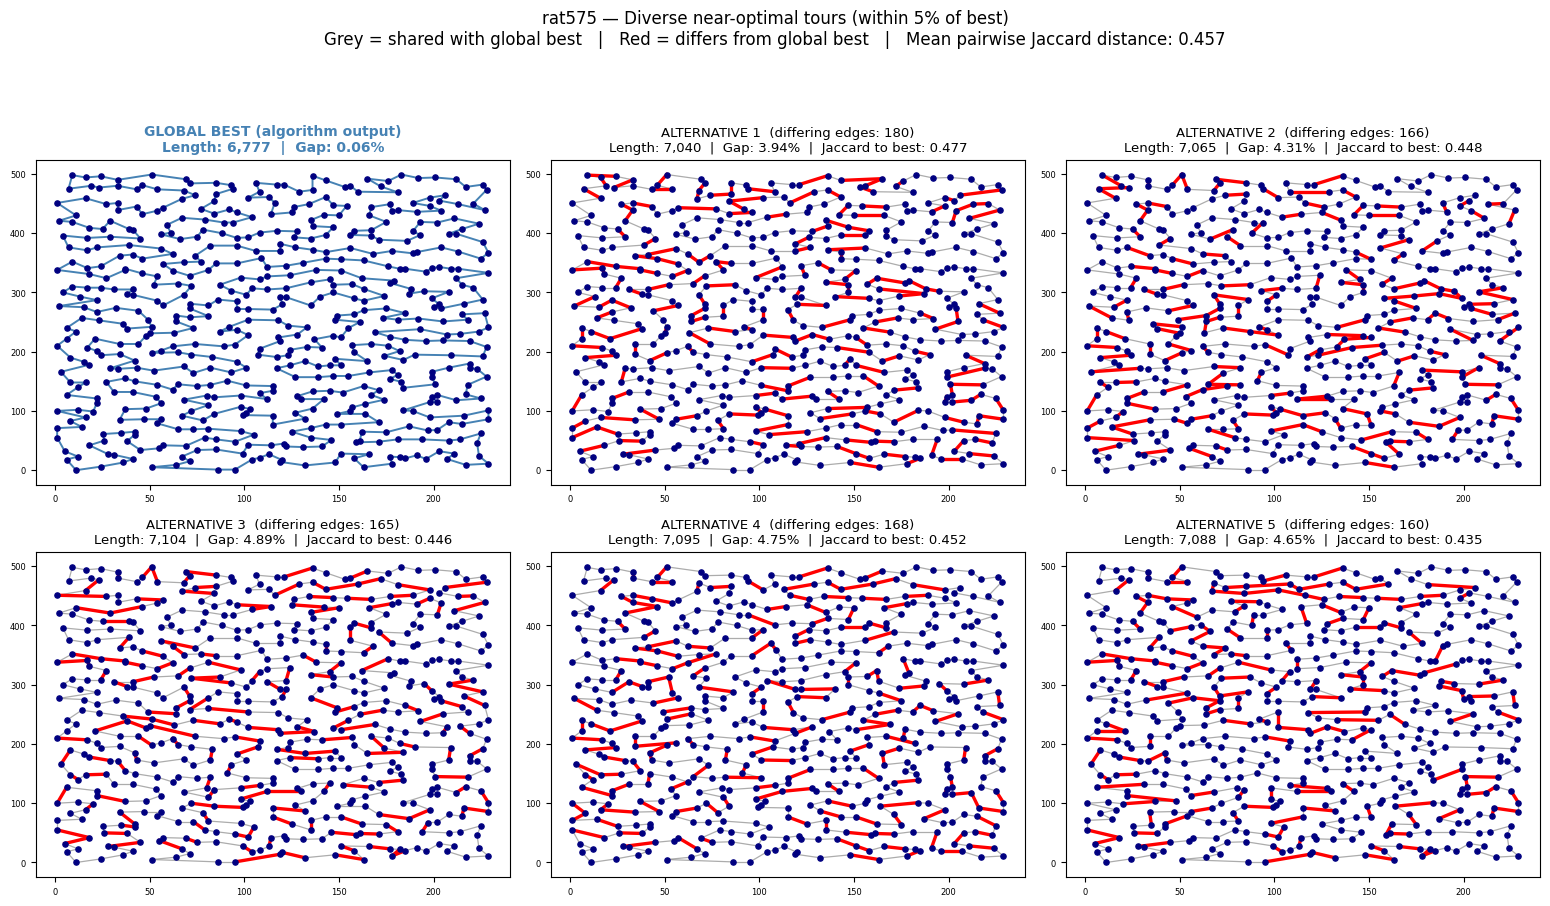


[4/5] Partial-solution (stable subpath) analysis...
Partial-solution analysis: 26 stable segment(s); 95.0% of best-tour edges appear in >= 80% of 29,963 near-optimal tours.
CSV saved: thesis_outputs/tables/stable_segments_rat575.csv
 segment  n_edges                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                  cities  segment_length  mean_share  min_share
       1      149 422-423-424-425-448-426-427-428-429-430-431-432-433-434-435-413-436-459-458-457-481-482-504

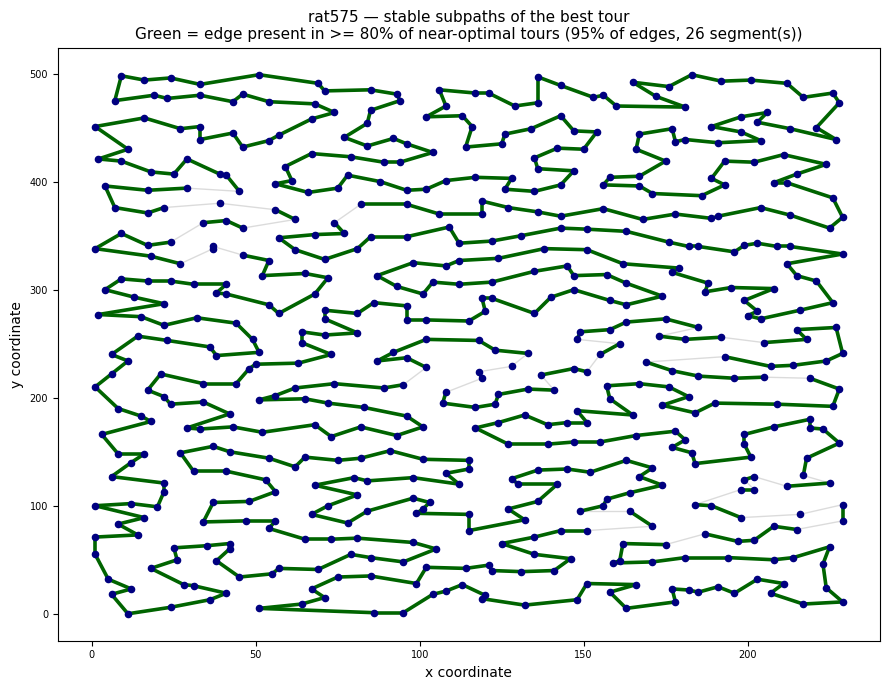

Figure saved: thesis_outputs/figures/fig_rat575_stable_segments_compare.png


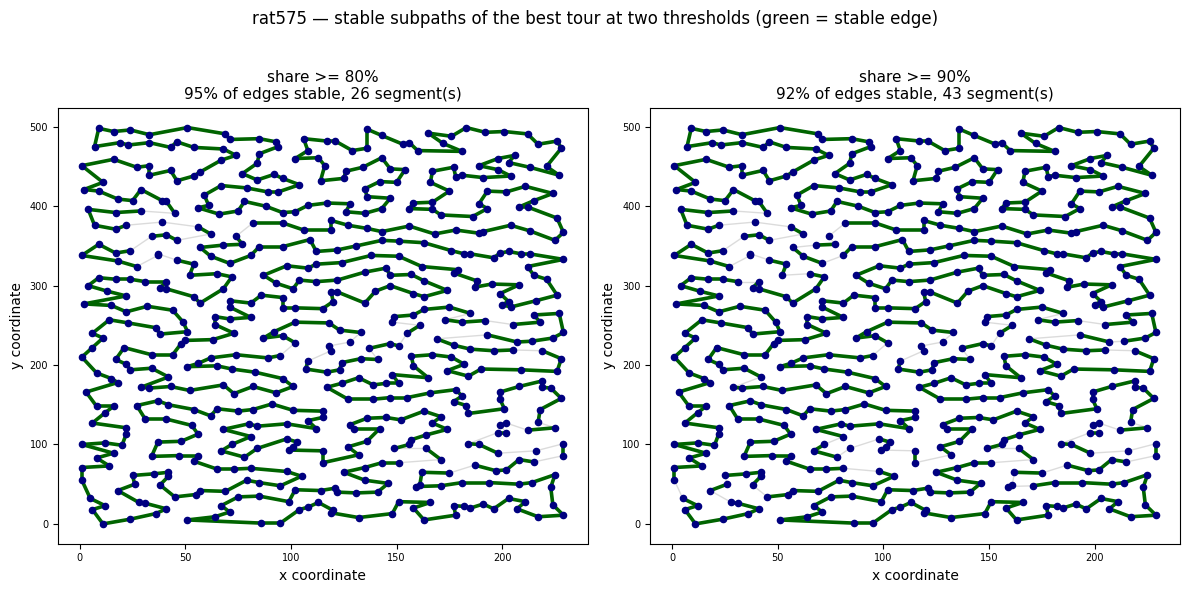


[5/5] Convergence and diversity analysis...
  Total improvement : 107,429 -> 6,777 (93.7% of initial)
  Convergence gen   : 200 (first generation at final best)
  Diversity <50%    : gen 5 (initial diversity 0.9983)
  Final diversity   : 0.0526
CSV saved: thesis_outputs/tables/convergence_diversity_rat575.csv
Figure saved: thesis_outputs/figures/fig_rat575_convergence_diversity.png


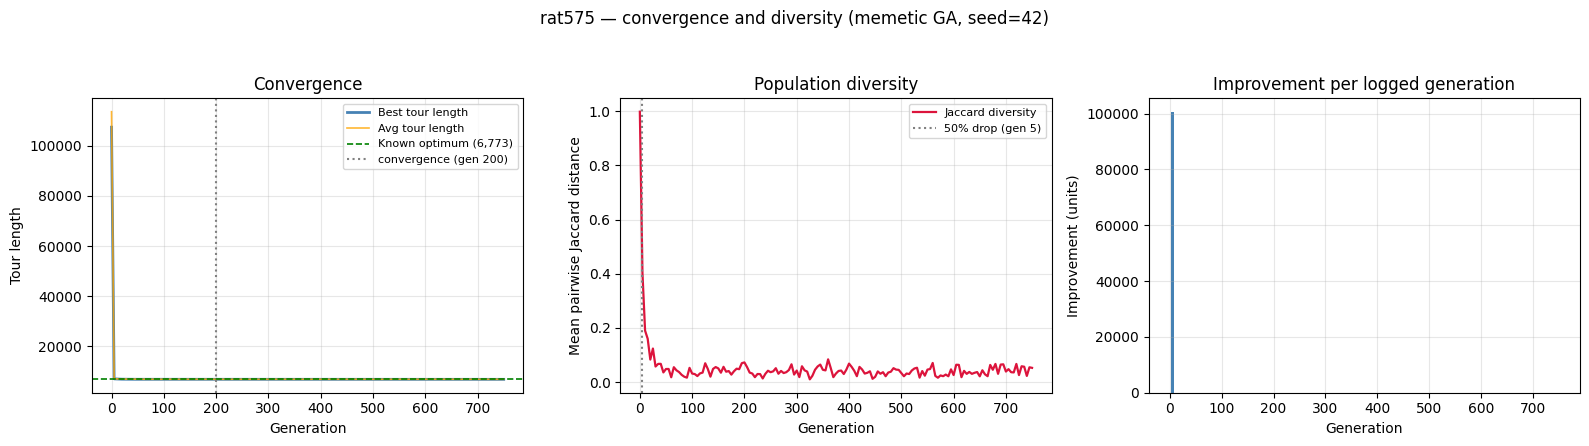


Explanations — pr1002 (gap 0.42%)

[1/5] Contrastive edge evidence (near-optimal pool)...
Contrastive pool: 37,358 near-optimal tours (<= 5% above best logged length).
  23 best-tour edge(s) appear in ALL pool tours (fully stable; no contrast group).
CSV saved: thesis_outputs/tables/contrastive_nearopt_pr1002.csv
   edge  city_a  city_b  edge_weight  mean_length_with  mean_length_without  contrastive_impact  share_with  n_without  reliable  stable
332-333     332     333          150          262049.3             270730.2              8681.0      0.9999          4     False   False
862-860     862     860          224          262028.6             270454.9              8426.3      0.9974         96      True   False
    7-8       7       8          180          262048.9             270263.2              8214.3      0.9998          6     False   False
839-838     839     838          304          262031.2             269842.3              7811.1      0.9976         91      True   False

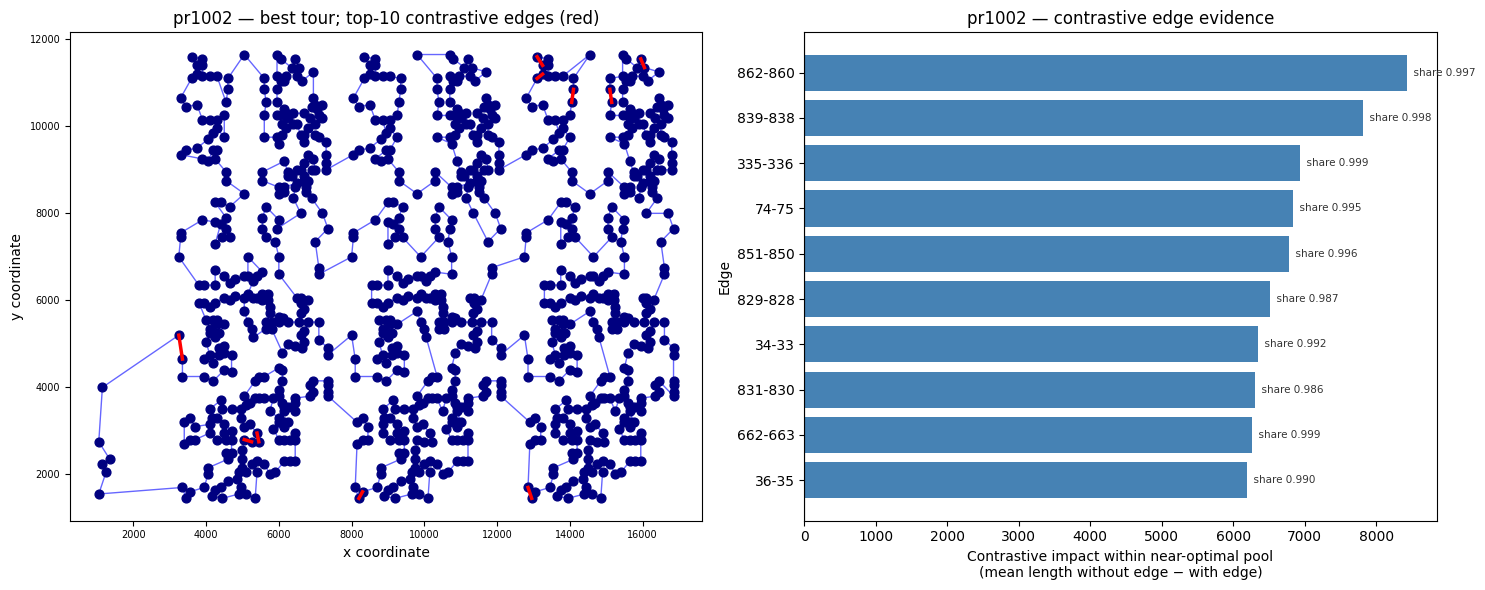


[2/5] Edge importance / frequency analysis...
  edge_frequency_analysis: 173296 edge(s) with freq_all < 9000 excluded (unreliable ratios; cap = 10 by construction).
CSV saved: thesis_outputs/tables/edge_importance_pr1002.csv
   edge  city_a  city_b  freq_all  freq_top  importance_ratio
674-676     674     676     23376      3980             1.703
668-671     668     671     23400      3980             1.701
670-673     670     673     23411      3980             1.700
110-305     110     305     24780      3980             1.606
257-269     257     269     26229      3980             1.517
672-677     672     677     26333      3980             1.511
276-279     276     279     26483      3980             1.503
119-278     119     278     26522      3980             1.501
275-466     275     466     26519      3980             1.501
276-280     276     280     26553      3980             1.499
Figure saved: thesis_outputs/figures/fig_pr1002_edge_importance.png


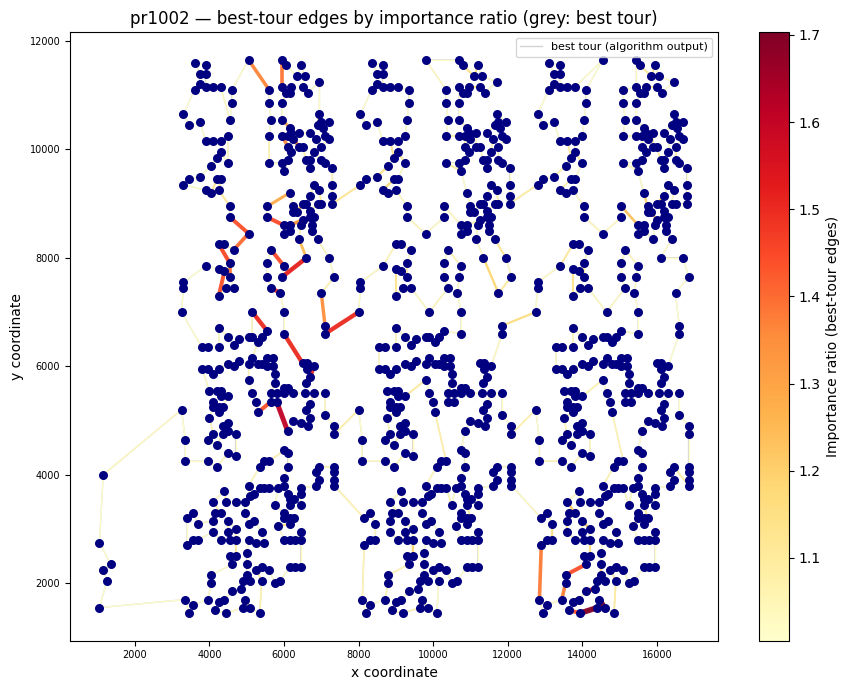


[3/5] Diverse near-optimal tours...
Near-optimal pool: 17,749 unique tours within 5% of best (260,141).
Pairwise Jaccard distances between selected tours:
             Global best   Alt 1   Alt 2   Alt 3   Alt 4   Alt 5
Global best       0.0000  0.4644  0.4417  0.4393  0.4537  0.4270
Alt 1             0.4644  0.0000  0.4405  0.4596  0.4270  0.4233
Alt 2             0.4417  0.4405  0.0000  0.4807  0.4270  0.4356
Alt 3             0.4393  0.4596  0.4807  0.0000  0.4489  0.4258
Alt 4             0.4537  0.4270  0.4270  0.4489  0.0000  0.4561
Alt 5             0.4270  0.4233  0.4356  0.4258  0.4561  0.0000
CSV saved: thesis_outputs/tables/diverse_tours_jaccard_pr1002.csv
Figure saved: thesis_outputs/figures/fig_pr1002_diverse_tours.png


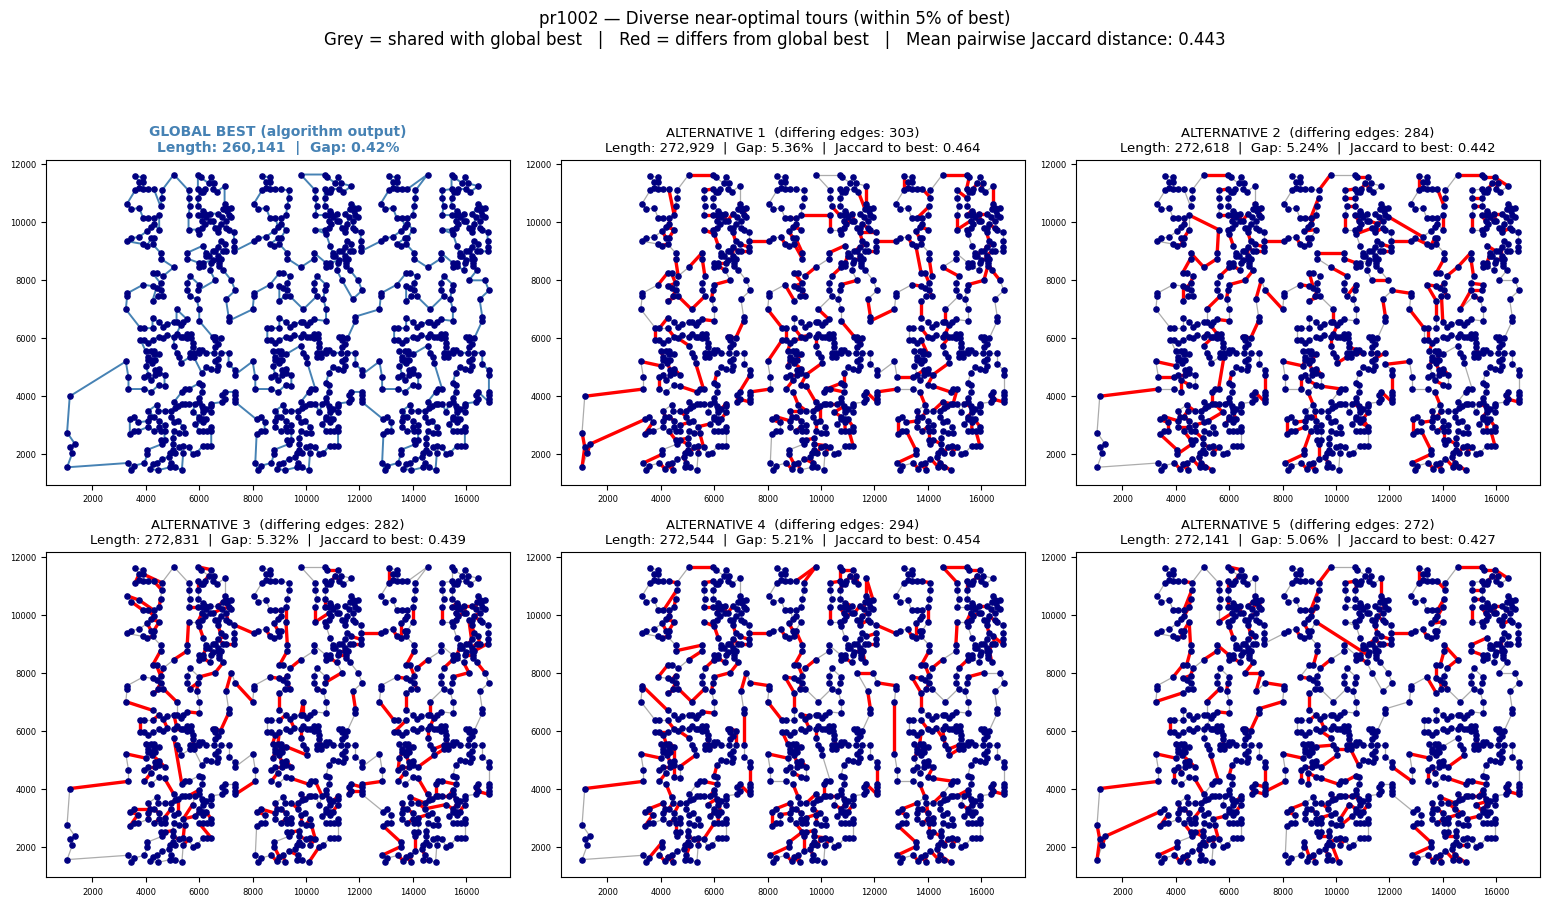


[4/5] Partial-solution (stable subpath) analysis...
Partial-solution analysis: 32 stable segment(s); 96.2% of best-tour edges appear in >= 80% of 37,358 near-optimal tours.
CSV saved: thesis_outputs/tables/stable_segments_pr1002.csv
 segment  n_edges                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                             

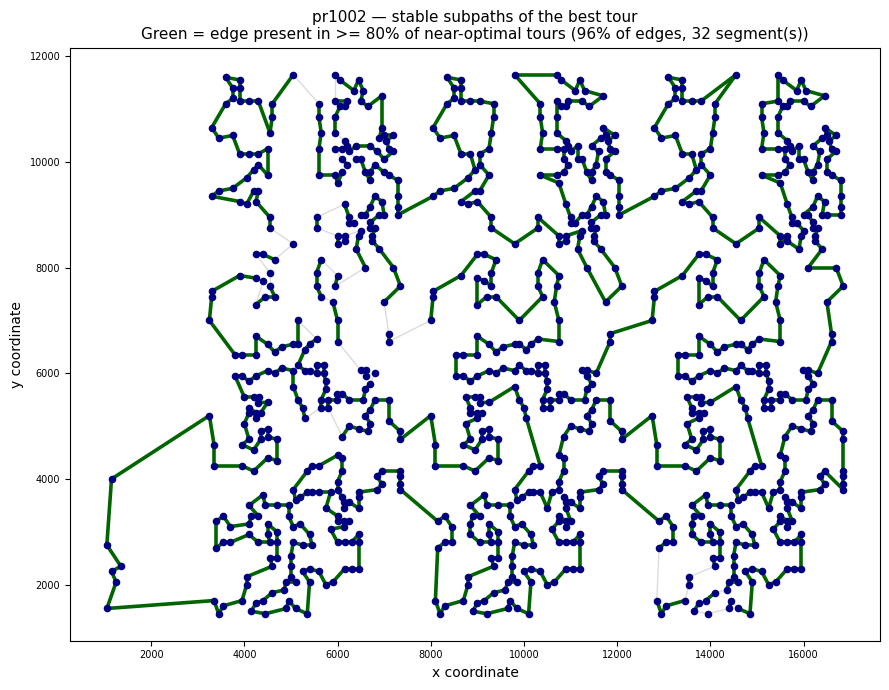

Figure saved: thesis_outputs/figures/fig_pr1002_stable_segments_compare.png


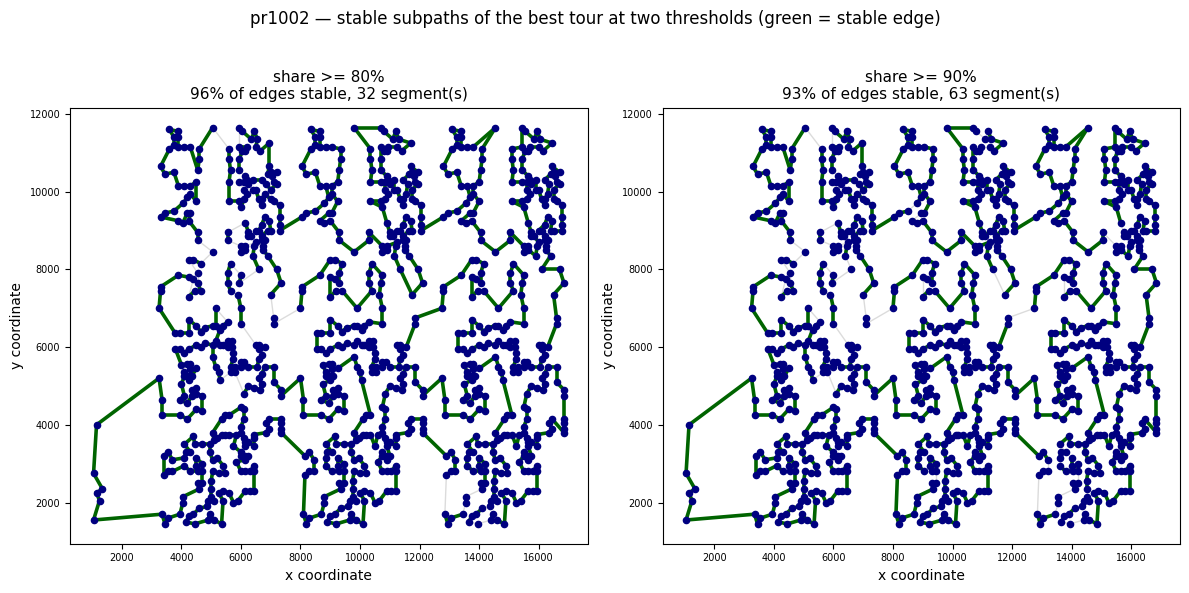


[5/5] Convergence and diversity analysis...
  Total improvement : 6,223,266 -> 260,141 (95.8% of initial)
  Convergence gen   : 395 (first generation at final best)
  Diversity <50%    : gen 5 (initial diversity 0.9989)
  Final diversity   : 0.0258
CSV saved: thesis_outputs/tables/convergence_diversity_pr1002.csv
Figure saved: thesis_outputs/figures/fig_pr1002_convergence_diversity.png


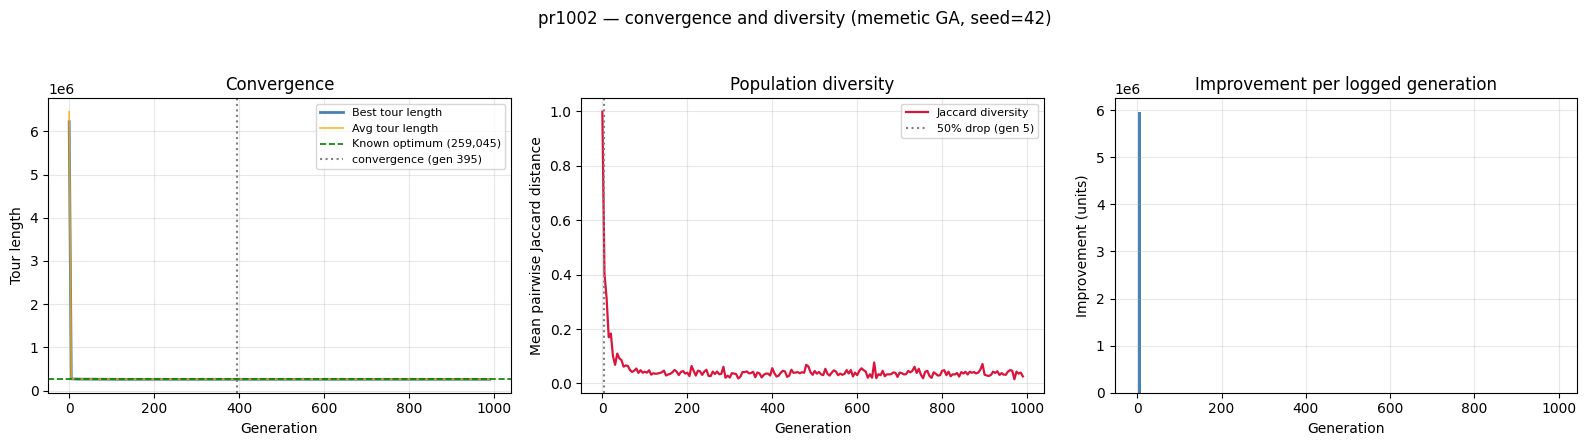

In [ ]:
for name in ['rat575', 'pr1002']:
    if name in heavy_vars:
        hv = heavy_vars[name]
        explanation_results[name] = run_explanations(
            name, hv['inst'], hv['best_tour'], hv['best_length'], hv['log'],
            n_select=6, min_obs=9000 if not QUICK_TEST else None)
    else:
        print(f'{name}: results not available (RUN_HEAVY=False and no saved log).')


## 13. Cross-Instance Explanation Summary

In [ ]:
# Cross-instance summary. Falls back to the saved per-instance summary JSONs,
# so it also works after a session restart (only Sections 0-1 need to be run).
EXPLANATION_INSTANCES = ['berlin52', 'eil76', 'rat99', 'rat575', 'pr1002']
if 'explanation_results' not in dir():
    explanation_results = {}
rows_x = []
for name in EXPLANATION_INSTANCES:
    summary = explanation_results.get(name) or \
              load_json(f'explanation_summary_{name}.json', subdir='explanations')
    if summary:
        rows_x.append(summary)
    else:
        print(f'{name}: no explanation summary (in memory or on disk) — skipped.')
if rows_x:
    df_cross = pd.DataFrame(rows_x)
    print("Cross-instance explanation summary:")
    print(df_cross.to_string(index=False))
    save_csv(df_cross, 'cross_instance_explanation.csv', subdir='tables')
else:
    print("No explanation results available yet.")


Cross-instance explanation summary:
Instance  n cities  Optimality gap (%)  Near-optimal pool size  Stable edges (share=1)  Max contrastive impact (pool)  Max contrastive impact (% of best-known)  Max importance ratio  Stable-subpath coverage (%)  Mean pairwise Jaccard (selected)  Convergence generation  Final diversity
berlin52        52                0.00                     382                       7                          246.7                                      3.27                 1.308                        100.0                             0.484                       5           0.1584
   eil76        76                0.00                    2412                       3                           13.8                                      2.57                 1.345                         92.1                             0.573                      15           0.2219
   rat99        99                0.00                    2192                       6                    

### Stable-subpath analysis: threshold sensitivity

The default share threshold $s=0.80$ is an empirical choice. This cell varies $s \in \{0.70, 0.80, 0.90, 0.95, 0.98\}$ and shows how coverage and the number of stable segments react, using the per-edge shares already computed (no GA reruns).

Figure saved: thesis_outputs/figures/fig_stable_threshold_sensitivity.png


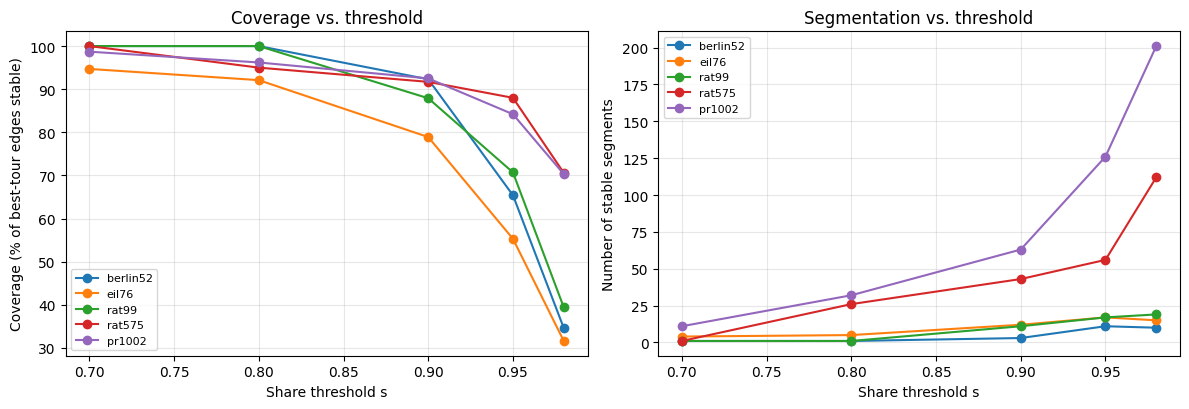

CSV saved: thesis_outputs/tables/stable_sensitivity_all_instances.csv
 threshold  stable_edges  coverage_%  n_segments  largest_segment instance
      0.70            52       100.0           1               52 berlin52
      0.80            52       100.0           1               52 berlin52
      0.90            48        92.3           3               28 berlin52
      0.95            34        65.4          11               13 berlin52
      0.98            18        34.6          10                5 berlin52
      0.70            72        94.7           4               48    eil76
      0.80            70        92.1           5               31    eil76
      0.90            60        78.9          12               18    eil76
      0.95            42        55.3          17                9    eil76
      0.98            24        31.6          15                4    eil76
      0.70            99       100.0           1               99    rat99
      0.80            99      

In [ ]:
# Stable-subpath threshold sensitivity — combined cross-instance figure.
# Reads the per-instance CSVs written by run_explanations, so it also works
# after a session restart (no recomputation needed).

EXPL_INSTANCES_SENS = ['berlin52', 'eil76', 'rat99', 'rat575', 'pr1002']
sens_frames = {}
for nm in EXPL_INSTANCES_SENS:
    df_tmp = load_csv(f'stable_sensitivity_{nm}.csv', subdir='explanations')
    if df_tmp is not None:
        sens_frames[nm] = df_tmp

if not sens_frames:
    print("No sensitivity CSVs found yet. Run the explanation cells first.")
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for nm, df_s in sens_frames.items():
        axes[0].plot(df_s['threshold'], df_s['coverage_%'],
                     marker='o', label=nm)
        axes[1].plot(df_s['threshold'], df_s['n_segments'],
                     marker='o', label=nm)
    axes[0].set_xlabel('Share threshold s')
    axes[0].set_ylabel('Coverage (% of best-tour edges stable)')
    axes[0].set_title('Coverage vs. threshold')
    axes[0].grid(alpha=0.3); axes[0].legend(fontsize=8)
    axes[1].set_xlabel('Share threshold s')
    axes[1].set_ylabel('Number of stable segments')
    axes[1].set_title('Segmentation vs. threshold')
    axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
    plt.tight_layout()
    save_fig('fig_stable_threshold_sensitivity.png')
    plt.show()

    combined = pd.concat([d.assign(instance=nm) for nm, d in sens_frames.items()],
                         ignore_index=True)
    save_csv(combined, 'stable_sensitivity_all_instances.csv')
    print(combined.to_string(index=False))


## 14. Final Summary and LaTeX Table Export

In [ ]:
if 'df_results' not in dir():
    df_results = load_csv('table_pure_vs_memetic.csv')   # session-restart fallback
print("\nFINAL RESULTS SUMMARY (seed=42)")
print("="*78)
print(df_results[['instance','n_cities','best_known','pure_GA','pure_gap_%',
                  'memetic_GA','memetic_gap_%','2opt_type']].to_string(index=False))
if 'multi_results' in dir() and multi_results:
    print("\nROBUSTNESS (mean ± SD over runs, seeds %s–%s)" % (SEEDS[0], SEEDS[-1]))
    for name in INSTANCES:
        for alg in ['pure', 'memetic']:
            d = multi_results.get((name, alg))
            if d:
                lbl = 'Pure GA   ' if alg == 'pure' else 'Memetic GA'
                print(f"  {name:<10} {lbl}: {np.mean(d['gaps']):6.2f}% ± "
                      f"{np.std(d['gaps']):.2f}%")



FINAL RESULTS SUMMARY (seed=42)
instance  n_cities  best_known  pure_GA  pure_gap_%  memetic_GA  memetic_gap_%           2opt_type
berlin52        52        7542     8114        7.58        7542           0.00                full
   eil76        76         538      573        6.51         538           0.00                full
   rat99        99        1211     1480       22.21        1211           0.00                full
 kroA100       100       21282    23743       11.56       21287           0.02                full
 kroA200       200       29368    44447       51.35       29368           0.00 neighbour-list k=15
   rd400       400       15281    35806      134.32       15287           0.04 neighbour-list k=15
  rat575       575        6773    20434      201.70        6777           0.06 neighbour-list k=15
  pr1002      1002      259045  1438190      455.19      260141           0.42 neighbour-list k=15

ROBUSTNESS (mean ± SD over runs, seeds 10–19)
  berlin52   Pure GA   :   8.

In [ ]:
# Export thesis tables as LaTeX (booktabs) into thesis_outputs/tables/
LATEX_TABLES = [
    ('per_instance_best_configs.csv',    'tab_per_instance_configs.tex'),
    ('table_pure_vs_memetic.csv',        'tab_pure_vs_memetic.tex'),
    ('table_exp_A_selection.csv',        'tab_exp_A_selection.tex'),
    ('table_exp_B_crossover.csv',        'tab_exp_B_crossover.tex'),
    ('table_robustness.csv',             'tab_robustness.tex'),
    ('cross_instance_explanation.csv',   'tab_cross_instance.tex'),
    ('contrastive_nearopt_berlin52.csv', 'tab_contrastive_berlin52.tex'),
    ('edge_importance_berlin52.csv',     'tab_edge_importance_berlin52.tex'),
    ('stable_segments_berlin52.csv',     'tab_stable_segments_berlin52.tex'),
    ('stable_sensitivity_all_instances.csv', 'tab_stable_sensitivity.tex'),
]
for csv_name, tex_name in LATEX_TABLES:
    df = load_csv(csv_name)
    if df is None:
        print(f"  skipped (missing): {csv_name}")
        continue
    if 'contrastive' in csv_name:
        df = df.head(10)
    if 'edge_importance' in csv_name:
        df = df.head(10)
    tex = df.to_latex(index=False, escape=True, na_rep='--',
                      bold_rows=False, float_format='%.2f')
    # pandas >=1.0 to_latex uses booktabs only via styler; add rules manually
    tex = (tex.replace('\\toprule', '\\toprule')
              .replace('hline', 'midrule') if '\\toprule' in tex else tex)
    path = _local_path(tex_name, 'tables')
    with open(path, 'w') as f:
        f.write(tex)
    print(f"  LaTeX saved: {path}")


  LaTeX saved: thesis_outputs/tables/tab_per_instance_configs.tex
  LaTeX saved: thesis_outputs/tables/tab_pure_vs_memetic.tex
  LaTeX saved: thesis_outputs/tables/tab_exp_A_selection.tex
  LaTeX saved: thesis_outputs/tables/tab_exp_B_crossover.tex
  LaTeX saved: thesis_outputs/tables/tab_robustness.tex
  LaTeX saved: thesis_outputs/tables/tab_cross_instance.tex
  LaTeX saved: thesis_outputs/tables/tab_contrastive_berlin52.tex
  LaTeX saved: thesis_outputs/tables/tab_edge_importance_berlin52.tex
  LaTeX saved: thesis_outputs/tables/tab_stable_segments_berlin52.tex
  LaTeX saved: thesis_outputs/tables/tab_stable_sensitivity.tex


## 15. Reproducibility Summary

In [ ]:
REPRO = [
    ('Per-instance configs',          'Sec 6',  'tables/per_instance_best_configs.csv'),
    ('Grid heatmaps (all instances)', 'Sec 6.1','figures/fig_grid_search_heatmaps_all_instances.png'),
    ('Experiment A table',            'Sec 7',  'tables/table_exp_A_selection.csv'),
    ('Experiment B table',            'Sec 8',  'tables/table_exp_B_crossover.csv'),
    ('Pure vs Memetic table',         'Sec 9',  'tables/table_pure_vs_memetic.csv'),
    ('Convergence pure-vs-memetic',   'Sec 9.2','figures/fig_berlin52_convergence_pure_vs_memetic.png'),
    ('Robustness table',              'Sec 10', 'tables/table_robustness.csv'),
    ('Contrastive berlin52',          'Sec 12', 'tables/contrastive_nearopt_berlin52.csv'),
    ('Diverse tours berlin52',        'Sec 12', 'figures/fig_berlin52_diverse_tours.png'),
    ('Stable segments berlin52',      'Sec 12', 'tables/stable_segments_berlin52.csv'),
    ('Cross-instance summary',        'Sec 13', 'tables/cross_instance_explanation.csv'),
]
rows = []
for item, sec, rel in REPRO:
    local = f'thesis_outputs/{rel.split("/",1)[0]}/{rel.split("/",1)[1]}'
    rows.append({'Thesis item': item, 'Section': sec, 'Output file': local,
                 'Status': 'exists' if os.path.exists(local) else 'missing'})
df_repro = pd.DataFrame(rows)
df_repro['Timestamp'] = datetime.datetime.now().isoformat()
print(df_repro[['Thesis item','Section','Status','Output file']].to_string(index=False))
save_csv(df_repro, 'reproducibility_summary.csv', subdir='tables')

print(f"\nEnvironment: Python {sys.version.split()[0]} | numpy {np.__version__} | "
      f"pandas {pd.__version__} | Numba: {NUMBA_AVAILABLE} | cores: {N_CORES}")
print(f"SEED={SEED} | SEEDS={SEEDS} | QUICK_TEST={QUICK_TEST} | RUN_HEAVY={RUN_HEAVY}")


                  Thesis item Section  Status                                                         Output file
         Per-instance configs   Sec 6  exists                 thesis_outputs/tables/per_instance_best_configs.csv
Grid heatmaps (all instances) Sec 6.1  exists   thesis_outputs/figures/fig_grid_search_heatmaps_all_instances.png
           Experiment A table   Sec 7 missing                     thesis_outputs/tables/table_exp_A_selection.csv
           Experiment B table   Sec 8 missing                     thesis_outputs/tables/table_exp_B_crossover.csv
        Pure vs Memetic table   Sec 9  exists                     thesis_outputs/tables/table_pure_vs_memetic.csv
  Convergence pure-vs-memetic Sec 9.2  exists thesis_outputs/figures/fig_berlin52_convergence_pure_vs_memetic.png
             Robustness table  Sec 10  exists                          thesis_outputs/tables/table_robustness.csv
         Contrastive berlin52  Sec 12  exists              thesis_outputs/tables/contras